# GreenBasket Delivery Failure Prediction

## Problem Definition

GreenBasket Grocers delivers roughly 85,000 grocery orders daily across 14 metropolitan markets. About 8–10% fail because of address issues, customer unavailability, perishables, or payment problems, creating an estimated $150,000–$200,000 in daily direct losses and eroding customer trust.

The objective is to predict **`delivery_failed`** at order placement from customer history, address, order, payment, slot, and operational features. The resulting risk score will let operations prioritize confirmation calls, prepaid-payment nudges, priority routing, and slot reassignment for high-risk orders rather than intervening on every delivery.

### Install and Import the Necessary Libraries

In [60]:
# Install only packages that are not already available in the active kernel.
import importlib.util
import subprocess
import sys

# Define a dictionary of required packages with their corresponding module names
required_packages = {
    'pandas': 'pandas',
    'numpy': 'numpy',
    'sklearn': 'scikit-learn',
    'tensorflow': 'tensorflow',
    'keras': 'keras',
    'xgboost': 'xgboost',
    'seaborn': 'seaborn',
    'matplotlib': 'matplotlib',
    'scipy': 'scipy',
    'shap': 'shap',
}

missing = [package for module, package in required_packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
    print(f'Installed missing packages: {", ".join(missing)}')
else:
    print('All required packages are already installed.')

All required packages are already installed.


In [61]:
# Standard libraries for tracking execution time and vector/matrix operations
import time
import pandas as pd
import numpy as np

# Data manipulation and visualization libraries, Tree-based and ensemble machine learning classifiers, and deep learning frameworks
import sklearn
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score         # Utilities for splitting datasets, hyperparameter tuning, and cross-validation
from sklearn.preprocessing import OneHotEncoder, StandardScaler                                   # Preprocessing tools for scaling data and encoding categorical variables
from sklearn.compose import ColumnTransformer                                                     # Utility for applying different preprocessing steps to different columns in a dataset
from sklearn.pipeline import Pipeline
from sklearn.utils.class_weight import compute_class_weight                                       # Utility for handling class imbalance   
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score, 
                             classification_report, confusion_matrix, ConfusionMatrixDisplay, 
                             roc_auc_score)                                                       # Utilities for model evaluation and metric calculations
from sklearn.inspection import permutation_importance


# Tree-based and ensemble machine learning classifiers   
import tensorflow as tf                                      # Deep learning framework for building and training neural networks
from tensorflow import keras                                 # High-level API for building and training deep learning models
from keras.models import Sequential                          # Model for building neural networks sequentially
from keras.layers import Dense, Dropout, BatchNormalization  # Specific layers for building Artificial Neural Networks (ANNs)
import xgboost as xgb

# Data visualization libraries for creating plots and visual representations of data
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from scipy import stats
import shap

# Configuration settings for reproducibility and display options
RANDOM_STATE = 53                              # Set a fixed random state for reproducibility of results
pd.set_option('display.max_columns', None)     # Prevent truncation of columns when displaying dataframes
print('Imports complete.')


# Configuration settings to suppress warnings and format data display outputs
import warnings
warnings.filterwarnings('ignore')              # Suppress warnings for cleaner output logs
sns.set_theme(style='whitegrid', context='notebook')  # Set a consistent clean style for plots
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold', 'axes.labelsize': 11})
pd.set_option('display.max_columns', None)     # Prevent truncation of columns when displaying dataframes



Imports complete.


## Data Loading and Overview

Load the raw delivery data and inspect its structure and quality before preprocessing.

In [62]:
from pathlib import Path

# Support running the notebook from either the project root or notebooks/.
data_file = 'greenbasket_deliveries.csv'
candidate_paths = [
    Path('data') / 'raw' / data_file,
    Path('..') / 'data' / 'raw' / data_file,
]
data_path = next((path for path in candidate_paths if path.exists()), None)
if data_path is None:
    raise FileNotFoundError(f'Could not find {data_file} in data/raw/.')

df = pd.read_csv(data_path)

print(f'Dataset loaded from: {data_path}')
print(f'\nDataset shape: {df.shape}')

print('\nFirst 5 rows:')
display(df.head())                      # Display the first 5 rows of the dataset to get an initial overview of the data

print('\nLast 5 rows:')
display(df.tail())                      # Display the last 5 rows of the dataset to check for any anomalies or patterns at the end of the data

print('\nDataset attributes:')
df.info()                               # Display information about the dataset, including column names, data types, and non-null counts

print('\nStatistical summary:')
display(df.describe(include='all').T)   # Display a statistical summary of the dataset, including count, mean, standard deviation, min, max, and quartiles for numerical columns, and unique counts for categorical columns

print('\nMissing values by column:')
display(df.isna().sum().to_frame(name='missing_values'))    # Display the count of missing values for each column in the dataset

print(f'\nDuplicate rows: {df.duplicated().sum()}')        # Display the count of duplicate rows in the dataset

Dataset loaded from: ..\data\raw\greenbasket_deliveries.csv

Dataset shape: (45000, 32)

First 5 rows:


,order_id,order_timestamp,customer_id,customer_tenure_days,past_order_count,past_failure_count,past_failure_rate,avg_past_order_value_usd,days_since_last_order,delivery_city,delivery_pin_code,is_new_address,address_type,floor_number,distance_from_darkstore_km,pin_code_failure_rate,order_value_usd,num_items,num_perishable_items,num_frozen_items,has_alcohol,payment_mode,discount_applied_pct,delivery_slot,day_of_week,is_weekend,lead_time_hours,partner_current_load,darkstore_utilization_pct,weather_condition,temperature_f,delivery_failed
0,ORD2524162,2025-04-01 14:03:00,CUST111409,224,0,0,0.1,NaN,NaN,Charlotte,73083,1,house,0,6.93,0.1,21.81,2,0,0,0,prepaid_wallet,6.8,afternoon,Tuesday,0,6.8,17.0,64.1,rain,92.7,0
1,ORD2502025,2025-04-01 14:05:00,CUST100693,866,0,0,0.1,NaN,NaN,Tampa,73106,0,apartment,21,3.93,0.1,56.32,12,9,1,0,prepaid_wallet,2.4,afternoon,Tuesday,0,1.0,14.0,53.5,cloudy,60.3,0
2,ORD2526121,2025-04-01 14:05:00,CUST101525,203,0,0,0.1,NaN,NaN,Salt Lake City,73172,0,apartment,4,3.16,0.1,62.47,12,1,0,0,prepaid_card,7.0,afternoon,Tuesday,0,14.7,4.0,62.1,clear,59.5,0
3,ORD2504522,2025-04-01 14:05:00,CUST106125,735,0,0,0.1,NaN,NaN,Tampa,73111,1,apartment,5,3.84,0.1,80.75,15,1,3,0,prepaid_card,3.9,afternoon,Tuesday,0,3.7,12.0,56.4,clear,69.6,0
4,ORD2532631,2025-04-01 14:07:00,CUST102017,571,0,0,0.1,NaN,NaN,Nashville,73093,0,apartment,16,3.07,0.1,35.13,8,4,0,0,prepaid_wallet,0.8,afternoon,Tuesday,0,1.0,13.0,55.2,clear,62.9,0



Last 5 rows:


,order_id,order_timestamp,customer_id,customer_tenure_days,past_order_count,past_failure_count,past_failure_rate,avg_past_order_value_usd,days_since_last_order,delivery_city,delivery_pin_code,is_new_address,address_type,floor_number,distance_from_darkstore_km,pin_code_failure_rate,order_value_usd,num_items,num_perishable_items,num_frozen_items,has_alcohol,payment_mode,discount_applied_pct,delivery_slot,day_of_week,is_weekend,lead_time_hours,partner_current_load,darkstore_utilization_pct,weather_condition,temperature_f,delivery_failed
44995,ORD2510524,2025-05-16 04:48:00,CUST100634,963,3,1,0.1875,28.22,18.56,Nashville,73098,0,apartment,8,4.44,0.0963,96.01,14,1,2,0,cash_on_delivery,4.1,morning,Friday,0,1.8,4.0,70.9,clear,82.2,0
44996,ORD2507189,2025-05-16 04:54:00,CUST110532,157,3,1,0.1875,22.72,8.16,Atlanta,73066,1,other,0,2.73,0.0614,18.10,3,1,0,0,prepaid_card,3.6,morning,Friday,0,5.4,8.0,72.1,cloudy,71.0,0
44997,ORD2526287,2025-05-16 04:57:00,CUST104841,712,3,1,0.1875,39.09,0.16,Nashville,73093,0,apartment,10,2.60,0.0586,90.81,14,10,0,0,prepaid_card,4.4,morning,Friday,0,1.1,8.0,81.9,clear,75.5,0
44998,ORD2535012,2025-05-16 04:57:00,CUST106051,401,5,0,0.0500,45.93,10.51,Austin,73002,0,house,0,3.04,0.0687,53.23,11,2,1,0,prepaid_card,0.4,morning,Friday,0,1.4,6.0,65.4,clear,55.0,0
44999,ORD2506795,2025-05-16 04:58:00,CUST108832,70,8,1,0.1154,43.23,7.52,Salt Lake City,73177,0,apartment,2,3.45,0.0582,75.03,10,0,0,0,cash_on_delivery,0.1,morning,Friday,0,7.5,7.0,69.2,clear,52.2,0



Dataset attributes:
<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 32 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   order_id                    45000 non-null  str    
 1   order_timestamp             45000 non-null  str    
 2   customer_id                 45000 non-null  str    
 3   customer_tenure_days        45000 non-null  int64  
 4   past_order_count            45000 non-null  int64  
 5   past_failure_count          45000 non-null  int64  
 6   past_failure_rate           45000 non-null  float64
 7   avg_past_order_value_usd    34493 non-null  float64
 8   days_since_last_order       34493 non-null  float64
 9   delivery_city               45000 non-null  str    
 10  delivery_pin_code           45000 non-null  int64  
 11  is_new_address              45000 non-null  int64  
 12  address_type                45000 non-null  str    
 13  floor_number         

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,45000,45000,ORD2524162,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_timestamp,45000,24456,2025-04-06 23:19:00,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_id,45000,10507,CUST100510,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_tenure_days,45000.0,NaN,NaN,NaN,617.6308,339.813671,15.0,331.0,624.0,912.0,1199.0
past_order_count,45000.0,NaN,NaN,NaN,2.868689,3.099343,0.0,1.0,2.0,4.0,31.0
past_failure_count,45000.0,NaN,NaN,NaN,0.255422,0.601157,0.0,0.0,0.0,0.0,9.0
past_failure_rate,45000.0,NaN,NaN,NaN,0.09673,0.054026,0.0156,0.0625,0.0833,0.1,0.55
avg_past_order_value_usd,34493.0,NaN,NaN,NaN,42.400836,17.229991,8.0,31.68,40.02,49.8,299.98
days_since_last_order,34493.0,NaN,NaN,NaN,6.598057,6.737811,0.0,1.85,4.37,9.03,44.22
delivery_city,45000,14,Atlanta,4043,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing values by column:


,missing_values
order_id,0
order_timestamp,0
customer_id,0
customer_tenure_days,0
past_order_count,0
past_failure_count,0
past_failure_rate,0
avg_past_order_value_usd,10507
days_since_last_order,10507
delivery_city,0



Duplicate rows: 0


In [63]:
# Save a structured audit report for use outside the notebook.
from io import StringIO

project_root = data_path.parents[2]
output_dir = project_root / 'outputs'
figures_dir = output_dir / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)

info_buffer = StringIO()
df.info(buf=info_buffer)
missing_values = df.isna().sum().to_frame(name='missing_values')
statistical_summary = df.describe(include='all').T

quality_report = (
    'GREENBASKET RAW DATA QUALITY REPORT\n'
    + '=' * 38 + '\n\n'
    + 'DATA SHAPE\n' + '-' * 10 + f'\nRows: {df.shape[0]:,}\nColumns: {df.shape[1]}\n\n'
    + 'DATASET ATTRIBUTES\n' + '-' * 18 + '\n' + info_buffer.getvalue() + '\n'
    + 'STATISTICAL SUMMARY\n' + '-' * 19 + '\n' + statistical_summary.to_string() + '\n\n'
    + 'MISSING VALUES\n' + '-' * 14 + '\n' + missing_values.to_string() + '\n\n'
    + 'DUPLICATE VALUES\n' + '-' * 16 + f'\nDuplicate rows: {df.duplicated().sum()}\n'
)

quality_report_path = output_dir / 'raw_data_quality_report.txt'
quality_report_path.write_text(quality_report, encoding='utf-8')
print(f'Raw data quality report saved to: {quality_report_path}')

Raw data quality report saved to: ..\outputs\raw_data_quality_report.txt


#### Data-quality observations

- The raw dataset contains **45,000 rows and 32 columns**. The preprocessing section subsequently adds two temporal features: `order_day_of_week` and `order_hour`.
- There are **no duplicate rows**. Missing values are concentrated in `avg_past_order_value_usd` and `days_since_last_order` (10,507 each), while `partner_current_load`, `darkstore_utilization_pct`, and `temperature_f` have comparatively few missing values.
- The detailed shape, attributes, descriptive statistics, missing-value counts, and duplicate-row audit are exported to `outputs/raw_data_quality_report.txt` when the preceding cell is run.

## Data Preprocessing

Convert the order timestamp to a datetime field and derive temporal features for time-based EDA and modeling.

In [64]:
# Convert order_timestamp to datetime; invalid timestamps are recorded as missing values.
df['order_timestamp'] = pd.to_datetime(df['order_timestamp'], errors='coerce')

# Derive temporal features for weekly and hourly pattern analysis.
df['order_day_of_week'] = df['order_timestamp'].dt.dayofweek
df['order_hour'] = df['order_timestamp'].dt.hour

print(f"order_timestamp data type: {df['order_timestamp'].dtype}")
print(f"Unparsed order timestamps: {df['order_timestamp'].isna().sum()}")
display(df[['order_timestamp', 'order_day_of_week', 'order_hour']].head())

order_timestamp data type: datetime64[us]
Unparsed order timestamps: 0


,order_timestamp,order_day_of_week,order_hour
0,2025-04-01 14:03:00,1,14
1,2025-04-01 14:05:00,1,14
2,2025-04-01 14:05:00,1,14
3,2025-04-01 14:05:00,1,14
4,2025-04-01 14:07:00,1,14


## Exploratory Data Analysis

### EDA Utility Functions

Reusable functions for inspecting categorical and numerical distributions.

In [65]:
def save_figure(filename):
    """Save the current Matplotlib figure in the project's output directory."""
    figure_path = figures_dir / filename
    plt.savefig(figure_path, dpi=300, bbox_inches='tight')
    print(f'Figure saved to: {figure_path}')


def plot_histogram(data, column, bins=50, title=None, xlabel=None, filename=None):
    """Plot a histogram with a kernel density estimate for a numerical column."""
    plt.figure(figsize=(9, 4))
    sns.histplot(data=data, x=column, bins=bins, kde=True, color='steelblue')
    plt.title(title or f'Distribution of {column}')
    plt.xlabel(xlabel or column)
    plt.ylabel('Count')
    plt.tight_layout()
    if filename:
        save_figure(filename)
    plt.show()


def plot_bar_chart(data, column, title=None, xlabel=None, filename=None):
    """Plot count and percentage labels for a categorical column."""
    counts = data[column].value_counts(dropna=False)
    plt.figure(figsize=(10, 6))
    ax = sns.barplot(x=counts.index.astype(str), y=counts.values, color='teal')
    for bar, count in zip(ax.patches, counts.values):
        percentage = count / len(data) * 100
        ax.annotate(f'{count:,} ({percentage:.1f}%)',
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha='center', va='bottom', fontsize=9)
    plt.title(title or f'Count of {column}')
    plt.xlabel(xlabel or column)
    plt.ylabel('Count')
    plt.tight_layout()
    if filename:
        save_figure(filename)
    plt.show()


def plot_boxplot(data, column, title=None, xlabel=None, filename=None):
    """Plot a boxplot for a numerical column to highlight spread and outliers."""
    plt.figure(figsize=(9, 3.8))
    sns.boxplot(data=data, x=column, color='coral')
    plt.title(title or f'Boxplot of {column}')
    plt.xlabel(xlabel or column)
    plt.tight_layout()
    if filename:
        save_figure(filename)
    plt.show()


def plot_grouped_bar_chart(data, x, y, title, xlabel, ylabel, rot_degrees=45, filename=None):
    """Plot a pre-aggregated metric as a bar chart."""
    plt.figure(figsize=(10, 6))
    ax = sns.barplot(data=data, x=x, y=y, color='mediumpurple')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if 'Rate (%)' in ylabel:
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    ax.tick_params(axis='x', rotation=rot_degrees)
    plt.tight_layout()
    if filename:
        save_figure(filename)
    plt.show()

### Univariate Analysis

Inspect the distribution of the target variable and selected numerical features.

Figure saved to: ..\outputs\figures\univariate_delivery_failed.png


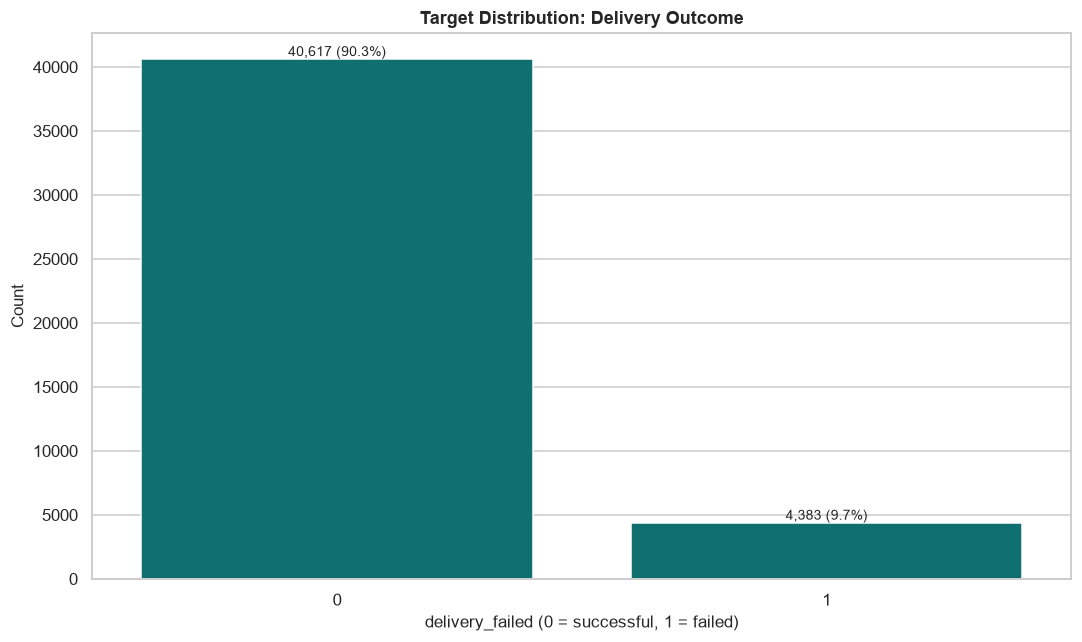

In [66]:
# Delivery-failure target distribution
plot_bar_chart(
    df, 'delivery_failed',
    title='Target Distribution: Delivery Outcome',
    xlabel='delivery_failed (0 = successful, 1 = failed)',
    filename='univariate_delivery_failed.png'
)

Figure saved to: ..\outputs\figures\univariate_past_failure_rate_histogram.png


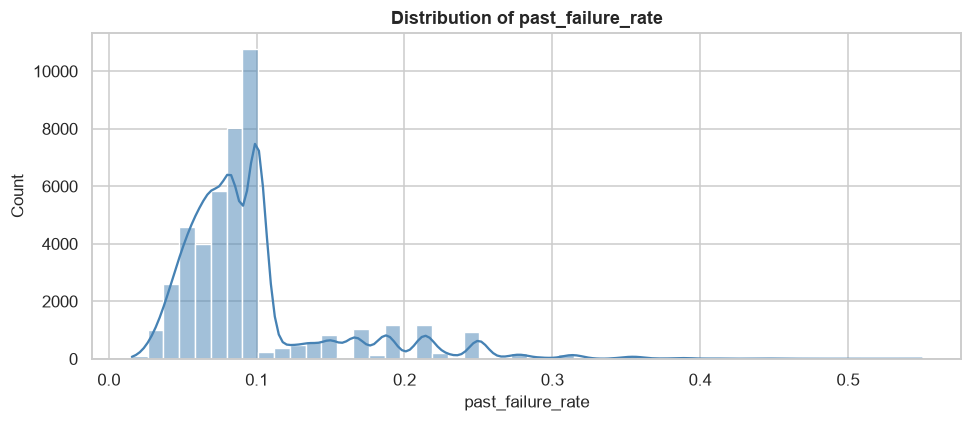

Figure saved to: ..\outputs\figures\univariate_past_failure_rate_boxplot.png


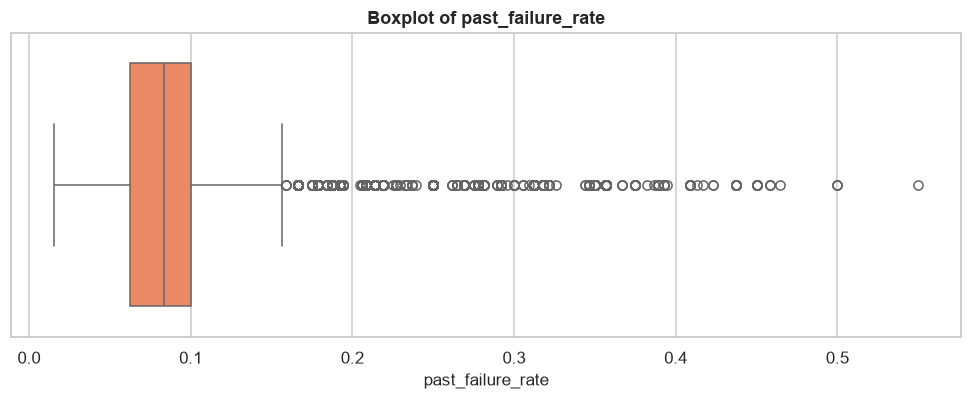

In [67]:
# Historical delivery failure rate
plot_histogram(
    df, 'past_failure_rate',
    title='Distribution of past_failure_rate',
    xlabel='past_failure_rate',
    filename='univariate_past_failure_rate_histogram.png'
)
plot_boxplot(
    df, 'past_failure_rate',
    title='Boxplot of past_failure_rate',
    xlabel='past_failure_rate',
    filename='univariate_past_failure_rate_boxplot.png'
)

Figure saved to: ..\outputs\figures\univariate_pin_code_failure_rate_histogram.png


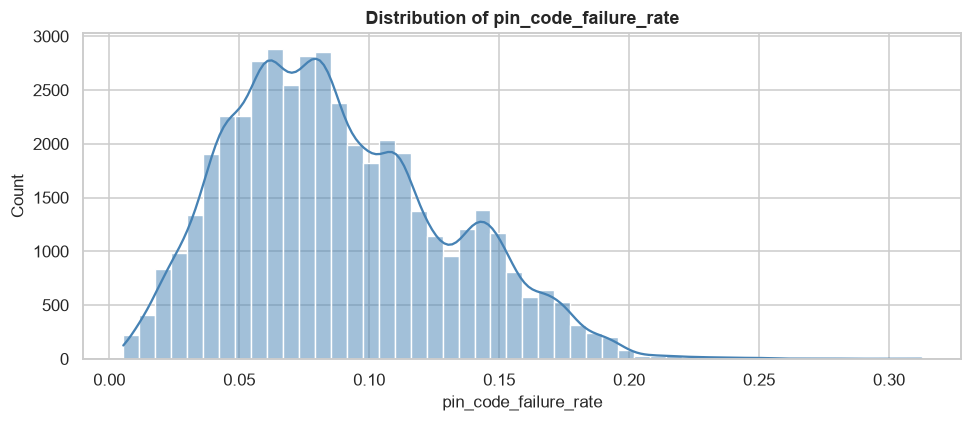

Figure saved to: ..\outputs\figures\univariate_pin_code_failure_rate_boxplot.png


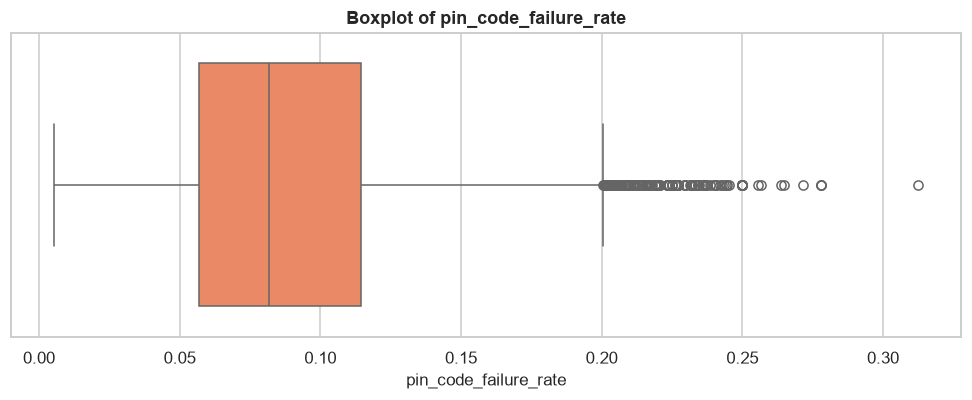

In [68]:
# Historical failure rate for the delivery pin code
plot_histogram(
    df, 'pin_code_failure_rate',
    title='Distribution of pin_code_failure_rate',
    xlabel='pin_code_failure_rate',
    filename='univariate_pin_code_failure_rate_histogram.png'
)
plot_boxplot(
    df, 'pin_code_failure_rate',
    title='Boxplot of pin_code_failure_rate',
    xlabel='pin_code_failure_rate',
    filename='univariate_pin_code_failure_rate_boxplot.png'
)

Figure saved to: ..\outputs\figures\univariate_distance_from_darkstore_km_histogram.png


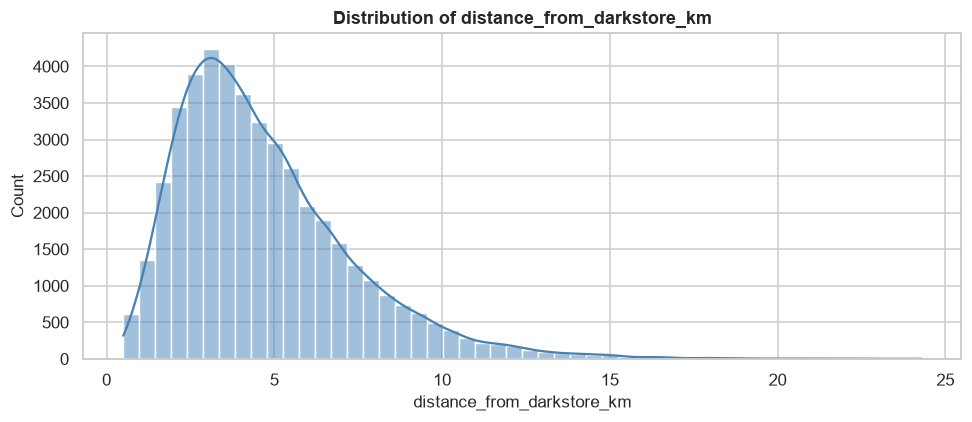

Figure saved to: ..\outputs\figures\univariate_distance_from_darkstore_km_boxplot.png


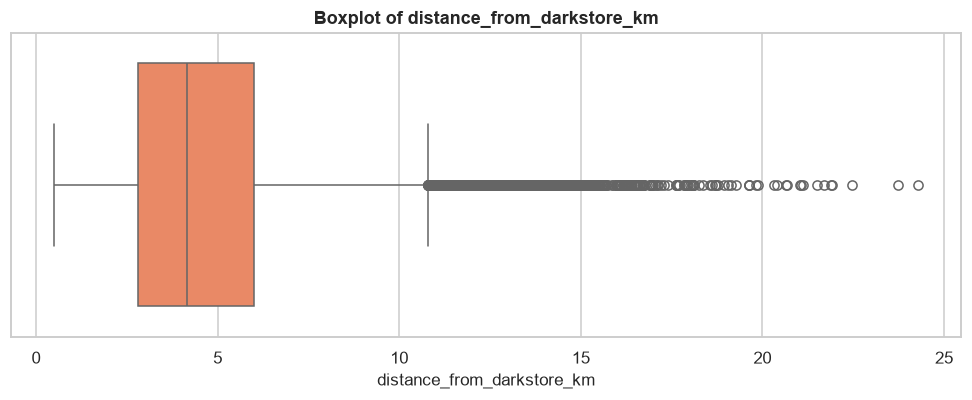

In [69]:
# Delivery distance from the dark store (km)
plot_histogram(
    df, 'distance_from_darkstore_km',
    title='Distribution of distance_from_darkstore_km',
    xlabel='distance_from_darkstore_km',
    filename='univariate_distance_from_darkstore_km_histogram.png'
)
plot_boxplot(
    df, 'distance_from_darkstore_km',
    title='Boxplot of distance_from_darkstore_km',
    xlabel='distance_from_darkstore_km',
    filename='univariate_distance_from_darkstore_km_boxplot.png'
)

Figure saved to: ..\outputs\figures\univariate_order_value_usd_histogram.png


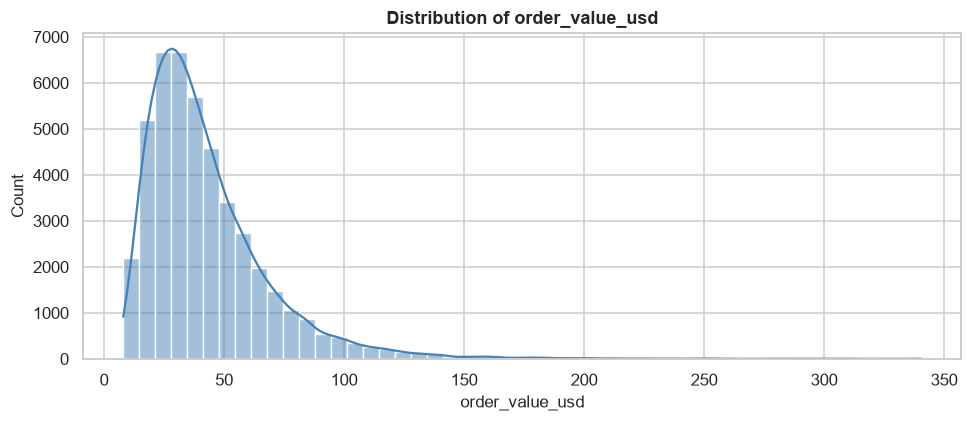

Figure saved to: ..\outputs\figures\univariate_order_value_usd_boxplot.png


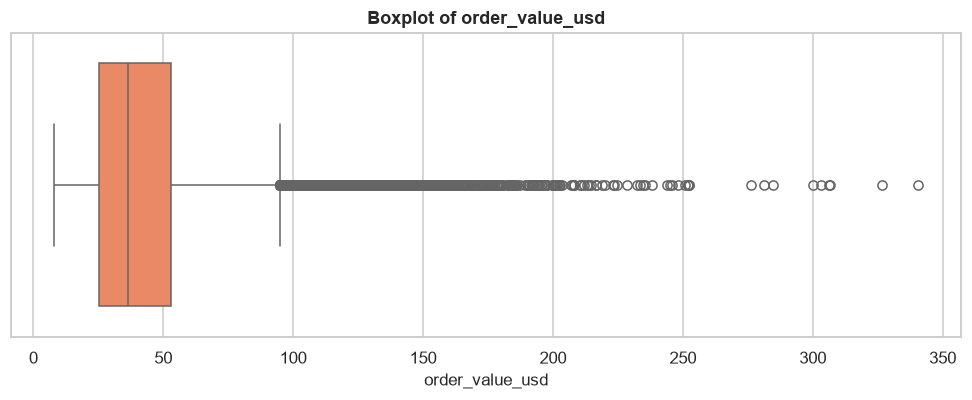

In [70]:
# Order value in USD
plot_histogram(
    df, 'order_value_usd',
    title='Distribution of order_value_usd',
    xlabel='order_value_usd',
    filename='univariate_order_value_usd_histogram.png'
)
plot_boxplot(
    df, 'order_value_usd',
    title='Boxplot of order_value_usd',
    xlabel='order_value_usd',
    filename='univariate_order_value_usd_boxplot.png'
)

Figure saved to: ..\outputs\figures\univariate_avg_past_order_value_usd_histogram.png


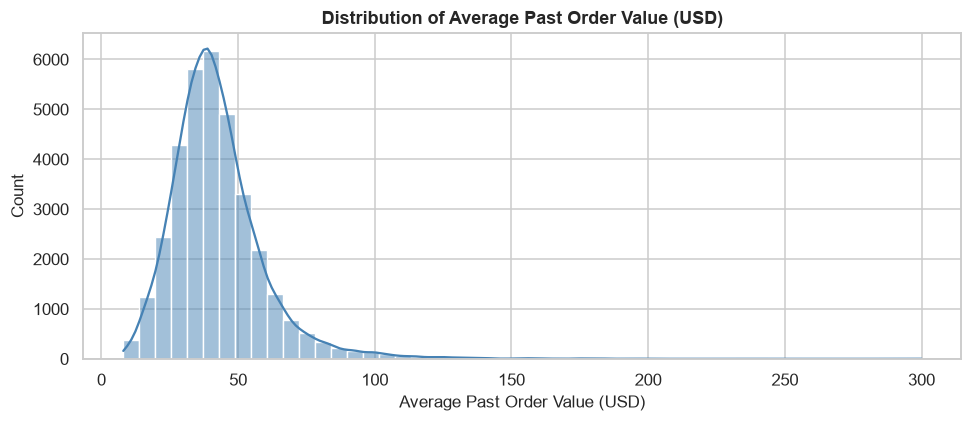

Figure saved to: ..\outputs\figures\univariate_avg_past_order_value_usd_boxplot.png


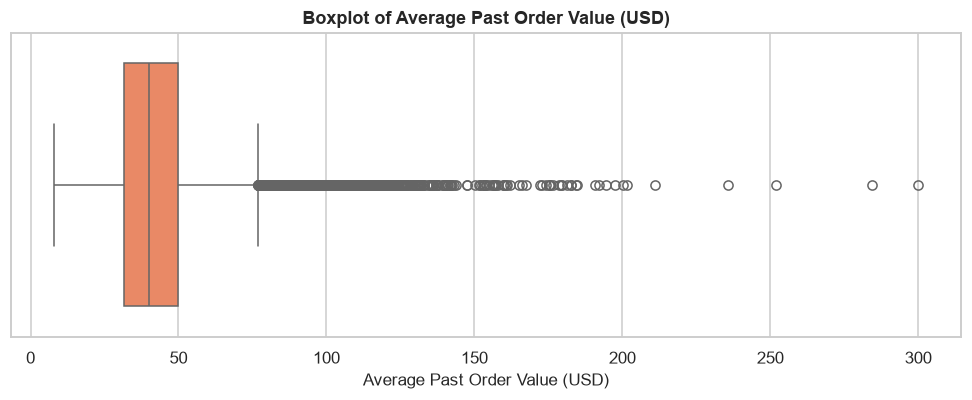

Figure saved to: ..\outputs\figures\univariate_days_since_last_order_histogram.png


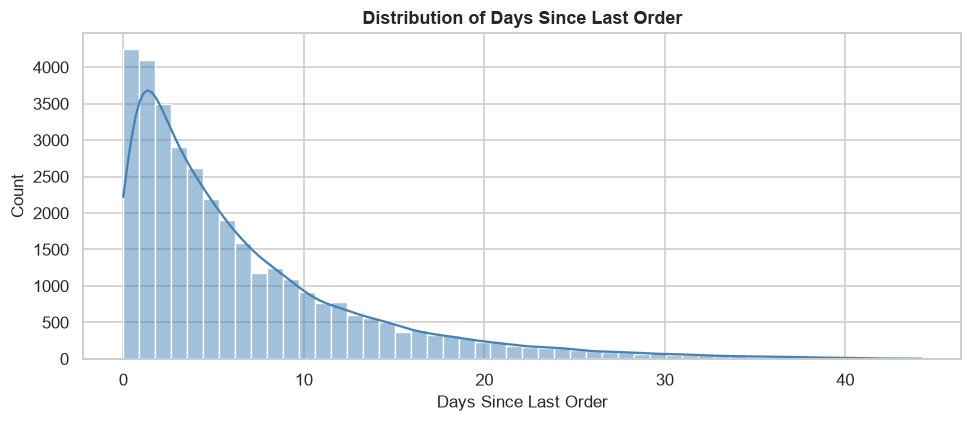

Figure saved to: ..\outputs\figures\univariate_days_since_last_order_boxplot.png


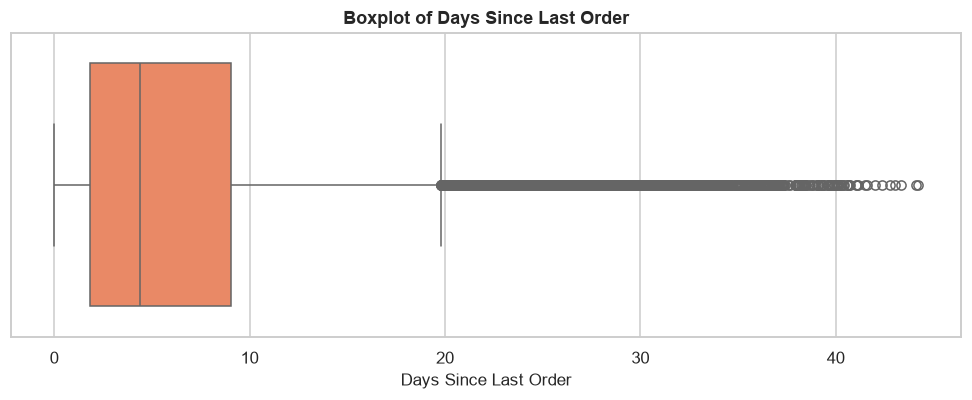

Figure saved to: ..\outputs\figures\univariate_missingness_rate.png


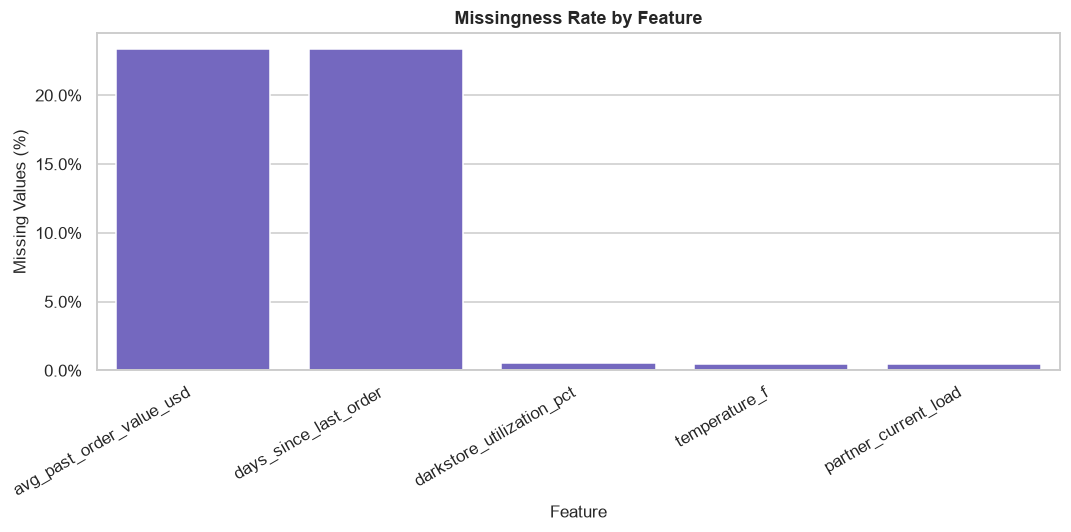

In [71]:
# Additional univariate checks for previously unplotted customer-history and recency features.
for feature, label in [
    ('avg_past_order_value_usd', 'Average Past Order Value (USD)'),
    ('days_since_last_order', 'Days Since Last Order'),
]:
    plot_histogram(df, feature, title=f'Distribution of {label}', xlabel=label,
                   filename=f'univariate_{feature}_histogram.png')
    plot_boxplot(df, feature, title=f'Boxplot of {label}', xlabel=label,
                 filename=f'univariate_{feature}_boxplot.png')

# Missingness itself is an important univariate characteristic.
missingness_summary = (df.isna().mean().mul(100).sort_values(ascending=False)
                       .rename_axis('feature').reset_index(name='missing_pct'))
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=missingness_summary[missingness_summary['missing_pct'] > 0],
                 x='feature', y='missing_pct', color='slateblue')
ax.set(title='Missingness Rate by Feature', xlabel='Feature', ylabel='Missing Values (%)')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
save_figure('univariate_missingness_rate.png')
plt.show()

### Bivariate Analysis

Compare delivery outcomes with time, payment mode, historical failure rate, and delivery distance.

Figure saved to: ..\outputs\figures\bivariate_failure_rate_by_hour.png


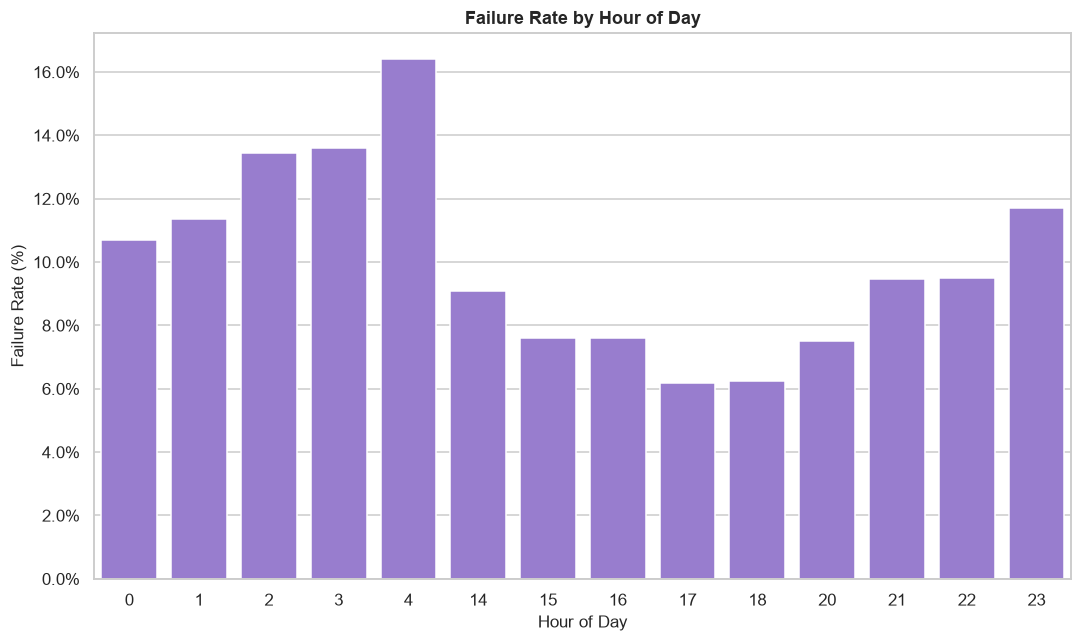

In [72]:
# Mean delivery-failure rate by hour of day
hourly_failure_rate = (
    df.groupby('order_hour', as_index=False)['delivery_failed']
      .mean()
      .assign(failure_rate_pct=lambda data: data['delivery_failed'] * 100)
)

plot_grouped_bar_chart(
    hourly_failure_rate, x='order_hour', y='failure_rate_pct',
    title='Failure Rate by Hour of Day',
    xlabel='Hour of Day', ylabel='Failure Rate (%)', rot_degrees=0,
    filename='bivariate_failure_rate_by_hour.png'
)

Figure saved to: ..\outputs\figures\bivariate_failure_rate_by_payment_mode.png


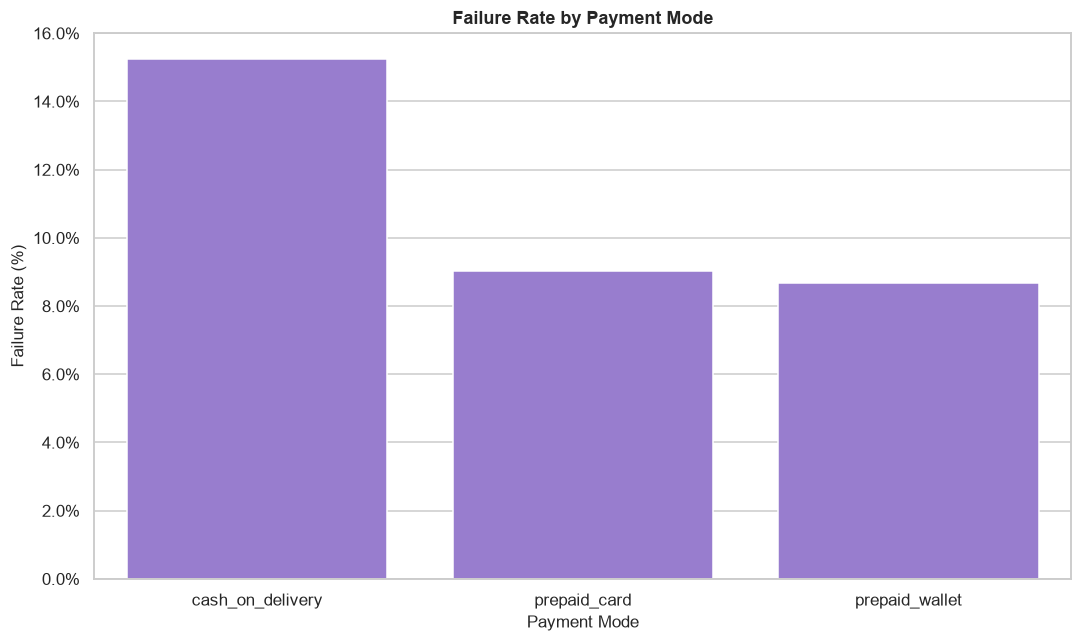

In [73]:
# Mean delivery-failure rate by payment mode
payment_failure_rate = (
    df.groupby('payment_mode', as_index=False)['delivery_failed']
      .mean()
      .assign(failure_rate_pct=lambda data: data['delivery_failed'] * 100)
)

plot_grouped_bar_chart(
    payment_failure_rate, x='payment_mode', y='failure_rate_pct',
    title='Failure Rate by Payment Mode',
    xlabel='Payment Mode', ylabel='Failure Rate (%)', rot_degrees=0,
    filename='bivariate_failure_rate_by_payment_mode.png'
)

Figure saved to: ..\outputs\figures\bivariate_past_failure_rate_by_outcome.png


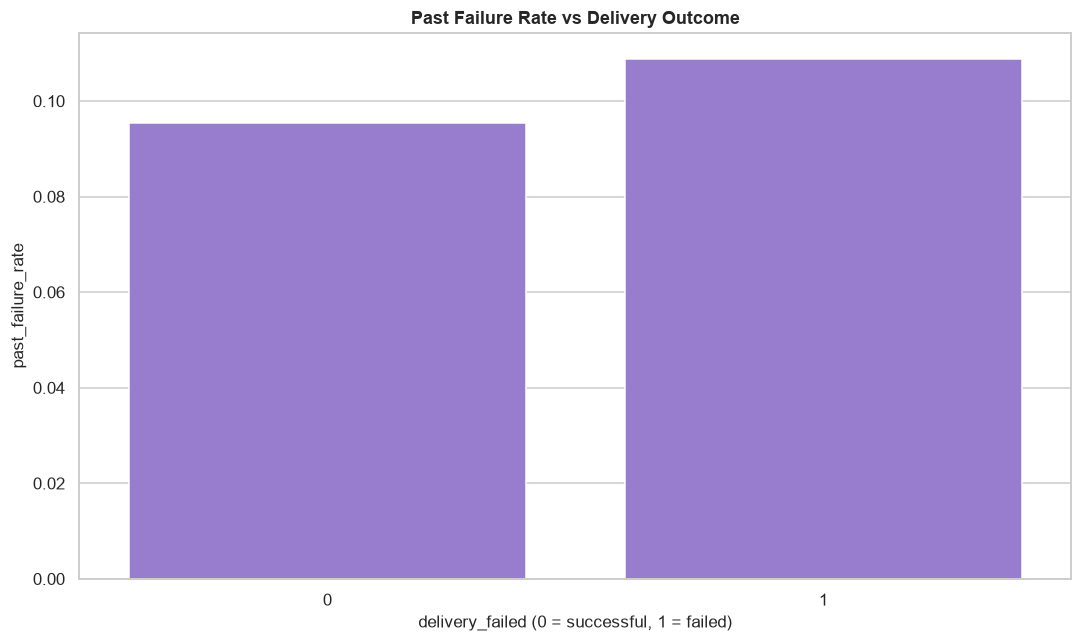

In [74]:
# Average historical failure rate by delivery outcome
past_failure_by_outcome = (
    df.groupby('delivery_failed', as_index=False)['past_failure_rate']
      .mean()
)

plot_grouped_bar_chart(
    past_failure_by_outcome, x='delivery_failed', y='past_failure_rate',
    title='Past Failure Rate vs Delivery Outcome',
    xlabel='delivery_failed (0 = successful, 1 = failed)',
    ylabel='past_failure_rate', rot_degrees=0,
    filename='bivariate_past_failure_rate_by_outcome.png'
)

Figure saved to: ..\outputs\figures\bivariate_distance_by_outcome.png


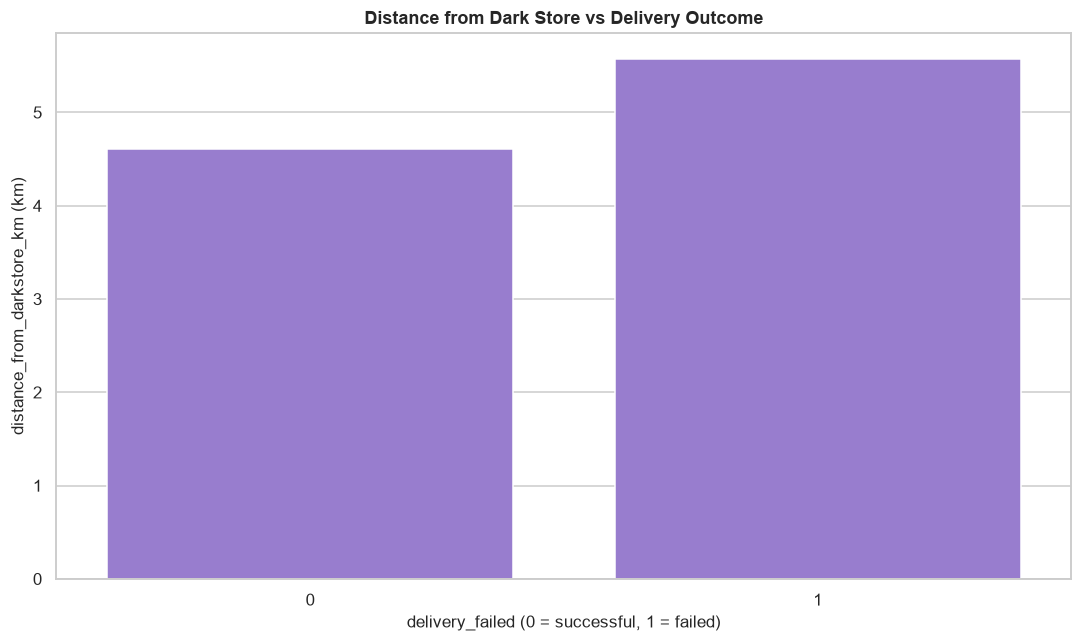

In [75]:
# Average delivery distance by delivery outcome
distance_by_outcome = (
    df.groupby('delivery_failed', as_index=False)['distance_from_darkstore_km']
      .mean()
)

plot_grouped_bar_chart(
    distance_by_outcome, x='delivery_failed', y='distance_from_darkstore_km',
    title='Distance from Dark Store vs Delivery Outcome',
    xlabel='delivery_failed (0 = successful, 1 = failed)',
    ylabel='distance_from_darkstore_km (km)', rot_degrees=0,
    filename='bivariate_distance_by_outcome.png'
)

Figure saved to: ..\outputs\figures\bivariate_failure_by_avg_past_order_value.png


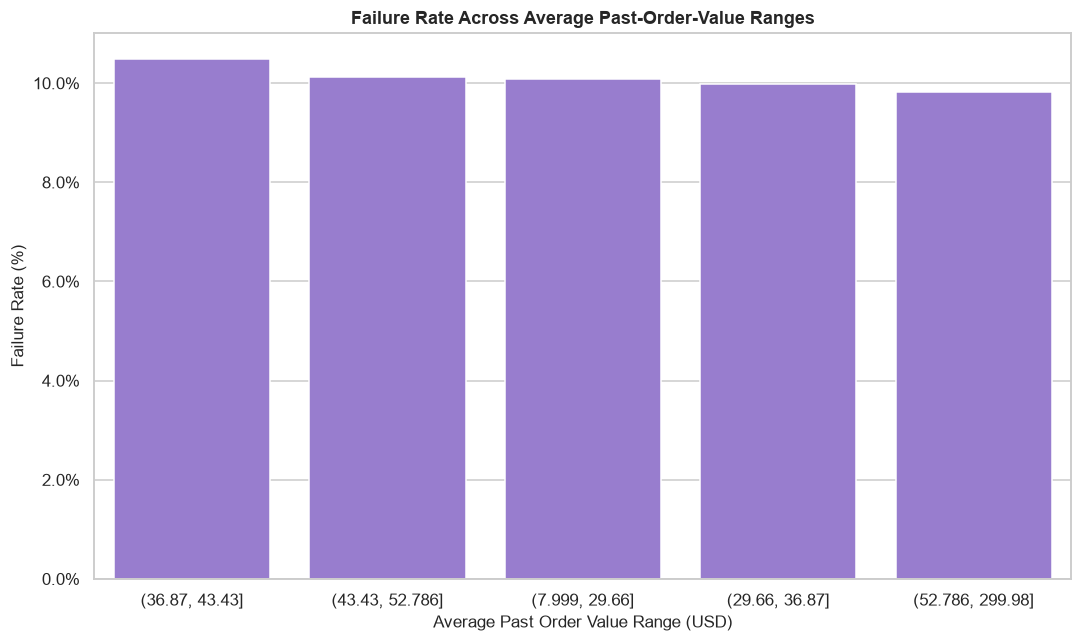

Figure saved to: ..\outputs\figures\bivariate_failure_by_days_since_last_order.png


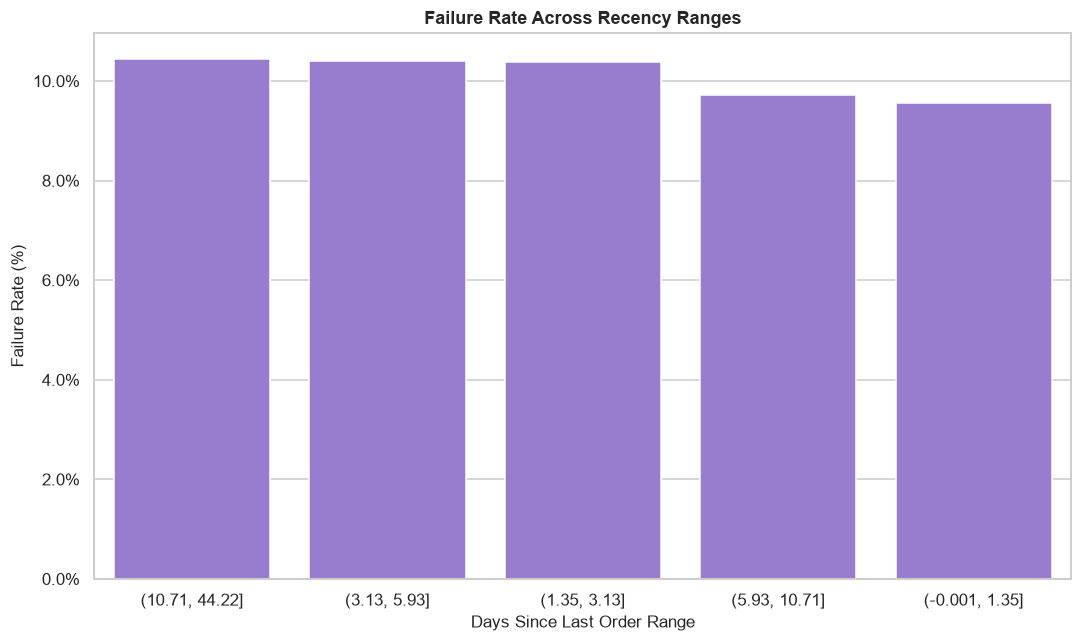

Figure saved to: ..\outputs\figures\bivariate_failure_by_order_value.png


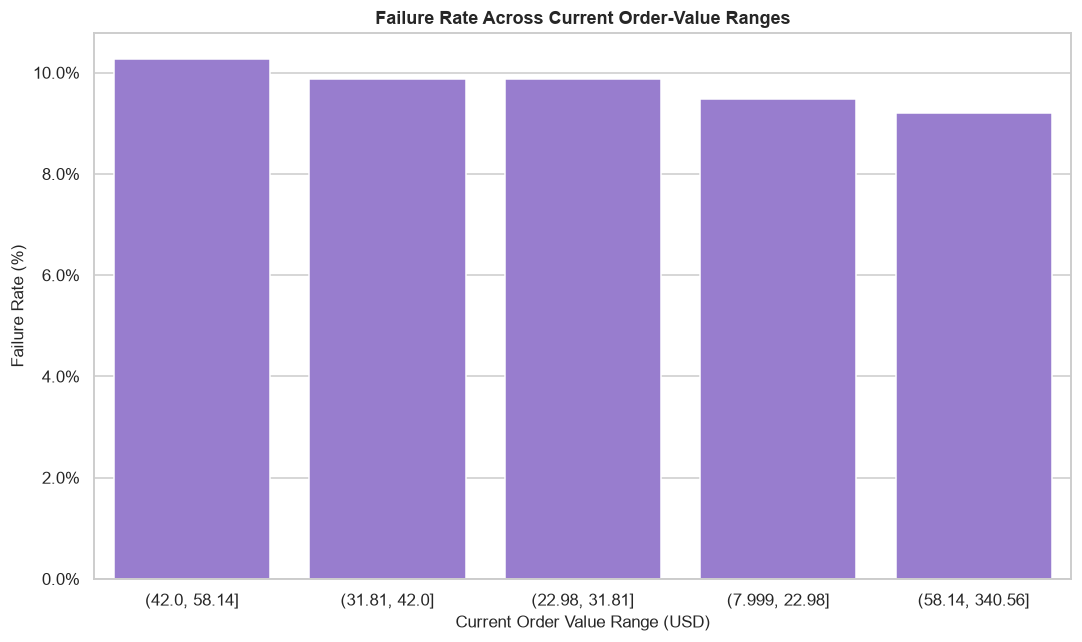

Figure saved to: ..\outputs\figures\multivariate_missingness_by_delivery_outcome.png


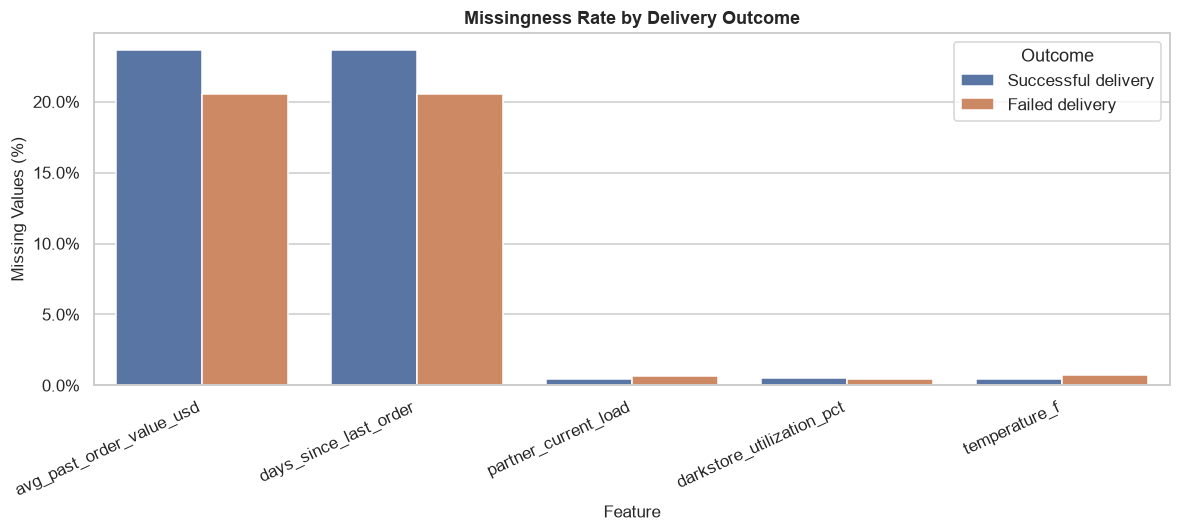

In [76]:
# Define the helper here so this completeness check can run independently.
def plot_failure_rate(data, feature, title, xlabel, filename, bins=None, min_count=None, rotation=0):
    analysis = data[[feature, 'delivery_failed']].dropna().copy()
    plot_feature = feature
    if bins:
        plot_feature = f'{feature}_range'
        analysis[plot_feature] = pd.qcut(analysis[feature], q=bins, duplicates='drop').astype(str)
    summary = (analysis.groupby(plot_feature)['delivery_failed']
               .agg(failure_rate='mean', orders='size').reset_index())
    if min_count:
        summary = summary[summary['orders'] >= min_count]
    summary['failure_rate_pct'] = summary['failure_rate'] * 100
    summary = summary.sort_values('failure_rate_pct', ascending=False)
    plot_grouped_bar_chart(summary, plot_feature, 'failure_rate_pct', title, xlabel,
                           'Failure Rate (%)', rotation, filename)
    return summary

# Additional feature-to-target comparisons for value, recency, and missingness signal.
for feature, title, label, filename in [
    ('avg_past_order_value_usd', 'Failure Rate Across Average Past-Order-Value Ranges', 'Average Past Order Value Range (USD)', 'bivariate_failure_by_avg_past_order_value.png'),
    ('days_since_last_order', 'Failure Rate Across Recency Ranges', 'Days Since Last Order Range', 'bivariate_failure_by_days_since_last_order.png'),
    ('order_value_usd', 'Failure Rate Across Current Order-Value Ranges', 'Current Order Value Range (USD)', 'bivariate_failure_by_order_value.png'),
]:
    plot_failure_rate(df, feature, title, label, filename, bins=5)

missingness_by_target = pd.DataFrame({
    feature: df.groupby('delivery_failed')[feature].apply(lambda values: values.isna().mean() * 100)
    for feature in ['avg_past_order_value_usd', 'days_since_last_order',
                    'partner_current_load', 'darkstore_utilization_pct', 'temperature_f']
}).T.rename(columns={0: 'Successful delivery', 1: 'Failed delivery'}).rename_axis('feature').reset_index()

missingness_long = missingness_by_target.melt(id_vars='feature', var_name='delivery_outcome', value_name='missing_pct')
plt.figure(figsize=(11, 5))
ax = sns.barplot(data=missingness_long, x='feature', y='missing_pct', hue='delivery_outcome')
ax.set(title='Missingness Rate by Delivery Outcome', xlabel='Feature', ylabel='Missing Values (%)')
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
plt.xticks(rotation=25, ha='right')
plt.legend(title='Outcome')
plt.tight_layout()
save_figure('multivariate_missingness_by_delivery_outcome.png')
plt.show()

Figure saved to: ..\outputs\figures\expanded_failure_by_delivery_slot.png


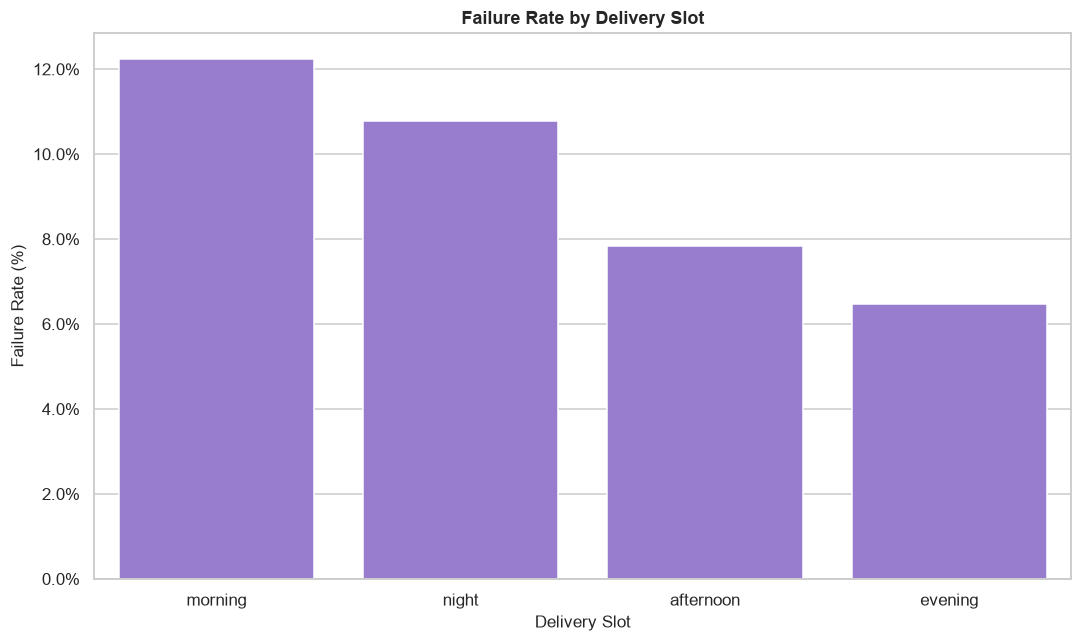

Figure saved to: ..\outputs\figures\expanded_failure_by_day.png


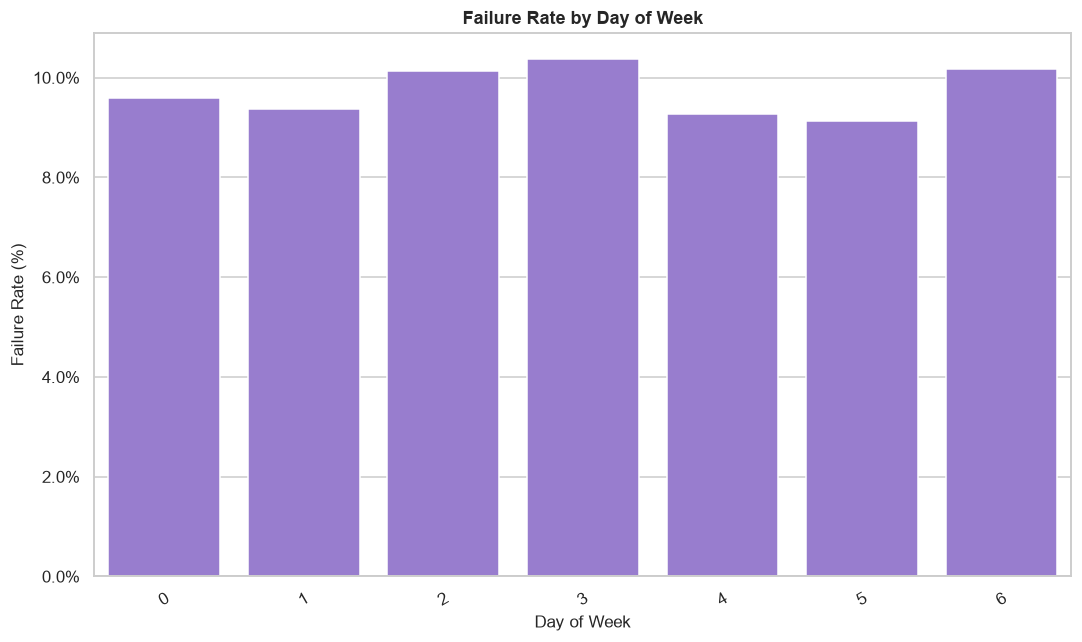

Figure saved to: ..\outputs\figures\expanded_failure_by_weekend.png


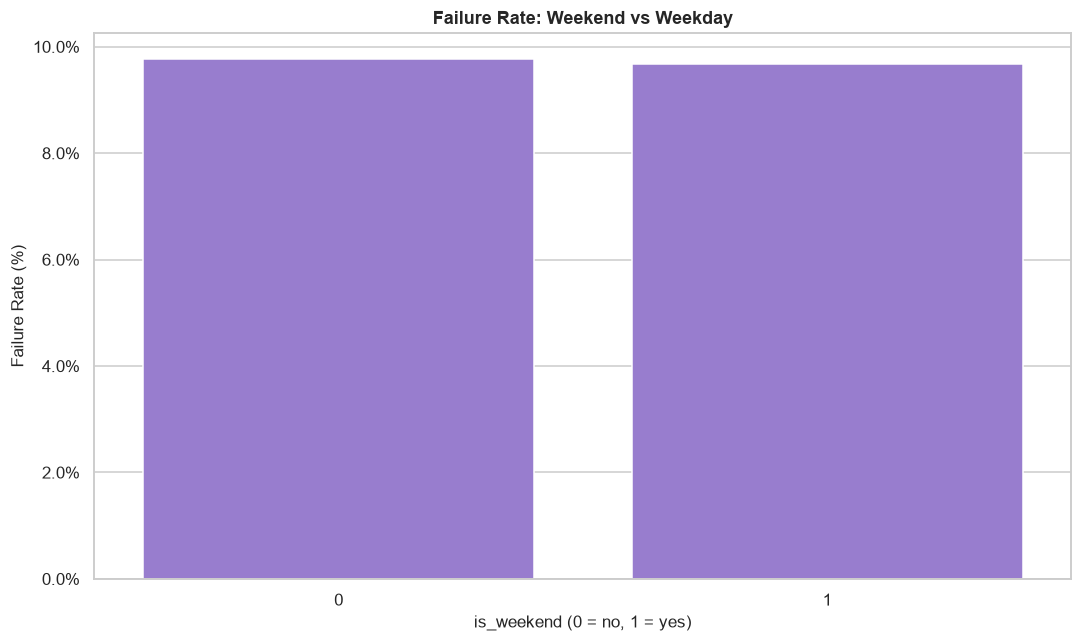

Figure saved to: ..\outputs\figures\expanded_failure_by_city.png


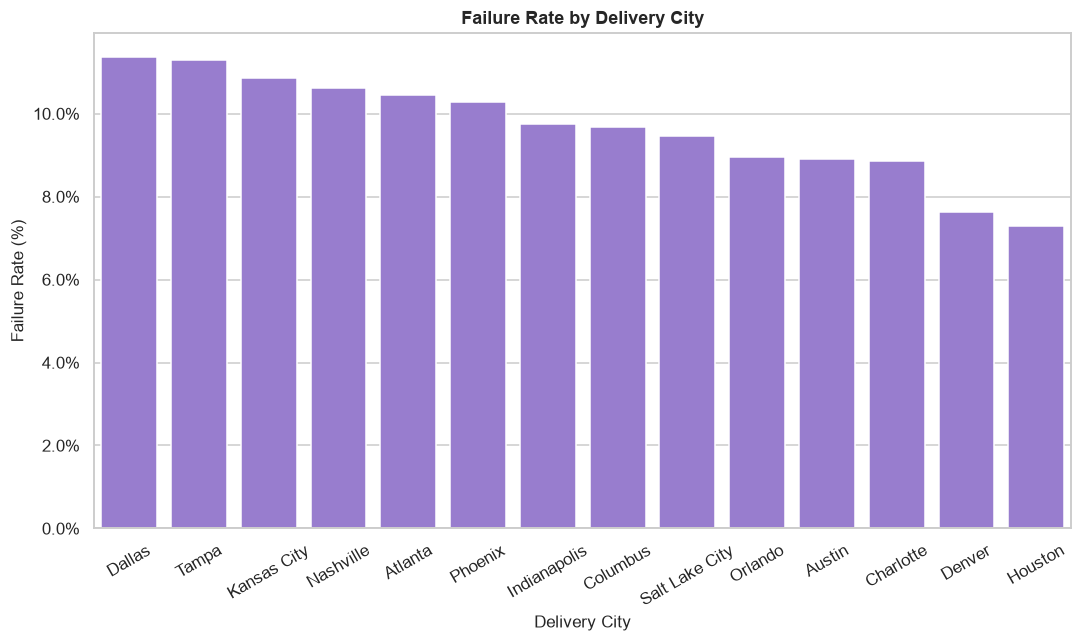

Figure saved to: ..\outputs\figures\expanded_failure_by_weather.png


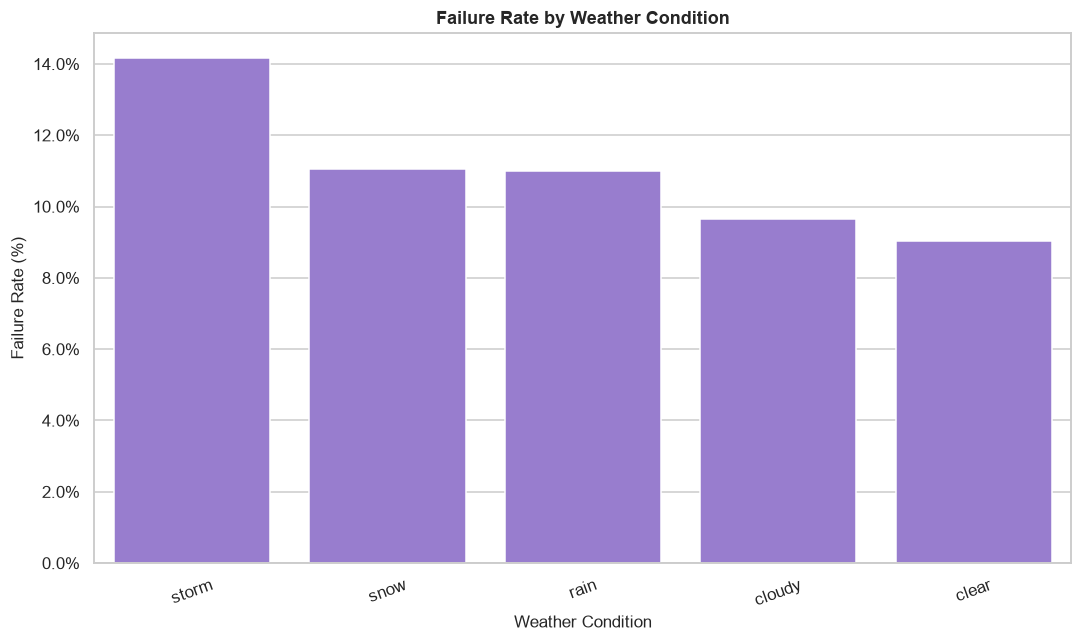

Figure saved to: ..\outputs\figures\expanded_failure_by_address_type.png


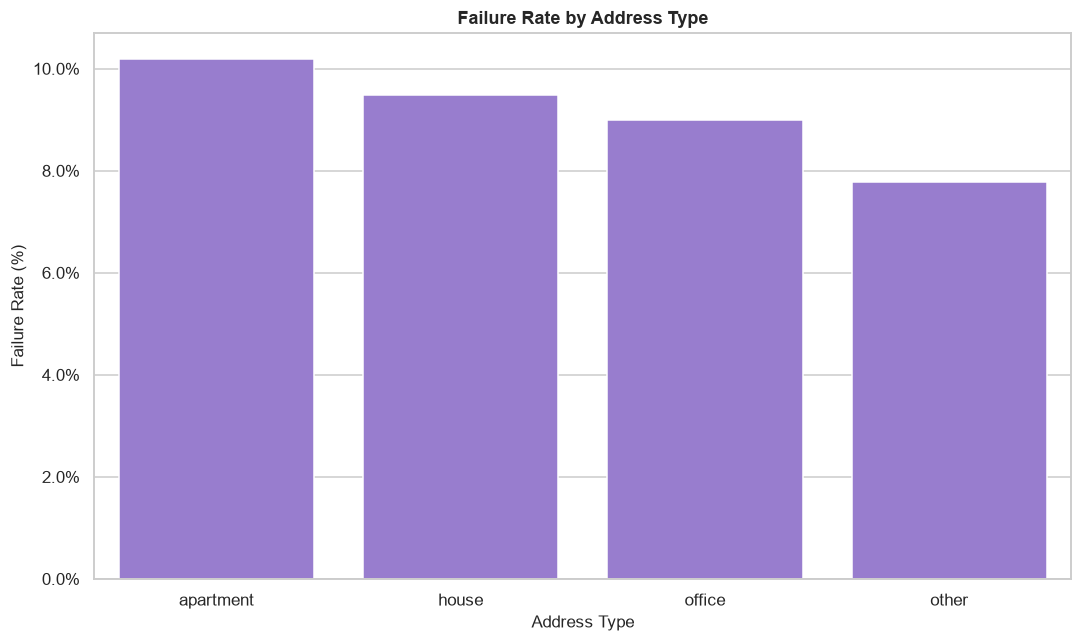

Figure saved to: ..\outputs\figures\expanded_failure_by_new_address.png


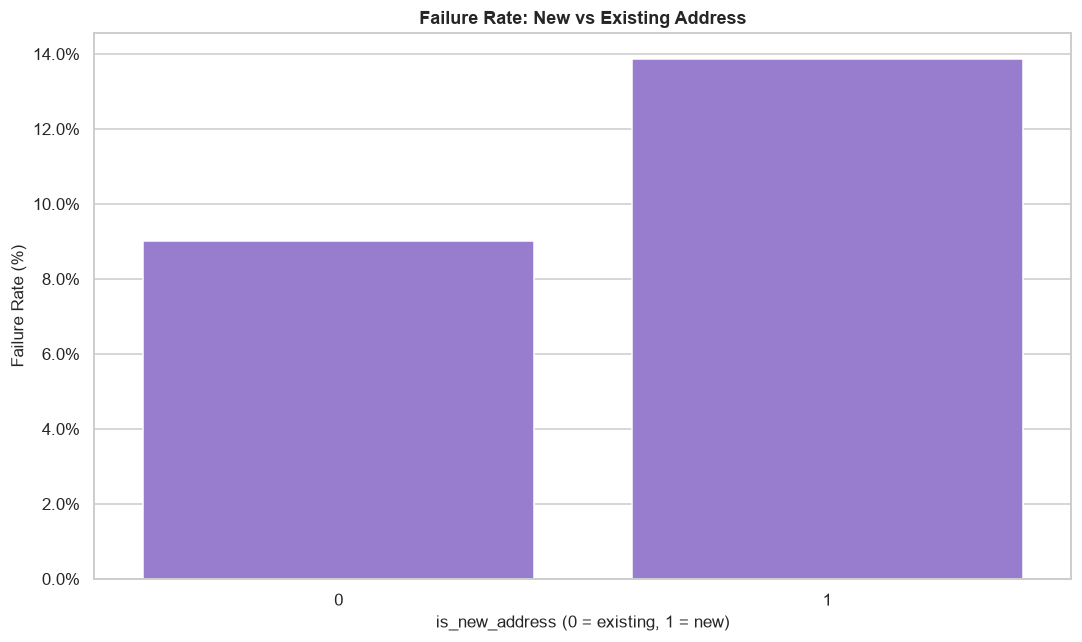

Figure saved to: ..\outputs\figures\expanded_failure_by_alcohol.png


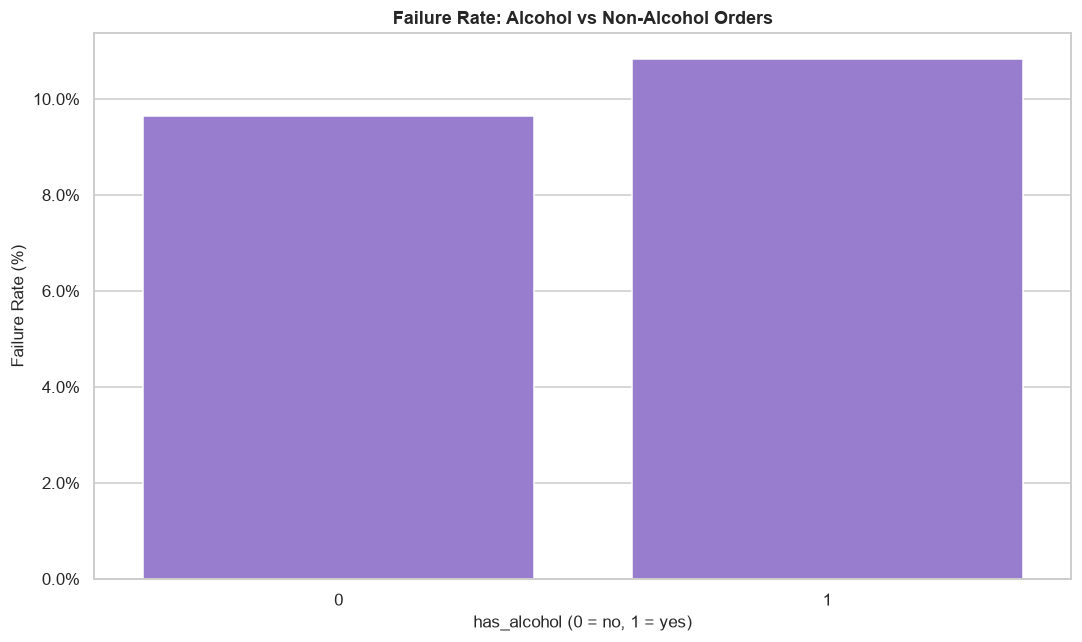

Figure saved to: ..\outputs\figures\expanded_failure_by_lead_time.png


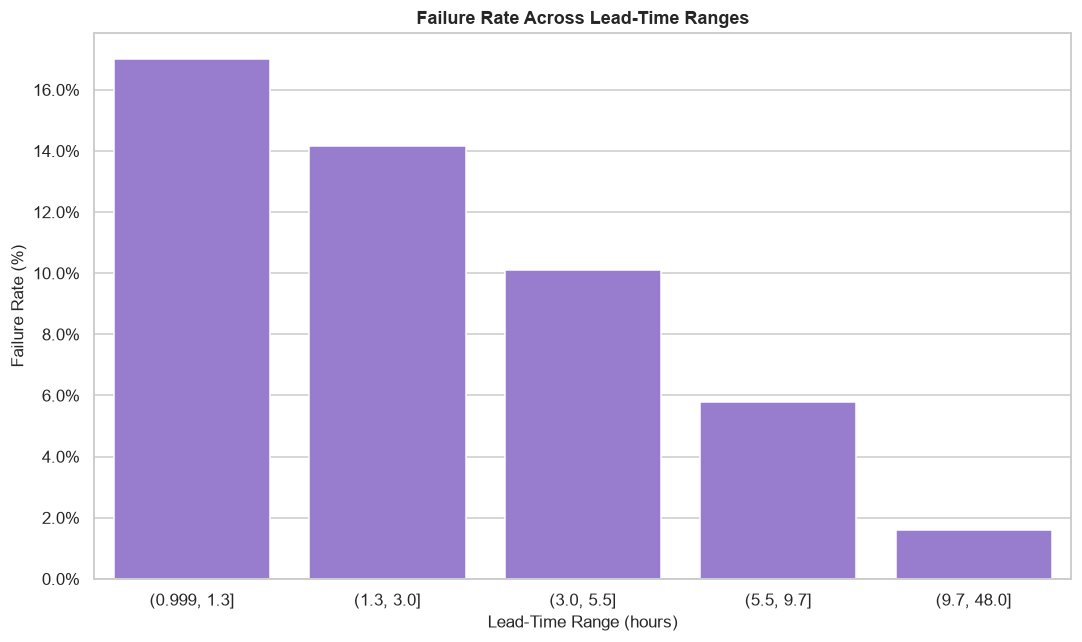

Figure saved to: ..\outputs\figures\expanded_failure_by_partner_load.png


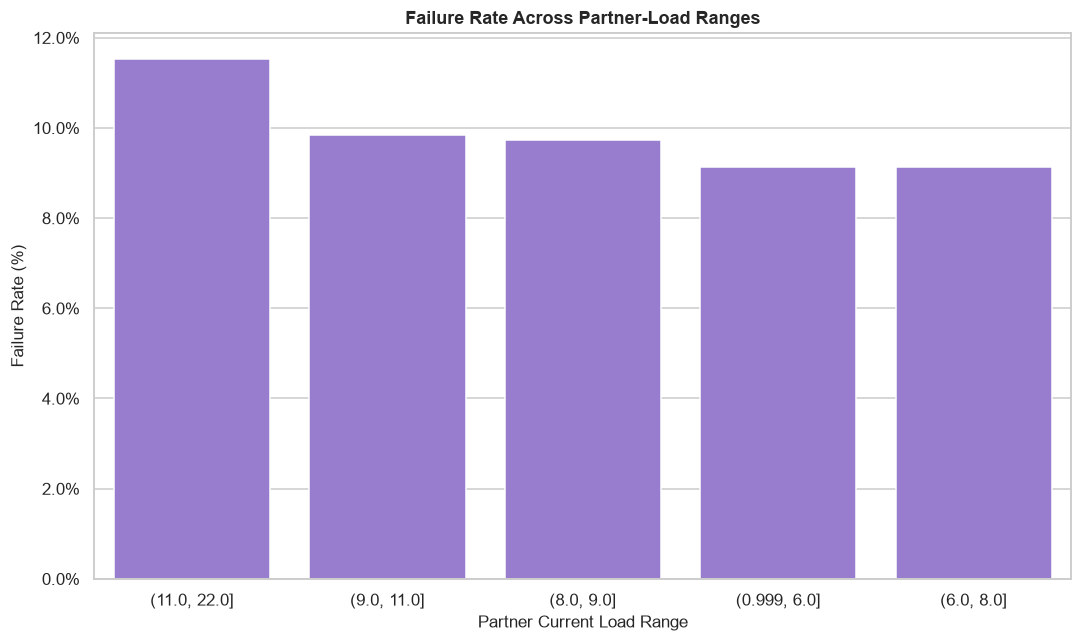

Figure saved to: ..\outputs\figures\expanded_failure_by_utilization.png


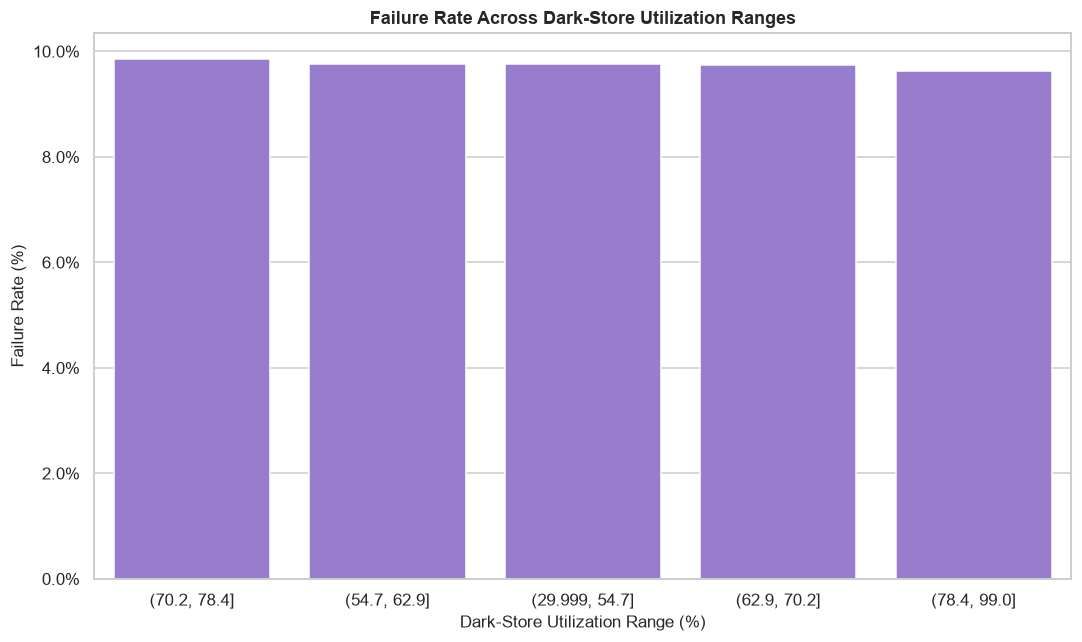

Figure saved to: ..\outputs\figures\expanded_failure_by_temperature.png


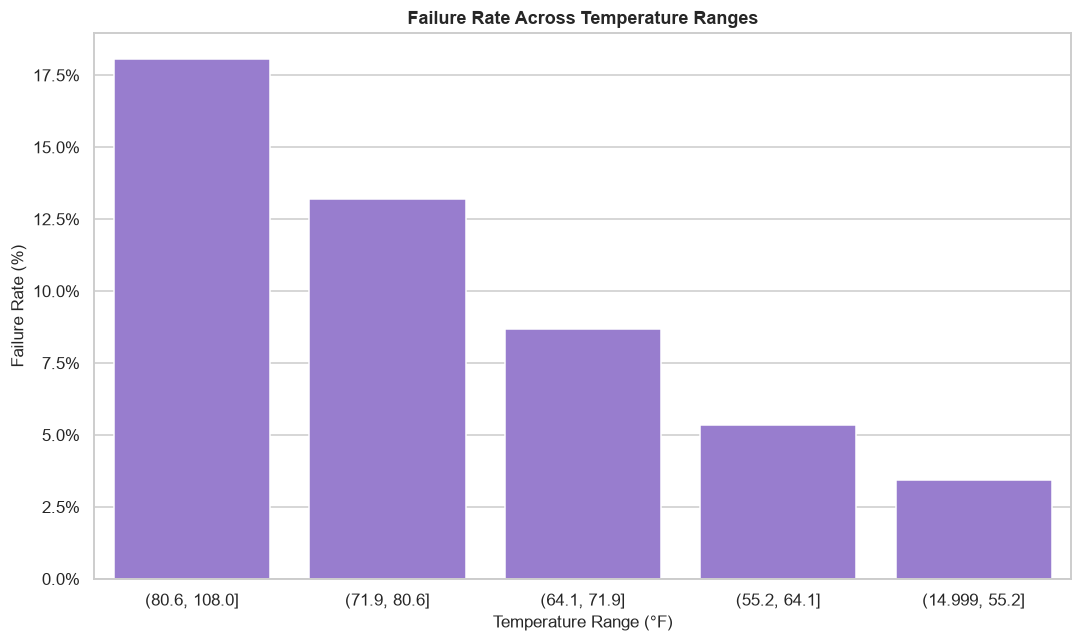

Figure saved to: ..\outputs\figures\expanded_failure_by_floor.png


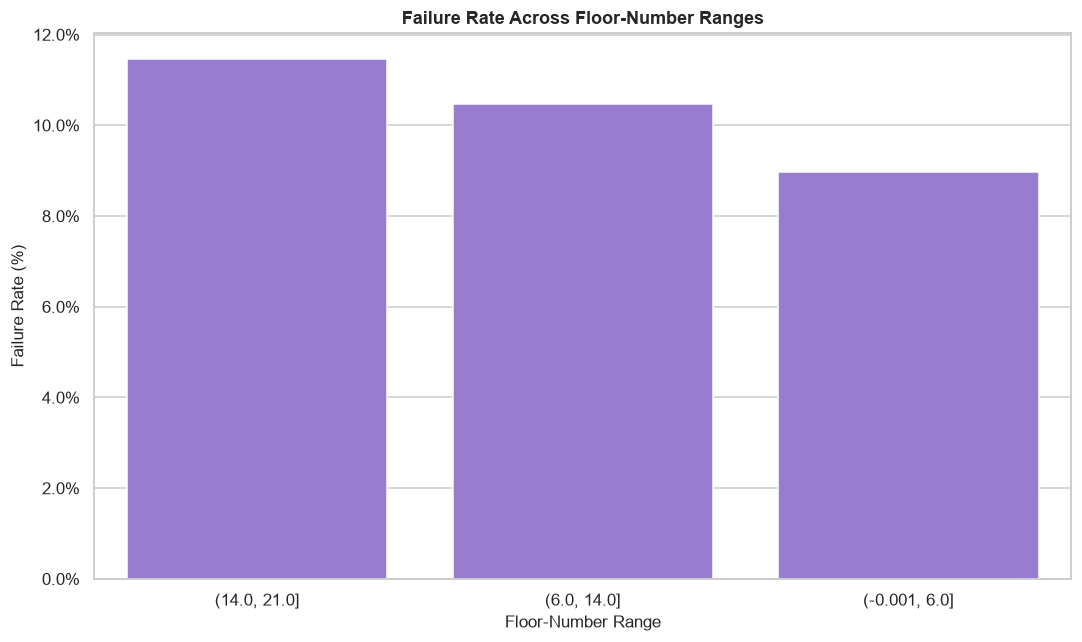

Figure saved to: ..\outputs\figures\expanded_failure_by_num_items.png


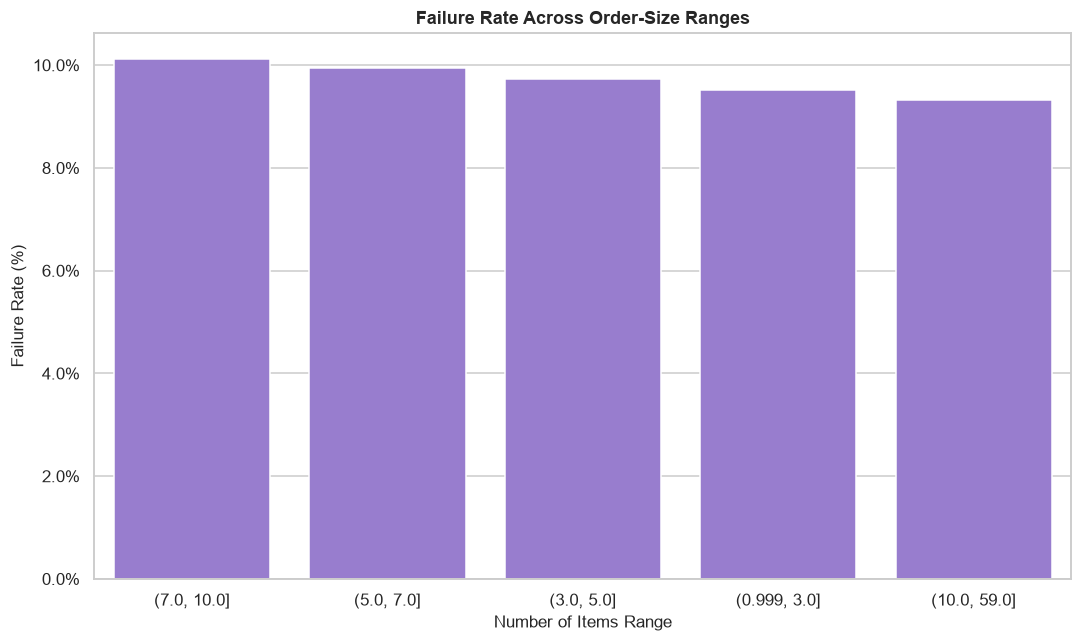

Figure saved to: ..\outputs\figures\expanded_failure_by_perishables.png


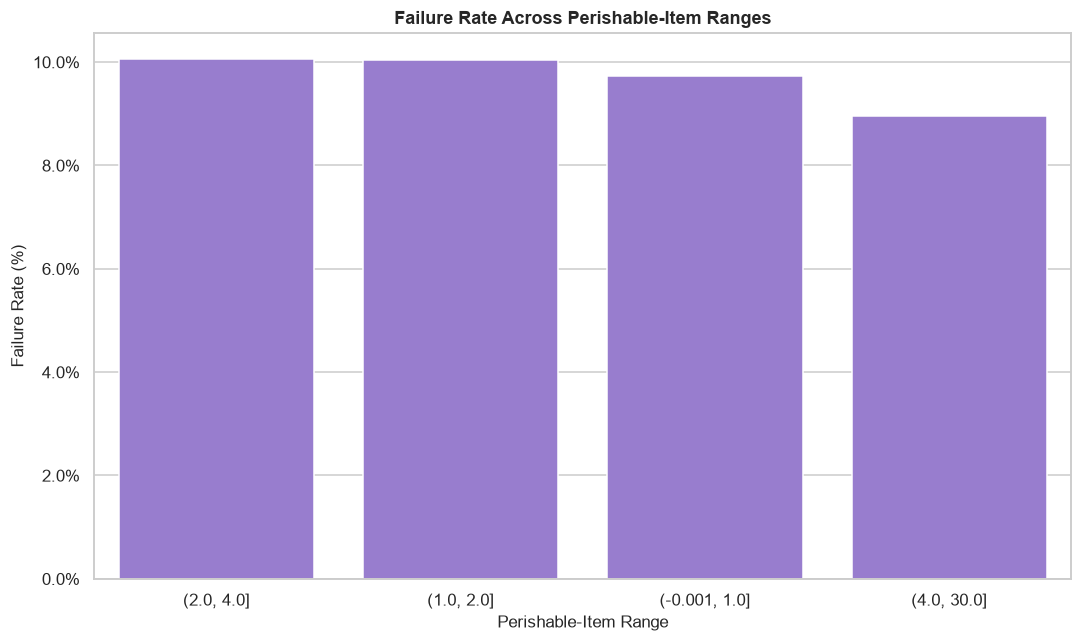

Figure saved to: ..\outputs\figures\expanded_failure_by_frozen_items.png


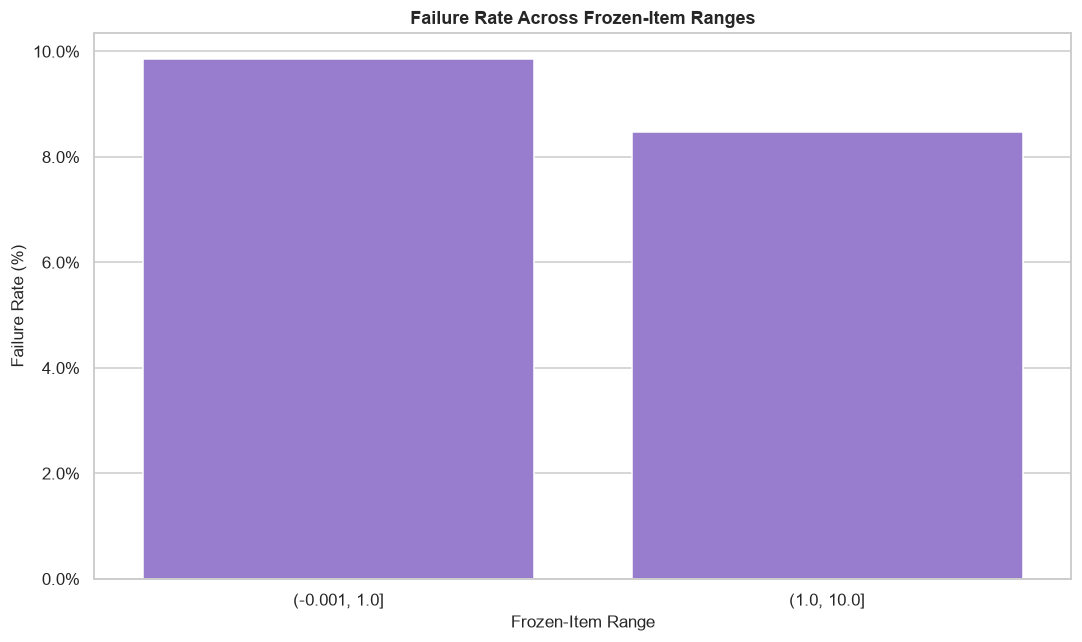

Figure saved to: ..\outputs\figures\expanded_failure_by_discount.png


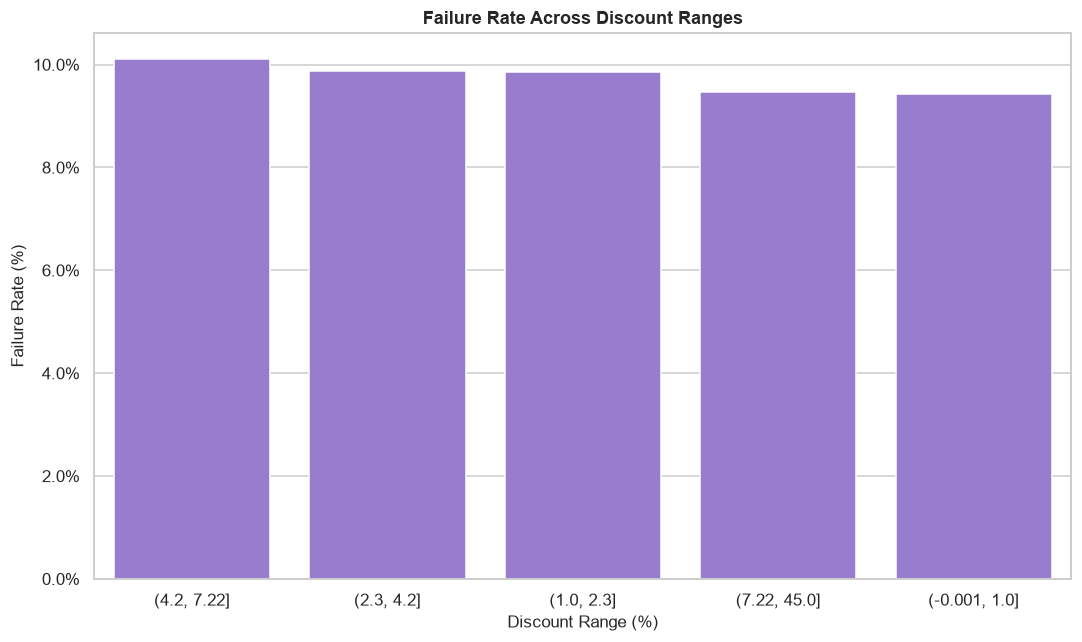

Figure saved to: ..\outputs\figures\expanded_failure_by_tenure.png


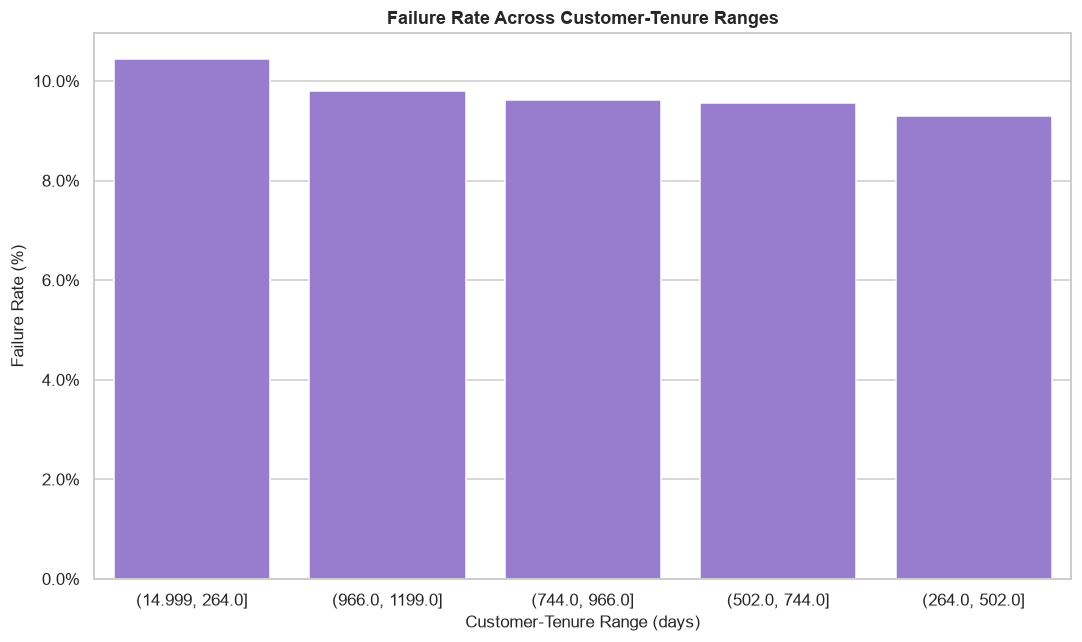

Figure saved to: ..\outputs\figures\expanded_failure_by_past_orders.png


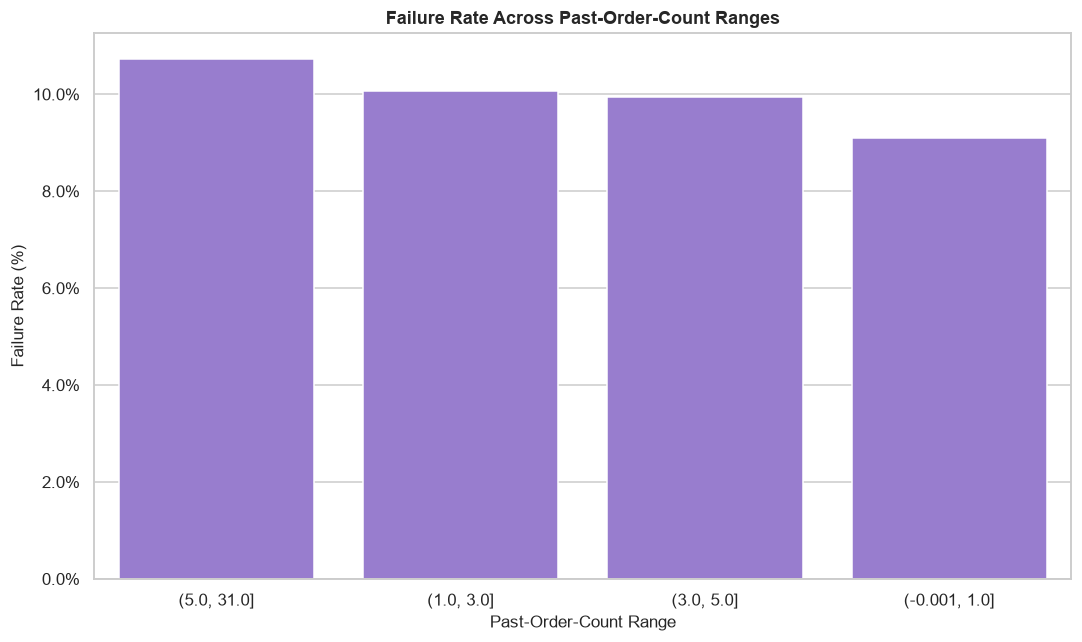

Figure saved to: ..\outputs\figures\expanded_failure_by_past_failures.png


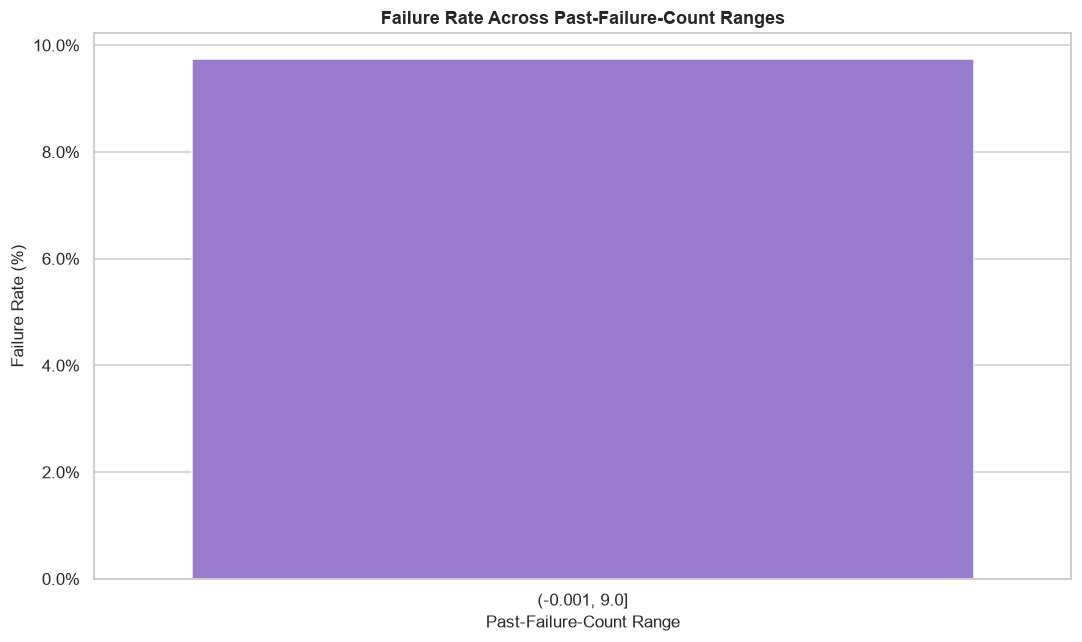

Figure saved to: ..\outputs\figures\expanded_failure_by_pin_code.png


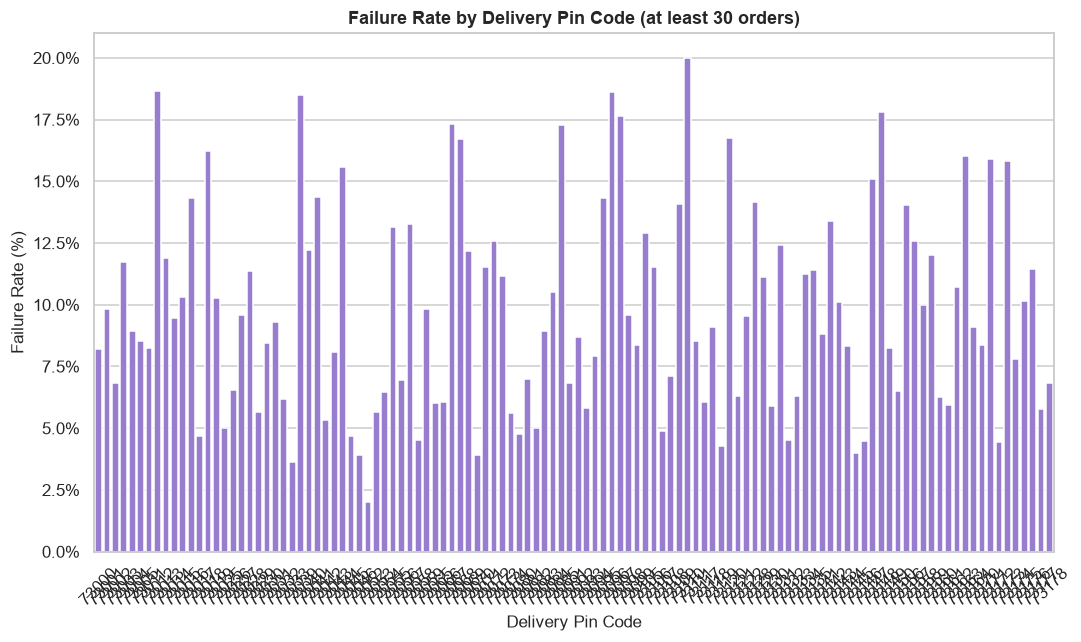

,feature,highest_failure_rate_pct,lowest_failure_rate_pct
0,delivery_slot,12.24,6.47
1,order_day_of_week,10.37,9.13
2,is_weekend,9.77,9.67
3,delivery_city,11.37,7.30
4,weather_condition,14.16,9.04
5,address_type,10.19,7.78
6,is_new_address,13.86,9.01
7,has_alcohol,10.83,9.64
8,lead_time_hours,17.00,1.59
9,partner_current_load,11.53,9.12


In [77]:
def plot_failure_rate(data, feature, title, xlabel, filename, bins=None, min_count=None, rotation=0):
    """Plot failure rate by category or equal-frequency numeric range."""
    analysis = data[[feature, 'delivery_failed']].dropna().copy()
    plot_feature = feature
    if bins:
        plot_feature = f'{feature}_range'
        analysis[plot_feature] = pd.qcut(analysis[feature], q=bins, duplicates='drop').astype(str)
    summary = (analysis.groupby(plot_feature)['delivery_failed']
               .agg(failure_rate='mean', orders='size').reset_index())
    if min_count:
        summary = summary[summary['orders'] >= min_count]
    summary['failure_rate_pct'] = summary['failure_rate'] * 100
    summary = summary.sort_values('failure_rate_pct', ascending=False)
    plot_grouped_bar_chart(summary, plot_feature, 'failure_rate_pct', title, xlabel,
                           'Failure Rate (%)', rotation, filename)
    return summary


def plot_failure_interaction(data, row_feature, column_feature, title, filename, row_label, column_label):
    """Plot a heatmap of delivery-failure rates across two features."""
    rates = data.pivot_table(index=row_feature, columns=column_feature,
                             values='delivery_failed', aggfunc='mean') * 100
    plt.figure(figsize=(10, 6))
    sns.heatmap(rates, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=.5,
                cbar_kws={'label': 'Failure Rate (%)'})
    plt.title(title)
    plt.xlabel(column_label)
    plt.ylabel(row_label)
    plt.tight_layout()
    save_figure(filename)
    plt.show()
    return rates

# Categorical comparisons: time, geography, weather, address, payment/order composition, and customer history.
categorical_analyses = [
    ('delivery_slot', 'Failure Rate by Delivery Slot', 'Delivery Slot', 'expanded_failure_by_delivery_slot.png', 0),
    ('order_day_of_week', 'Failure Rate by Day of Week', 'Day of Week', 'expanded_failure_by_day.png', 30),
    ('is_weekend', 'Failure Rate: Weekend vs Weekday', 'is_weekend (0 = no, 1 = yes)', 'expanded_failure_by_weekend.png', 0),
    ('delivery_city', 'Failure Rate by Delivery City', 'Delivery City', 'expanded_failure_by_city.png', 30),
    ('weather_condition', 'Failure Rate by Weather Condition', 'Weather Condition', 'expanded_failure_by_weather.png', 20),
    ('address_type', 'Failure Rate by Address Type', 'Address Type', 'expanded_failure_by_address_type.png', 0),
    ('is_new_address', 'Failure Rate: New vs Existing Address', 'is_new_address (0 = existing, 1 = new)', 'expanded_failure_by_new_address.png', 0),
    ('has_alcohol', 'Failure Rate: Alcohol vs Non-Alcohol Orders', 'has_alcohol (0 = no, 1 = yes)', 'expanded_failure_by_alcohol.png', 0),
]

expanded_summaries = {}
for feature, title, xlabel, filename, rotation in categorical_analyses:
    expanded_summaries[feature] = plot_failure_rate(df, feature, title, xlabel, filename, rotation=rotation)

# Numerical comparisons use quintiles to reveal nonlinear risk patterns.
numeric_analyses = [
    ('lead_time_hours', 'Failure Rate Across Lead-Time Ranges', 'Lead-Time Range (hours)', 'expanded_failure_by_lead_time.png'),
    ('partner_current_load', 'Failure Rate Across Partner-Load Ranges', 'Partner Current Load Range', 'expanded_failure_by_partner_load.png'),
    ('darkstore_utilization_pct', 'Failure Rate Across Dark-Store Utilization Ranges', 'Dark-Store Utilization Range (%)', 'expanded_failure_by_utilization.png'),
    ('temperature_f', 'Failure Rate Across Temperature Ranges', 'Temperature Range (°F)', 'expanded_failure_by_temperature.png'),
    ('floor_number', 'Failure Rate Across Floor-Number Ranges', 'Floor-Number Range', 'expanded_failure_by_floor.png'),
    ('num_items', 'Failure Rate Across Order-Size Ranges', 'Number of Items Range', 'expanded_failure_by_num_items.png'),
    ('num_perishable_items', 'Failure Rate Across Perishable-Item Ranges', 'Perishable-Item Range', 'expanded_failure_by_perishables.png'),
    ('num_frozen_items', 'Failure Rate Across Frozen-Item Ranges', 'Frozen-Item Range', 'expanded_failure_by_frozen_items.png'),
    ('discount_applied_pct', 'Failure Rate Across Discount Ranges', 'Discount Range (%)', 'expanded_failure_by_discount.png'),
    ('customer_tenure_days', 'Failure Rate Across Customer-Tenure Ranges', 'Customer-Tenure Range (days)', 'expanded_failure_by_tenure.png'),
    ('past_order_count', 'Failure Rate Across Past-Order-Count Ranges', 'Past-Order-Count Range', 'expanded_failure_by_past_orders.png'),
    ('past_failure_count', 'Failure Rate Across Past-Failure-Count Ranges', 'Past-Failure-Count Range', 'expanded_failure_by_past_failures.png'),
]
for feature, title, xlabel, filename in numeric_analyses:
    expanded_summaries[feature] = plot_failure_rate(df, feature, title, xlabel, filename, bins=5)

# Pin-code rates are filtered to adequately represented pin codes before ranking.
pin_code_summary = plot_failure_rate(
    df, 'delivery_pin_code', 'Failure Rate by Delivery Pin Code (at least 30 orders)',
    'Delivery Pin Code', 'expanded_failure_by_pin_code.png', min_count=30, rotation=45
)
expanded_summaries['delivery_pin_code'] = pin_code_summary
display(pd.DataFrame({
    'feature': list(expanded_summaries),
    'highest_failure_rate_pct': [summary['failure_rate_pct'].max() for summary in expanded_summaries.values()],
    'lowest_failure_rate_pct': [summary['failure_rate_pct'].min() for summary in expanded_summaries.values()],
}).round(2))

Figure saved to: ..\outputs\figures\interaction_distance_weather.png


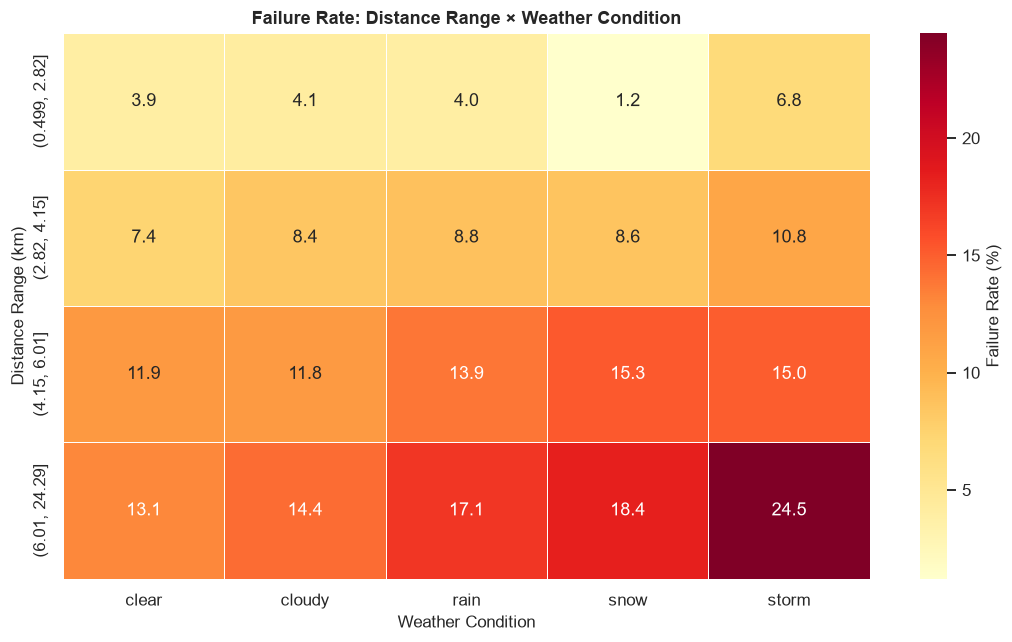

Figure saved to: ..\outputs\figures\interaction_partner_load_utilization.png


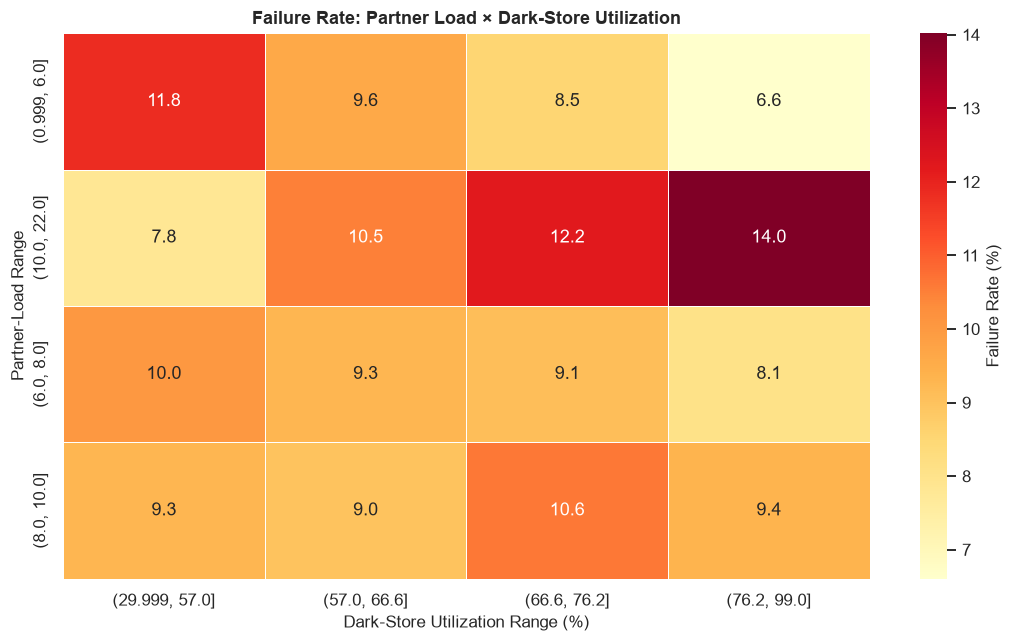

Figure saved to: ..\outputs\figures\interaction_lead_time_slot.png


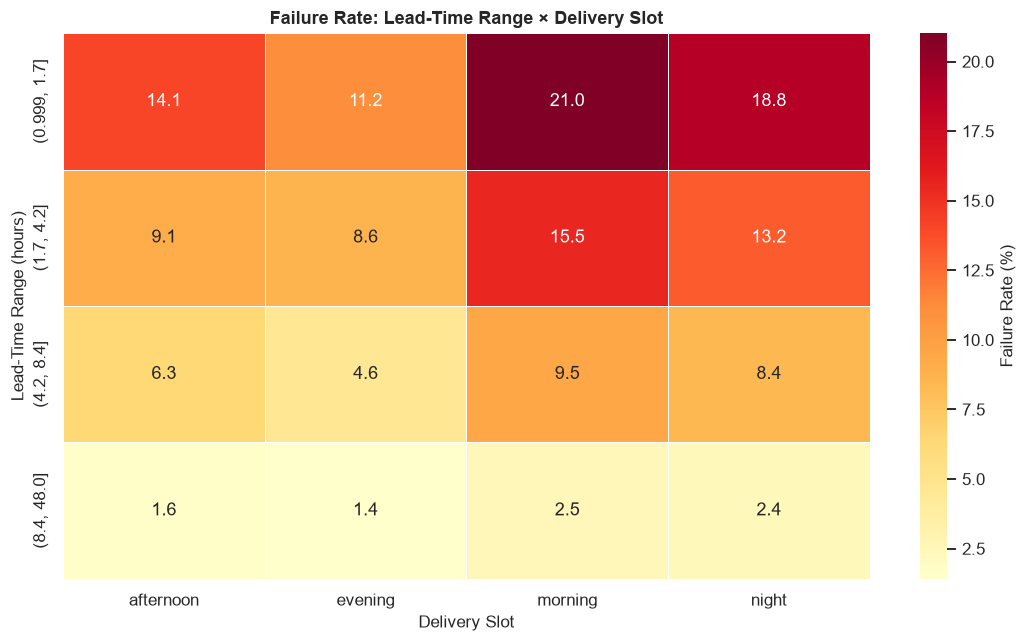

Figure saved to: ..\outputs\figures\interaction_history_risk.png


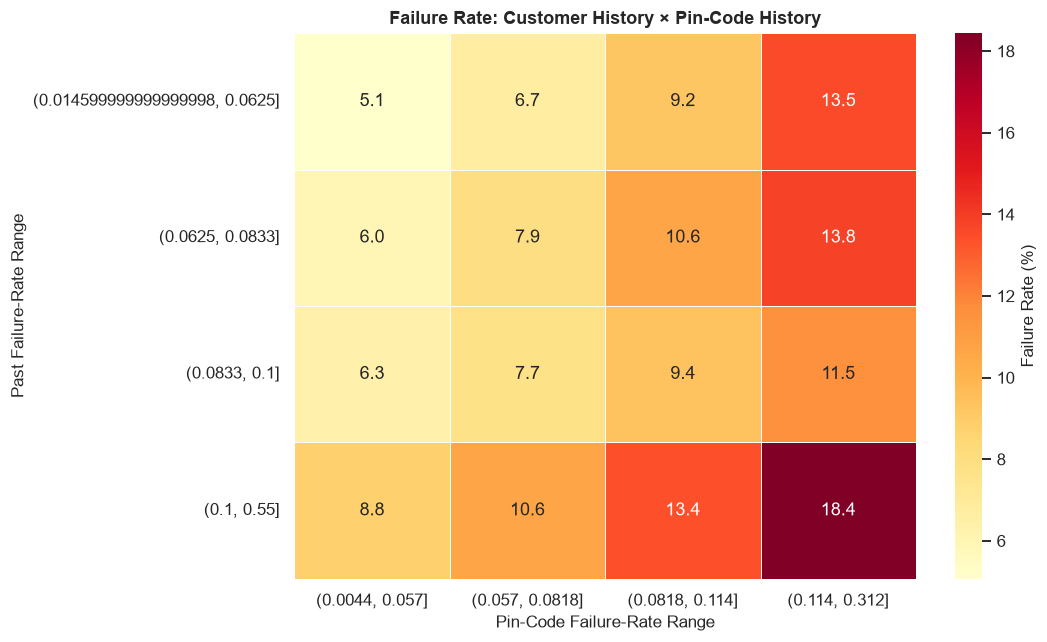

pin_code_failure_rate_band,"(0.0044, 0.057]","(0.057, 0.0818]","(0.0818, 0.114]","(0.114, 0.312]"
past_failure_rate_band,,,,
"(0.014599999999999998, 0.0625]",5.067786,6.721943,9.208500,13.543307
"(0.0625, 0.0833]",5.955268,7.949213,10.628466,13.803873
"(0.0833, 0.1]",6.331415,7.710747,9.354839,11.548861
"(0.1, 0.55]",8.761584,10.624635,13.386173,18.440934


In [78]:
# Interaction views reveal combinations of conditions that elevate failure risk.
interaction_data = df.copy()
for feature in ['distance_from_darkstore_km', 'partner_current_load', 'darkstore_utilization_pct',
                'lead_time_hours', 'past_failure_rate', 'pin_code_failure_rate']:
    interaction_data[f'{feature}_band'] = pd.qcut(
        interaction_data[feature], q=4, duplicates='drop'
    ).astype(str)

plot_failure_interaction(
    interaction_data, 'distance_from_darkstore_km_band', 'weather_condition',
    'Failure Rate: Distance Range × Weather Condition', 'interaction_distance_weather.png',
    'Distance Range (km)', 'Weather Condition'
)
plot_failure_interaction(
    interaction_data, 'partner_current_load_band', 'darkstore_utilization_pct_band',
    'Failure Rate: Partner Load × Dark-Store Utilization', 'interaction_partner_load_utilization.png',
    'Partner-Load Range', 'Dark-Store Utilization Range (%)'
)
plot_failure_interaction(
    interaction_data, 'lead_time_hours_band', 'delivery_slot',
    'Failure Rate: Lead-Time Range × Delivery Slot', 'interaction_lead_time_slot.png',
    'Lead-Time Range (hours)', 'Delivery Slot'
)
plot_failure_interaction(
    interaction_data, 'past_failure_rate_band', 'pin_code_failure_rate_band',
    'Failure Rate: Customer History × Pin-Code History', 'interaction_history_risk.png',
    'Past Failure-Rate Range', 'Pin-Code Failure-Rate Range'
)

### Multivariate Analysis

#### Correlation Analysis

Examine the linear relationships among the numerical delivery, customer, and operational features.

Columns included in the correlation analysis:
['customer_tenure_days', 'past_order_count', 'past_failure_count', 'past_failure_rate', 'avg_past_order_value_usd', 'days_since_last_order', 'is_new_address', 'floor_number', 'distance_from_darkstore_km', 'pin_code_failure_rate', 'order_value_usd', 'num_items', 'num_perishable_items', 'num_frozen_items', 'has_alcohol', 'discount_applied_pct', 'is_weekend', 'lead_time_hours', 'partner_current_load', 'darkstore_utilization_pct', 'temperature_f', 'order_hour', 'order_day_of_week', 'delivery_failed']
Columns included in the correlation analysis:
['customer_tenure_days', 'past_order_count', 'past_failure_count', 'past_failure_rate', 'avg_past_order_value_usd', 'days_since_last_order', 'is_new_address', 'floor_number', 'distance_from_darkstore_km', 'pin_code_failure_rate', 'order_value_usd', 'num_items', 'num_perishable_items', 'num_frozen_items', 'has_alcohol', 'discount_applied_pct', 'is_weekend', 'lead_time_hours', 'partner_current_load', 'dar

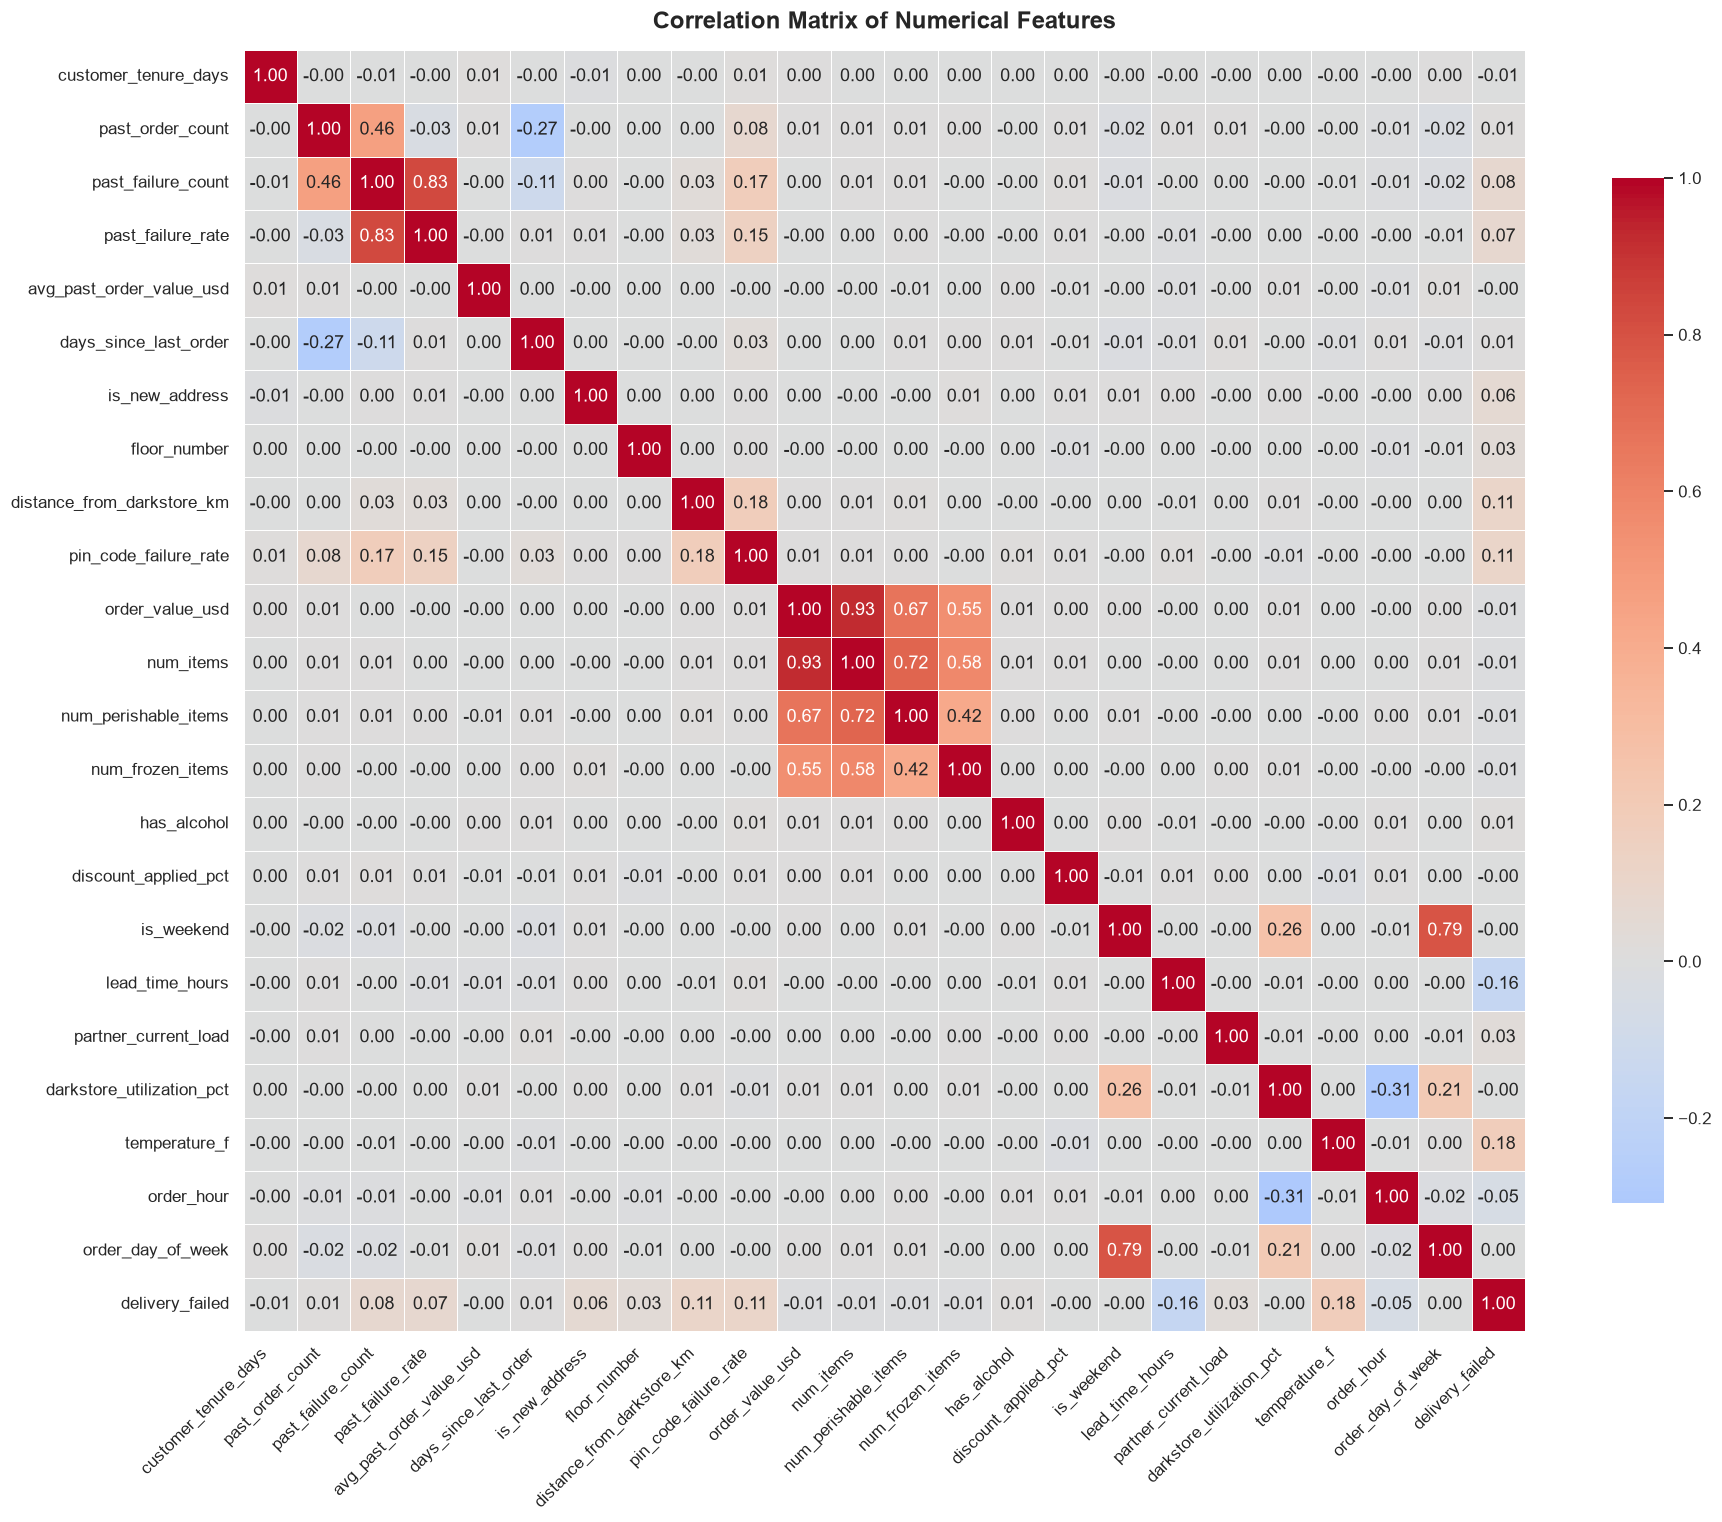

In [79]:
# Exclude identifier fields; retain numerical features relevant to delivery performance.
correlation_columns = [
    'customer_tenure_days', 'past_order_count', 'past_failure_count',
    'past_failure_rate', 'avg_past_order_value_usd', 'days_since_last_order',
    'is_new_address', 'floor_number', 'distance_from_darkstore_km',
    'pin_code_failure_rate', 'order_value_usd', 'num_items',
    'num_perishable_items', 'num_frozen_items', 'has_alcohol',
    'discount_applied_pct', 'is_weekend', 'lead_time_hours', 'partner_current_load',
    'darkstore_utilization_pct', 'temperature_f', 'order_hour', 'order_day_of_week',
    'delivery_failed'
]

print('Columns included in the correlation analysis:')
print(correlation_columns)

# Keep only numeric columns; day_of_week is categorical and is excluded.
numeric_correlation_columns = [
    column for column in correlation_columns
    if pd.api.types.is_numeric_dtype(df[column])
]

print('Columns included in the correlation analysis:')
print(numeric_correlation_columns)

correlation_matrix = df[numeric_correlation_columns].corr()

plt.figure(figsize=(18, 14))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, square=True, cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix of Numerical Features', fontsize=16, pad=14)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
save_figure('multivariate_correlation_matrix.png')
plt.show()

#### Modeling-Oriented EDA Results and Actionable Takeaways

**Univariate analysis**

- **Finding:** `past_failure_rate`, `distance_from_darkstore_km`, and `order_value_usd` are heavily right-skewed, with visible high-end outliers. **Action:** retain outliers unless they fail a business-validity check; use tree-based models or log/robust transformations for linear models.
- **Finding:** `delivery_failed` has a 9.7% positive class rate. **Action:** use stratified splits, class weights or resampling, and evaluate recall, PR-AUC, and cost-sensitive thresholds rather than accuracy alone.
- **Finding:** `avg_past_order_value_usd` and `days_since_last_order` are each missing for 23.3% of orders, whereas the operational fields are missing for only about 0.5%. **Action:** impute these fields and add explicit missing-indicator features; do not silently discard these rows.
- **Finding:** Cities and pin codes are high-cardinality location features. **Action:** group infrequent levels into `Other` and apply out-of-fold frequency or target encoding rather than unrestricted one-hot encoding.

**Bivariate analysis**

- **Finding:** Failure rates vary nonlinearly across lead-time ranges (about 1.6% to 17.0%) and across time, weather, distance, payment, and operational-load segments. **Action:** favor tree/boosted models or add binned and spline features rather than assuming linear effects.
- **Finding:** Failed orders average 5.57 km from the dark store versus 4.61 km for successful orders, and cash-on-delivery has a higher observed failure rate than prepaid modes. **Action:** include distance and payment mode, then test calibrated decision thresholds by operational segment.
- **Finding:** Missingness in average past value and recency differs by target outcome (20.5% among failed vs 23.7% among successful orders). **Action:** treat missingness as potentially informative and validate missing-indicator effects with cross-validation.
- **Finding:** `past_failure_count`/`past_failure_rate` and `order_value_usd`/`num_items` are strongly correlated (about 0.83 and 0.93 respectively). **Action:** for linear models drop one variable per redundant pair or use Ridge/Lasso; tree models can retain both but should be checked with permutation importance.
- **Finding:** Historical rate features can leak the outcome if calculated using data at or after the order being scored. **Action:** rebuild `past_failure_rate` and `pin_code_failure_rate` using only records earlier than each order timestamp, preferably inside each training fold.

**Multivariate analysis**

- **Finding:** Interaction heatmaps show that distance/weather, partner-load/utilization, lead-time/slot, and customer/pin-code history may jointly change failure risk. **Action:** engineer interaction features and compare boosted trees against an interpretable regularized baseline.
- **Finding:** A subgroup pattern may reverse after conditioning on city, delivery slot, or weather (Simpson's paradox). **Action:** validate every broad segment conclusion with stratified plots and time-based cross-validation before operationalizing it.
- **Finding:** The correlation matrix shows only weak-to-modest individual linear target associations. **Action:** use nonlinear models, inspect SHAP or partial-dependence plots, and cluster residual-risk segments rather than relying on correlation screening alone.

## Data Preprocessing Plan

This section records the preprocessing approach recommended from the EDA. 

### 1. Define the modeling dataset

- Use `delivery_failed` as the binary target.
- Retain the engineered `order_day_of_week` and `order_hour` features. Convert `order_day_of_week` to an ordered categorical feature or cyclic sine/cosine representation; encode `order_hour` cyclically if using a linear model.
- Exclude direct identifiers (`order_id` and `customer_id`) from the initial feature matrix. Retain `delivery_pin_code` only after frequency/target encoding because it is high-cardinality.
- Keep all source timestamps through the split and feature-engineering stages; drop `order_timestamp` from the final estimator input after temporal features and leakage-safe historical features have been created.

### 2. Missing-data strategy

- For `avg_past_order_value_usd` and `days_since_last_order`, create binary missing-indicator features before imputing because their 23.3% missingness is potentially informative. Impute their numeric values with the **training-set median**.
- Median-impute the low-missingness numerical fields: `partner_current_load`, `darkstore_utilization_pct`, and `temperature_f`. Add indicators for these fields only if validation demonstrates benefit.
- Impute categorical missing values with an explicit `Unknown` category, never with a future or global mode.

### 3. Feature transformation and encoding

- Preserve skewed variables for tree-based models. For regularized linear models, consider `log1p` transforms for positively skewed non-negative features such as `order_value_usd`, `distance_from_darkstore_km`, and count fields; fit any transformation choices using training data only.
- One-hot encode low-cardinality categorical fields such as payment mode, weather condition, address type, delivery slot, city, weekend/new-address/alcohol flags, and temporal categories.
- For high-cardinality `delivery_pin_code`, use frequency encoding or out-of-fold target encoding. Group rare levels into `Other` based on a training-only minimum-frequency rule.
- Address redundant feature groups identified in EDA: evaluate one representative or regularization for `order_value_usd` / `num_items` and `past_failure_count` / `past_failure_rate`. Tree models may retain both; validate with permutation importance.

### 4. Leakage controls

- Recompute `past_failure_count`, `past_failure_rate`, and `pin_code_failure_rate` using only records strictly earlier than each order's `order_timestamp`.
- If target encoding is used, calculate it out-of-fold for training rows and from training data only for validation/test rows. Never calculate any aggregate using the row being predicted or future rows.
- Fit imputers, scalers, rare-category groupers, encoders, and transformations only on the training partition; apply the fitted objects unchanged to validation and test partitions.

### 5. Recommended train / validation / test split

Use a **chronological 70% / 15% / 15% split**, not a random split:

1. Sort orders by `order_timestamp` ascending.
2. Assign the earliest 70% of observations to training.
3. Assign the next 15% to validation for feature, model, class-weight, and decision-threshold selection.
4. Hold out the most recent 15% as the final test set, untouched until model selection is complete.

A chronological split best represents the production task—predicting failures for future orders—and prevents future operational behavior, pin-code history, and customer outcomes from leaking backward. Use rolling/expanding time-series cross-validation within the training period for robust model tuning.

### 6. Modeling-readiness checks after preprocessing

- Confirm no row has information from after its order timestamp.
- Compare missingness, category distributions, and the target rate across train, validation, and test periods to identify temporal drift.
- Retain the class imbalance in all partitions; use stratification only within time-compatible folds where feasible.
- Evaluate with PR-AUC, recall, precision, F1, ROC-AUC, and a business-selected decision threshold, rather than accuracy alone.

## Data Preprocessing Implementation

Apply the approved cleanup and leakage-safe preprocessing plan. This section produces model-ready train, validation, and test matrices but does **not** train a predictive model.

In [80]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Work from a chronologically ordered copy of the data used in EDA.
model_data = df.sort_values('order_timestamp').reset_index(drop=True).copy()

def add_prior_history_features(data, group_column, count_column, rate_column=None):
    """Create strictly-prior failure history from records earlier than each timestamp."""
    event_history = (
        data.groupby([group_column, 'order_timestamp'], as_index=False)['delivery_failed']
        .agg(orders='size', failures='sum')
        .sort_values([group_column, 'order_timestamp'])
    )
    event_history['prior_orders'] = (
        event_history.groupby(group_column)['orders'].cumsum() - event_history['orders']
    )
    event_history['prior_failures'] = (
        event_history.groupby(group_column)['failures'].cumsum() - event_history['failures']
    )
    data = data.merge(
        event_history[[group_column, 'order_timestamp', 'prior_orders', 'prior_failures']],
        on=[group_column, 'order_timestamp'], how='left'
    )
    data[count_column] = data['prior_failures'].fillna(0).astype(int)
    if rate_column:
        data[rate_column] = np.divide(
            data['prior_failures'], data['prior_orders'],
            out=np.zeros(len(data), dtype=float), where=data['prior_orders'].to_numpy() > 0
        )
    return data.drop(columns=['prior_orders', 'prior_failures'])

# Rebuild history features using only earlier records, preventing future-outcome leakage.
model_data = add_prior_history_features(
    model_data, 'customer_id', 'past_failure_count', 'past_failure_rate'
)
customer_prior_orders = (
    model_data.groupby(['customer_id', 'order_timestamp']).cumcount()
)
# Use strictly prior customer order counts from the timestamp-level history table.
customer_event_counts = (
    model_data.groupby(['customer_id', 'order_timestamp'], as_index=False).size()
    .rename(columns={'size': 'orders_at_timestamp'})
    .sort_values(['customer_id', 'order_timestamp'])
)
customer_event_counts['past_order_count_safe'] = (
    customer_event_counts.groupby('customer_id')['orders_at_timestamp'].cumsum()
    - customer_event_counts['orders_at_timestamp']
)
model_data = model_data.merge(
    customer_event_counts[['customer_id', 'order_timestamp', 'past_order_count_safe']],
    on=['customer_id', 'order_timestamp'], how='left'
)
model_data['past_order_count'] = model_data.pop('past_order_count_safe').fillna(0).astype(int)
model_data = add_prior_history_features(
    model_data, 'delivery_pin_code', 'pin_code_failure_count_safe', 'pin_code_failure_rate'
)
model_data = model_data.drop(columns=['pin_code_failure_count_safe'])

# Derive cyclic temporal features, then remove identifiers, raw timestamp, and duplicate day-of-week field.
model_data['order_hour_sin'] = np.sin(2 * np.pi * model_data['order_hour'] / 24)
model_data['order_hour_cos'] = np.cos(2 * np.pi * model_data['order_hour'] / 24)
model_data['order_day_sin'] = np.sin(2 * np.pi * model_data['order_day_of_week'] / 7)
model_data['order_day_cos'] = np.cos(2 * np.pi * model_data['order_day_of_week'] / 7)

drop_columns = ['order_id', 'customer_id', 'order_timestamp', 'day_of_week',
                'order_hour', 'order_day_of_week']
model_data = model_data.drop(columns=drop_columns)

# Chronological 70/15/15 split; all learned preprocessing statistics come from training rows only.
n_rows = len(model_data)
train_end, validation_end = round(n_rows * 0.70), round(n_rows * 0.85)
train_data = model_data.iloc[:train_end].copy()
validation_data = model_data.iloc[train_end:validation_end].copy()
test_data = model_data.iloc[validation_end:].copy()

target_column = 'delivery_failed'
categorical_features = ['delivery_city', 'delivery_pin_code', 'address_type', 'payment_mode',
                        'delivery_slot', 'weather_condition']
binary_features = ['is_new_address', 'has_alcohol', 'is_weekend']
missing_indicator_features = [
    'avg_past_order_value_usd', 'days_since_last_order', 'partner_current_load',
    'darkstore_utilization_pct', 'temperature_f'
]

# Create training-median imputations and indicators before filling all partitions.
numeric_candidates = [
    column for column in model_data.select_dtypes(include=np.number).columns
    if column not in [target_column, *binary_features]
]
train_medians = train_data[numeric_candidates].median()
for partition in [train_data, validation_data, test_data]:
    for column in missing_indicator_features:
        partition[f'{column}_missing'] = partition[column].isna().astype(int)
    partition[numeric_candidates] = partition[numeric_candidates].fillna(train_medians)
    partition[categorical_features] = partition[categorical_features].fillna('Unknown')

# Group rare pin codes from training data only, then frequency encode them to avoid high-cardinality one-hot features.
pin_code_counts = train_data['delivery_pin_code'].value_counts()
frequent_pin_codes = pin_code_counts[pin_code_counts >= 30].index
for partition in [train_data, validation_data, test_data]:
    partition['delivery_pin_code'] = partition['delivery_pin_code'].where(
        partition['delivery_pin_code'].isin(frequent_pin_codes), 'Other'
    )
pin_code_frequency = train_data['delivery_pin_code'].value_counts(normalize=True)
for partition in [train_data, validation_data, test_data]:
    partition['delivery_pin_code_frequency'] = partition['delivery_pin_code'].map(pin_code_frequency).fillna(0)

# Save a complete, imputed interim dataset with no missing values.
cleaned_data = pd.concat([train_data, validation_data, test_data], ignore_index=True)
interim_dir = data_path.parents[2] / 'data' / 'interim'
interim_dir.mkdir(parents=True, exist_ok=True)
cleaned_path = interim_dir / 'cleaned.csv'
cleaned_data.to_csv(cleaned_path, index=False)

print(f'Cleaned data saved to: {cleaned_path}')
print(f'Final cleaned shape: {cleaned_data.shape}')
print(f'Total missing values: {cleaned_data.isna().sum().sum()}')
print(f'Dropped columns: {drop_columns}')
print('Related engineered features:')
print(['past_order_count', 'past_failure_count', 'past_failure_rate',
       'pin_code_failure_rate', 'delivery_pin_code_frequency',
       'order_hour_sin', 'order_hour_cos', 'order_day_sin', 'order_day_cos',
       *[f'{column}_missing' for column in missing_indicator_features]])

Cleaned data saved to: ..\data\interim\cleaned.csv
Final cleaned shape: (45000, 38)
Total missing values: 0
Dropped columns: ['order_id', 'customer_id', 'order_timestamp', 'day_of_week', 'order_hour', 'order_day_of_week']
Related engineered features:
['past_order_count', 'past_failure_count', 'past_failure_rate', 'pin_code_failure_rate', 'delivery_pin_code_frequency', 'order_hour_sin', 'order_hour_cos', 'order_day_sin', 'order_day_cos', 'avg_past_order_value_usd_missing', 'days_since_last_order_missing', 'partner_current_load_missing', 'darkstore_utilization_pct_missing', 'temperature_f_missing']


In [81]:
# Build model-ready matrices. No model is trained in this cell.
encoded_categorical_features = [
    'delivery_city', 'address_type', 'payment_mode', 'delivery_slot', 'weather_condition'
]
continuous_features = [
    column for column in train_data.columns
    if column not in [target_column, *encoded_categorical_features, *binary_features, 'delivery_pin_code']
]

preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', StandardScaler(), continuous_features),
        ('binary', 'passthrough', binary_features),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), encoded_categorical_features),
    ],
    remainder='drop',
    verbose_feature_names_out=False,
).set_output(transform='pandas')

X_train = train_data.drop(columns=[target_column, 'delivery_pin_code'])
X_validation = validation_data.drop(columns=[target_column, 'delivery_pin_code'])
X_test = test_data.drop(columns=[target_column, 'delivery_pin_code'])
y_train = train_data[target_column]
y_validation = validation_data[target_column]
y_test = test_data[target_column]

X_train_processed = preprocessor.fit_transform(X_train)
X_validation_processed = preprocessor.transform(X_validation)
X_test_processed = preprocessor.transform(X_test)

print('Chronological split shapes (features):')
print(f'  Train:      {X_train_processed.shape}')
print(f'  Validation: {X_validation_processed.shape}')
print(f'  Test:       {X_test_processed.shape}')
print(f'Processed missing values — train: {X_train_processed.isna().sum().sum()}, '
      f'validation: {X_validation_processed.isna().sum().sum()}, test: {X_test_processed.isna().sum().sum()}')

Chronological split shapes (features):
  Train:      (31500, 61)
  Validation: (6750, 61)
  Test:       (6750, 61)
Processed missing values — train: 0, validation: 0, test: 0


In [82]:
# Persist chronological cleaned splits and model-ready matrices. No model is trained here.
processed_dir = data_path.parents[2] / 'data' / 'processed'
processed_dir.mkdir(parents=True, exist_ok=True)

# Cleaned, interpretable split datasets retain the target for model development.
train_data.to_csv(processed_dir / 'train_cleaned.csv', index=False)
validation_data.to_csv(processed_dir / 'validation_cleaned.csv', index=False)
test_data.to_csv(processed_dir / 'test_cleaned.csv', index=False)

# Model-ready matrices capture the fitted training-only preprocessing.
X_train_processed.to_csv(processed_dir / 'X_train_preprocessed.csv', index=False)
X_validation_processed.to_csv(processed_dir / 'X_validation_preprocessed.csv', index=False)
X_test_processed.to_csv(processed_dir / 'X_test_preprocessed.csv', index=False)
y_train.to_frame(name=target_column).to_csv(processed_dir / 'y_train.csv', index=False)
y_validation.to_frame(name=target_column).to_csv(processed_dir / 'y_validation.csv', index=False)
y_test.to_frame(name=target_column).to_csv(processed_dir / 'y_test.csv', index=False)

print(f'Processed data saved to: {processed_dir}')
print(f'Cleaned splits — train: {train_data.shape}, validation: {validation_data.shape}, test: {test_data.shape}')
print(f'Model-ready feature matrices — train: {X_train_processed.shape}, '
      f'validation: {X_validation_processed.shape}, test: {X_test_processed.shape}')

Processed data saved to: ..\data\processed
Cleaned splits — train: (31500, 38), validation: (6750, 38), test: (6750, 38)
Model-ready feature matrices — train: (31500, 61), validation: (6750, 61), test: (6750, 61)


## Model Building Plan

This is a planning section only. The next phase will train models using the saved chronological partitions; no model is fitted in this notebook section yet.

### Evaluation strategy

- **Primary selection metric: F1 score.** The failure class represents only 9.7% of orders, so accuracy can look high while failing to identify most delivery failures. F1 balances precision (avoiding unnecessary interventions) and recall (catching failures), making it the best default criterion among accuracy, precision, recall, and F1.
- **Operational guardrail: recall.** Missing a likely failed delivery can damage customer experience and waste recovery opportunities. Select the decision threshold on validation data to meet the required minimum recall, then choose the highest-precision option meeting that constraint.
- **Supporting metrics:** report precision, recall, F1, PR-AUC, ROC-AUC, confusion matrix, and calibration. Accuracy will be reported only as a contextual metric. For the ANN, monitor validation PR-AUC and validation loss for early stopping in addition to validation F1.
- Tune all hyperparameters and thresholds on the validation set (or expanding time-series folds within training); evaluate the test set once after final model selection.
- Create shared `evaluate_classifier`, `plot_confusion_matrix`, and ROC/PR-curve utilities before model training so every candidate uses the same metrics, labels, and decision-threshold logic.
- Use `RANDOM_STATE = 53` for the primary reproducible comparison. After selecting finalists, assess stochastic-model robustness across seeds 42, 53, 101, 202, and 777; report mean and standard deviation of validation F1, recall, and PR-AUC. Keep the chronological split boundaries fixed for every seed.

### Candidate models

1. **Dummy baseline:** establishes the no-skill performance and confirms the benefit of every trained model.
2. **Regularized Logistic Regression:** transparent baseline; works with the scaled numeric and one-hot encoded matrix and reveals directional feature effects. Use `class_weight='balanced'` as a starting point.
3. **Decision Tree:** interpretable nonlinear baseline; control depth and minimum leaf size to avoid overfitting.
4. **Random Forest:** robust nonlinear ensemble and useful feature-importance benchmark; use class weighting and tune tree count, depth, and leaf size.
5. **Gradient Boosting / HistGradientBoosting:** captures nonlinear effects and interactions identified in EDA, especially lead-time, weather, distance, and operational-load combinations.
6. **XGBoost:** likely strongest tabular-data candidate; tune depth, learning rate, subsampling, regularization, and `scale_pos_weight` using the training/validation chronology.
7. **Artificial Neural Network (ANN):** use the standardized numerical and one-hot encoded feature matrix. Start with a deliberately capable dense architecture of **256 → 128 → 64** neurons (optionally add a 32-neuron layer only if validation improves). Use **ReLU for every hidden layer**; do not mix tanh or sigmoid hidden activations initially because ReLU trains efficiently in deeper tabular networks. Use a single-unit **sigmoid output** for binary failure probability.
   - **Optimizer:** Adam with an initial learning rate of `1e-3`, plus `ReduceLROnPlateau` when validation PR-AUC/loss plateaus. Tune learning rate over `3e-4`, `1e-3`, and `3e-3`.
   - **Regularization:** batch normalization after dense layers, dropout around 0.30 / 0.25 / 0.20, and optional L2 regularization around `1e-4`.
   - **Training controls:** use class weights, early stopping with `restore_best_weights=True`, a maximum of 100 epochs, and batch sizes of 128 or 256. Tune layer width, dropout, learning rate, and L2 strength on the validation period.
   - **SGD follow-up:** after the Adam baseline, evaluate SGD with momentum (`learning_rate=0.01`, `momentum=0.9`, `nesterov=True`) plus learning-rate reduction and early stopping. Retain SGD only if validation F1/PR-AUC or probability calibration improves.

### Model-development sequence

1. Load `X_train_preprocessed.csv`, `X_validation_preprocessed.csv`, and their target files; implement the shared performance, confusion-matrix, ROC, and PR utilities.
2. Establish dummy and logistic-regression baselines.
3. Tune tree-based candidates on training data with validation F1 and recall constraints.
4. Train and tune the ANN on the same chronological training/validation split, using the 256 → 128 → 64 ReLU architecture, Adam optimizer, class weights, and early stopping; compare it fairly with the tabular baselines.
5. Compare validation F1, recall, precision, PR-AUC, calibration, confusion matrices, training time, and operational threshold trade-offs.
6. Repeat finalists across the selected random seeds while keeping the chronological partitions fixed.
7. Explain the selected model with permutation importance and SHAP/partial-dependence diagnostics; for an ANN, use permutation importance or SHAP with a representative validation sample.
8. Retrain the chosen specification on train + validation only if approved, then perform one final locked evaluation on the untouched test set.

## Model Building Implementation

Train candidate models on the chronological training partition and compare them only on the validation partition. The test partition remains locked and is not used in this section.

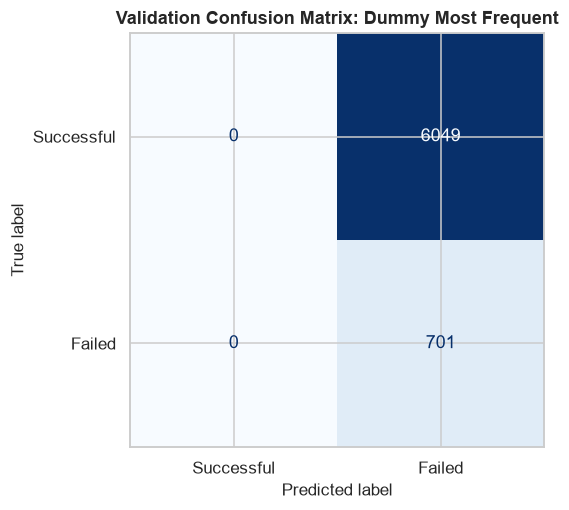

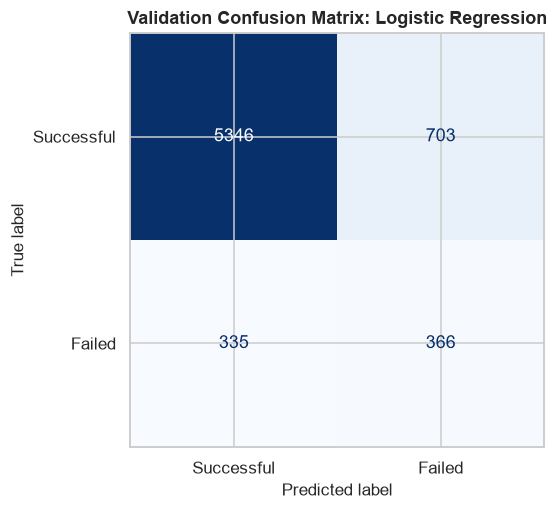

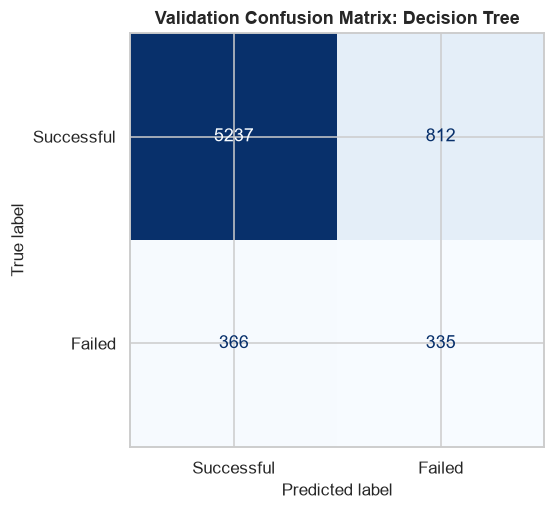

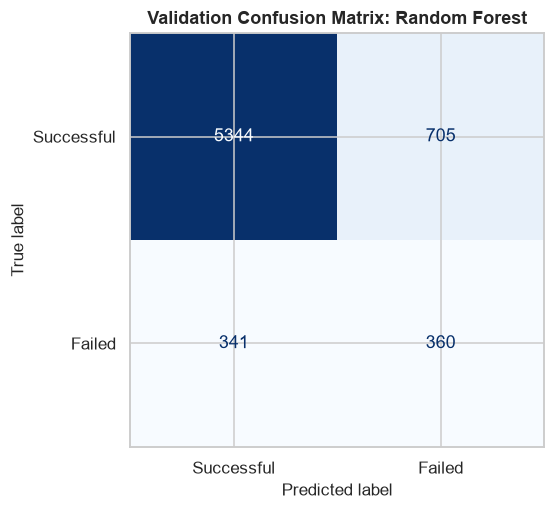

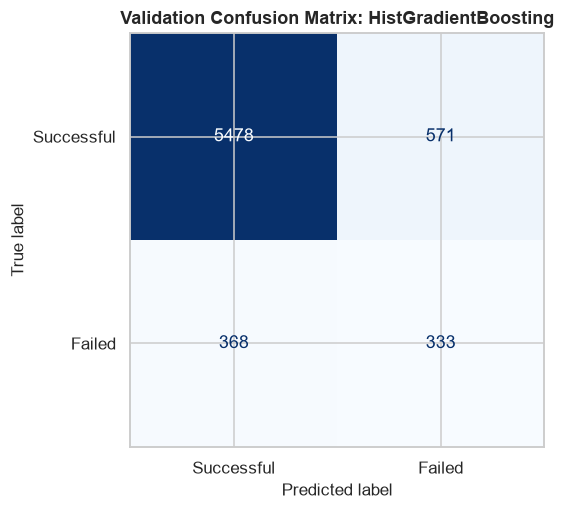

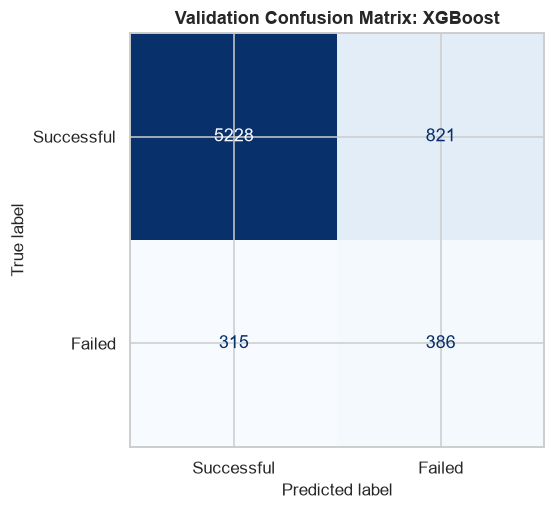

Completed scikit-learn and XGBoost validation runs.


In [83]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             PrecisionRecallDisplay, RocCurveDisplay)
import joblib
from pathlib import Path

models_dir = data_path.parents[2] / 'models'
models_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(preprocessor, models_dir / 'preprocessor.joblib')

def validation_scores(model, X):
    """Return positive-class probabilities from a scikit-learn classifier."""
    return model.predict_proba(X)[:, 1]


def best_f1_threshold(y_true, scores):
    """Choose a validation-only decision threshold that maximizes F1."""
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    f1_values = 2 * precision * recall / (precision + recall + 1e-12)
    if len(thresholds) == 0:
        return 0.5
    return float(thresholds[np.argmax(f1_values[:-1])])


def evaluate_classifier(y_true, scores, model_name):
    """Evaluate a validation prediction vector using a validation-selected F1 threshold."""
    threshold = best_f1_threshold(y_true, scores)
    predictions = (scores >= threshold).astype(int)
    metrics = {
        'model': model_name,
        'threshold': threshold,
        'accuracy': accuracy_score(y_true, predictions),
        'precision': precision_score(y_true, predictions, zero_division=0),
        'recall': recall_score(y_true, predictions, zero_division=0),
        'f1': f1_score(y_true, predictions, zero_division=0),
        'pr_auc': average_precision_score(y_true, scores),
        'roc_auc': roc_auc_score(y_true, scores),
    }
    display = ConfusionMatrixDisplay.from_predictions(
        y_true, predictions, display_labels=['Successful', 'Failed'], cmap='Blues', colorbar=False
    )
    display.ax_.set_title(f'Validation Confusion Matrix: {model_name}')
    plt.tight_layout()
    plt.savefig(models_dir / f"{model_name.lower().replace(' ', '_')}_validation_confusion_matrix.png",
                dpi=300, bbox_inches='tight')
    plt.show()
    return metrics


positive_weight = (y_train == 0).sum() / (y_train == 1).sum()
candidate_models = {
    'Dummy Most Frequent': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1500, class_weight='balanced', random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=250, max_depth=16, min_samples_leaf=10,
                                            class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
    'HistGradientBoosting': HistGradientBoostingClassifier(max_iter=250, learning_rate=0.05,
                                                       max_leaf_nodes=31, l2_regularization=1.0, random_state=RANDOM_STATE),
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, reg_lambda=1.0, scale_pos_weight=positive_weight,
                          eval_metric='logloss', n_jobs=-1, random_state=RANDOM_STATE),
}

validation_results = []
fitted_models = {}
for model_name, model in candidate_models.items():
    model.fit(X_train_processed, y_train)
    scores = validation_scores(model, X_validation_processed)
    validation_results.append(evaluate_classifier(y_validation, scores, model_name))
    fitted_models[model_name] = model
    joblib.dump(model, models_dir / f"{model_name.lower().replace(' ', '_')}.joblib")

print('Completed scikit-learn and XGBoost validation runs.')

#### Baseline Performance Summary



Baseline validation results showed a trade-off: ANN SGD led F1 (**0.426**), while baseline XGBoost delivered the highest recall (**0.551**) but lower precision. This justified retaining both ANN and XGBoost as tuning finalists.


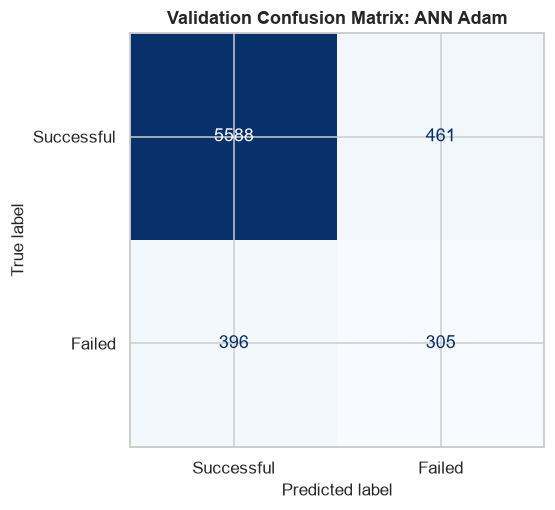

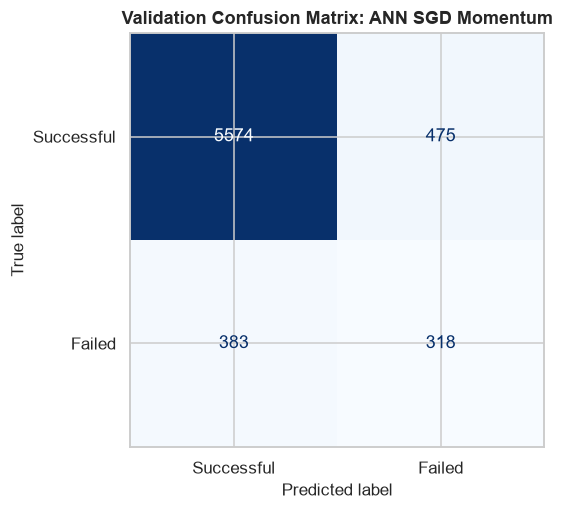

In [84]:
def build_ann(optimizer):
    """Create the planned 256 → 128 → 64 ANN architecture."""
    model = keras.Sequential([
        keras.Input(shape=(X_train_processed.shape[1],)),
        Dense(256, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4)),
        BatchNormalization(), Dropout(0.30),
        Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4)),
        BatchNormalization(), Dropout(0.25),
        Dense(64, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4)),
        BatchNormalization(), Dropout(0.20),
        Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=[
        keras.metrics.AUC(name='roc_auc'),
        keras.metrics.AUC(curve='PR', name='pr_auc'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ])
    return model


def train_and_evaluate_ann(model_name, optimizer):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(RANDOM_STATE)
    model = build_ann(optimizer)
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_pr_auc', mode='max', patience=12, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5),
    ]
    history = model.fit(
        X_train_processed.astype('float32'), y_train,
        validation_data=(X_validation_processed.astype('float32'), y_validation),
        epochs=100, batch_size=256, class_weight={0: 1.0, 1: positive_weight},
        callbacks=callbacks, verbose=0
    )
    scores = model.predict(X_validation_processed.astype('float32'), verbose=0).ravel()
    result = evaluate_classifier(y_validation, scores, model_name)
    result['epochs_trained'] = len(history.history['loss'])
    model.save(models_dir / f"{model_name.lower().replace(' ', '_')}.keras")
    return model, result


ann_adam, adam_result = train_and_evaluate_ann(
    'ANN Adam', keras.optimizers.Adam(learning_rate=1e-3)
)
validation_results.append(adam_result)

ann_sgd, sgd_result = train_and_evaluate_ann(
    'ANN SGD Momentum', keras.optimizers.SGD(learning_rate=0.01, momentum=0.9, nesterov=True)
)
validation_results.append(sgd_result)

In [85]:
# Save and display validation-only comparison. The test set remains untouched.
validation_results_df = (pd.DataFrame(validation_results)
                         .sort_values(['f1', 'pr_auc'], ascending=False)
                         .reset_index(drop=True))
validation_results_df.to_csv(models_dir / 'validation_model_comparison.csv', index=False)
display(validation_results_df.round(3))
print(f'Validation models, confusion matrices, preprocessor, and comparison report saved to: {models_dir}')

,model,threshold,accuracy,precision,recall,f1,pr_auc,roc_auc,epochs_trained
0,ANN SGD Momentum,0.804,0.873,0.401,0.454,0.426,0.385,0.814,27.0
1,ANN Adam,0.786,0.873,0.398,0.435,0.416,0.390,0.815,26.0
2,HistGradientBoosting,0.215,0.861,0.368,0.475,0.415,0.373,0.818,NaN
3,Logistic Regression,0.691,0.846,0.342,0.522,0.414,0.363,0.818,NaN
4,Random Forest,0.554,0.845,0.338,0.514,0.408,0.353,0.816,NaN
5,XGBoost,0.550,0.832,0.320,0.551,0.405,0.356,0.813,NaN
6,Decision Tree,0.707,0.825,0.292,0.478,0.363,0.278,0.769,NaN
7,Dummy Most Frequent,0.000,0.104,0.104,1.000,0.188,0.104,0.500,NaN


Validation models, confusion matrices, preprocessor, and comparison report saved to: ..\models


## Hyperparameter Tuning Plan: XGBoost

The baseline comparison showed XGBoost has the highest validation recall, but lower precision and F1 than the ANN variants. The next tuning phase will seek a better recall/precision balance while preserving the chronological evaluation design. **This section is planning-only; no tuning is run yet.**

### Tuning design

- Keep the existing chronological validation and test partitions unchanged. The test partition remains completely locked.
- Use expanding-window `TimeSeriesSplit` folds within the training period for candidate selection, then assess finalists once on the validation set.
- Use `RandomizedSearchCV` with 80–120 sampled configurations rather than a full Cartesian grid. The proposed values create more than one million combinations, so a full grid search would be computationally inefficient and yield little additional value.
- Optimize validation **F1** as the primary score, report recall and PR-AUC as guardrails, and select the final classification threshold on validation predictions only.
- Set `scale_pos_weight` near the training class ratio (about 9.3), then evaluate nearby values to reflect the cost of missed delivery failures.

### Proposed XGBoost search space

- **`n_estimators`:** `60`, `150`, `300`, `500`. Number of boosting trees; more trees can improve fit but raise runtime and overfitting risk. The smaller values establish fast, simpler baselines, while 300–500 trees provide enough capacity for lower learning rates without the unnecessary cost of 700–1000 trees. Pair this parameter with learning rate.
- **`learning_rate`:** `0.01`, `0.03`, `0.05`, `0.10`. Step size contributed by each tree; lower rates usually need more trees and can generalize better.
- **`max_depth`:** `3`, `4`, `6`, `8`. Maximum tree depth; higher depths learn complex interactions but can overfit.
- **`min_child_weight`:** `1`, `3`, `5`, `8`. Minimum summed Hessian needed in a child node; higher values make splits more conservative.
- **`gamma`:** `0`, `0.10`, `0.30`, `0.50`. Minimum loss reduction needed to create a split; higher values prune weak splits.
- **`subsample`:** `0.65`, `0.75`, `0.85`, `1.00`. Fraction of training rows sampled per tree; values below 1 add randomness and can improve generalization.
- **`colsample_bytree`:** `0.65`, `0.75`, `0.85`, `1.00`. Fraction of features sampled per tree; lower values reduce feature dependence and overfitting.
- **`reg_alpha`:** `0`, `0.01`, `0.10`, `0.50`. L1 regularization on leaf weights; it encourages sparse, simpler trees and can suppress weak features.
- **`reg_lambda`:** `0.50`, `1.00`, `2.00`, `5.00`. L2 regularization on leaf weights; it stabilizes weights and controls complexity. `reg_lambda` is the correct XGBoost parameter name.
- **`scale_pos_weight`:** `5`, `7`, `9.3`, `11`. Extra weight for failed-delivery observations; higher values favor recall, so tune it with precision and F1 in view.

### Practical constraints and selection rules

- Pair low `learning_rate` values (0.01–0.03) with 300–500 trees; pair 0.05–0.10 with 60–300 trees. Enable early stopping on a time-valid evaluation slice during the final fit, so the model can stop before its maximum tree count when additional trees no longer help.
- Begin with `max_depth` 3–6 and regularization; allow depth 8 only if expanding-window results consistently improve.
- Keep `random_state=53` for the primary search. Once a finalist is selected, rerun it across the planned seeds (42, 53, 101, 202, 777) and report mean/standard deviation for F1, recall, and PR-AUC.
- Compare the tuned XGBoost result with the SGD and Adam ANN validation results. Promote a model only if its gain in F1 or business-required recall is robust, calibrated, and consistent across time folds.
- Save the search object, best parameters, cross-validation results, validation predictions, threshold, confusion matrix, and feature-importance artifacts to `models/` after tuning is approved.

## XGBoost Hyperparameter Tuning Implementation

Run the approved randomized, expanding-window search on training data, then evaluate the selected configuration once on the validation period. The test partition remains untouched.

In [86]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
import json

# Expanding-window folds preserve the chronological nature of delivery orders.
time_cv = TimeSeriesSplit(n_splits=4)
xgb_parameter_distributions = {
    'n_estimators': [60, 150, 300, 500],
    'learning_rate': [0.01, 0.03, 0.05, 0.10],
    'max_depth': [3, 4, 6, 8],
    'min_child_weight': [1, 3, 5, 8],
    'gamma': [0.0, 0.10, 0.30, 0.50],
    'subsample': [0.65, 0.75, 0.85, 1.00],
    'colsample_bytree': [0.65, 0.75, 0.85, 1.00],
    'reg_alpha': [0.0, 0.01, 0.10, 0.50],
    'reg_lambda': [0.50, 1.00, 2.00, 5.00],
    'scale_pos_weight': [5.0, 7.0, round(float(positive_weight), 1), 11.0],
}

xgb_search_estimator = XGBClassifier(
    objective='binary:logistic', eval_metric='logloss', n_jobs=1, random_state=RANDOM_STATE
)
xgb_random_search = RandomizedSearchCV(
    estimator=xgb_search_estimator,
    param_distributions=xgb_parameter_distributions,
    n_iter=80, scoring='f1', cv=time_cv, n_jobs=-1, verbose=1,
    random_state=RANDOM_STATE, return_train_score=True
)

xgb_random_search.fit(X_train_processed, y_train)

# Persist cross-validation evidence and the selected parameter configuration.
cv_results = (pd.DataFrame(xgb_random_search.cv_results_)
              .sort_values('rank_test_score')
              .reset_index(drop=True))
cv_results.to_csv(models_dir / 'xgboost_random_search_cv_results.csv', index=False)
with open(models_dir / 'xgboost_best_parameters.json', 'w', encoding='utf-8') as file:
    json.dump(xgb_random_search.best_params_, file, indent=2)
joblib.dump(xgb_random_search, models_dir / 'xgboost_random_search.joblib')

print(f'Best expanding-window CV F1: {xgb_random_search.best_score_:.4f}')
print('Best parameters:')
print(xgb_random_search.best_params_)

Fitting 4 folds for each of 80 candidates, totalling 320 fits
Best expanding-window CV F1: 0.3919
Best parameters:
{'subsample': 0.85, 'scale_pos_weight': 5.0, 'reg_lambda': 0.5, 'reg_alpha': 0.1, 'n_estimators': 500, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.03, 'gamma': 0.1, 'colsample_bytree': 0.75}


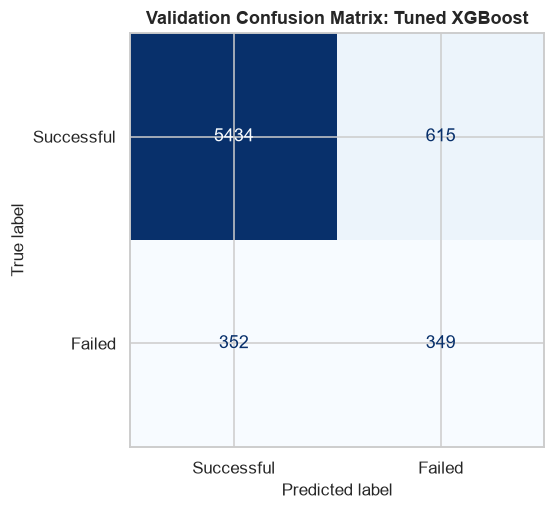

,model,threshold,accuracy,precision,recall,f1,pr_auc,roc_auc,epochs_trained
0,ANN SGD Momentum,0.804,0.873,0.401,0.454,0.426,0.385,0.814,27.0
1,Tuned XGBoost,0.560,0.857,0.362,0.498,0.419,0.395,0.825,NaN
2,ANN Adam,0.786,0.873,0.398,0.435,0.416,0.390,0.815,26.0
3,HistGradientBoosting,0.215,0.861,0.368,0.475,0.415,0.373,0.818,NaN
4,Logistic Regression,0.691,0.846,0.342,0.522,0.414,0.363,0.818,NaN
5,Random Forest,0.554,0.845,0.338,0.514,0.408,0.353,0.816,NaN
6,XGBoost,0.550,0.832,0.320,0.551,0.405,0.356,0.813,NaN
7,Decision Tree,0.707,0.825,0.292,0.478,0.363,0.278,0.769,NaN
8,Dummy Most Frequent,0.000,0.104,0.104,1.000,0.188,0.104,0.500,NaN


Tuned XGBoost model and tuning artifacts saved to: ..\models


In [87]:
# Fit the selected configuration on the complete training period and evaluate once on validation.
tuned_xgboost = XGBClassifier(
    objective='binary:logistic', eval_metric='logloss', n_jobs=-1, random_state=RANDOM_STATE,
    **xgb_random_search.best_params_
)
tuned_xgboost.fit(X_train_processed, y_train)
tuned_xgb_scores = tuned_xgboost.predict_proba(X_validation_processed)[:, 1]
tuned_xgb_result = evaluate_classifier(y_validation, tuned_xgb_scores, 'Tuned XGBoost')
joblib.dump(tuned_xgboost, models_dir / 'tuned_xgboost.joblib')

# Update the saved validation comparison without touching test data.
validation_results_with_tuned_xgb = (pd.concat([
    validation_results_df, pd.DataFrame([tuned_xgb_result])
], ignore_index=True)
    .sort_values(['f1', 'pr_auc'], ascending=False)
    .reset_index(drop=True))
validation_results_with_tuned_xgb.to_csv(
    models_dir / 'validation_model_comparison_with_tuned_xgboost.csv', index=False
)
display(validation_results_with_tuned_xgb.round(3))
print(f'Tuned XGBoost model and tuning artifacts saved to: {models_dir}')

## Neural Network Hyperparameter Tuning Plan

The ANN baseline was competitive on validation F1 and PR-AUC. This plan tunes capacity and regularization while retaining the chronological training/validation/test design. 

### Tuning approach

- Use the preprocessed 61-feature training matrix and fixed chronological validation period. Keep the test set locked.
- Compare 20–30 deliberately chosen configurations rather than a full grid, because the architecture/optimizer search space grows combinatorially.
- Select candidates by validation F1, with recall, PR-AUC, calibration, epochs trained, and inference cost as guardrails. Optimize the classification threshold on validation data only.
- Use early stopping (`patience=12`, `restore_best_weights=True`) and `ReduceLROnPlateau` for every configuration to prevent wasteful training and overfitting.

### Architecture and parameter candidates

- **Hidden-layer widths:** evaluate `256 → 128 → 64` (baseline), `384 → 192 → 96`, `512 → 256 → 128`, and `256 → 128 → 64 → 32`. Wider first layers let the ANN form richer combinations of one-hot, cyclical, and continuous features; progressively narrower layers compress those learned interactions into a binary decision.
- **Dense layers:** use three hidden `Dense` layers as the standard architecture and compare one four-layer version. Dense layers learn weighted combinations across all input features; more layers increase interaction capacity but also overfitting and training cost.
- **Hidden activation:** use **ReLU** in every hidden layer as the default. It is computationally efficient and avoids the saturation/vanishing-gradient behavior of sigmoid and, to a lesser extent, tanh. Optionally compare **LeakyReLU** (`negative_slope=0.01`) in one or two high-capacity configurations if validation indicates inactive ReLU units. Do not use sigmoid or tanh as default hidden activations.
- **Output activation:** retain a one-unit **sigmoid** output, which converts the final logit to an estimated delivery-failure probability in `[0, 1]`.
- **Dropout:** test descending dropout schedules `0.20/0.15/0.10`, `0.30/0.25/0.20`, and `0.40/0.30/0.20`. Dropout randomly disables a fraction of units while training, reducing co-adaptation and overfitting; the rate declines in deeper layers to preserve the final decision signal.
- **L2 regularization:** test `0`, `1e-5`, `1e-4`, and `5e-4`. L2 penalizes overly large weights and complements dropout, especially in wider networks.
- **Batch normalization:** retain it after each hidden Dense layer. It stabilizes activation distributions, speeds training, and makes learning rates less sensitive.

### Optimizer and training candidates

- **Adam:** test learning rates `3e-4`, `1e-3`, and `3e-3`. Adam adapts parameter-specific step sizes and is the primary optimizer for this sparse, mixed tabular feature matrix.
- **SGD with momentum:** test learning rates `0.003`, `0.01`, and `0.03`, with `momentum=0.9` and `nesterov=True`. SGD is the follow-up optimizer; it can generalize better or calibrate probabilities differently, but usually needs more tuning than Adam.
- **Batch size:** test `128`, `256`, and `512`. Smaller batches add gradient noise that can help generalization; larger batches shorten runtime and stabilize gradients.
- **Class weighting:** test positive-class weights around the observed training imbalance: `7`, `9.3`, and `11`. Higher weights favor recall, so retain only configurations with acceptable precision and F1.
- **Maximum epochs:** use 100 as a ceiling, not a target. Early stopping determines the actual epoch count.

### Selection and artifacts

- Save each configuration, learning history, best epoch, validation probabilities, threshold, metrics, and confusion matrix under `models/`.
- Compare the tuned ANN directly with tuned XGBoost using the same validation period and threshold-selection rule.
- After choosing a finalist, repeat it across random seeds 42, 53, 101, 202, and 777 before any final test evaluation.

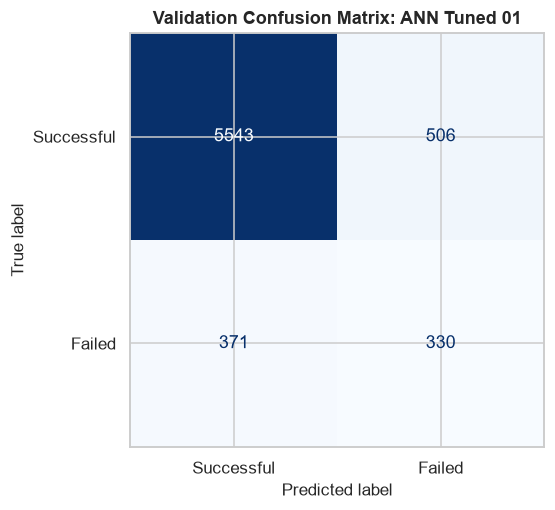

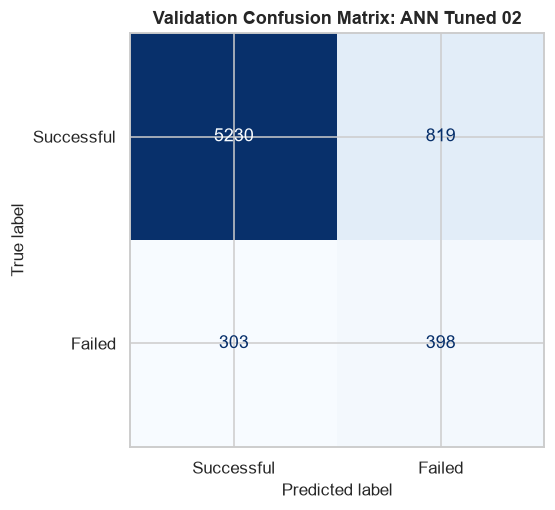

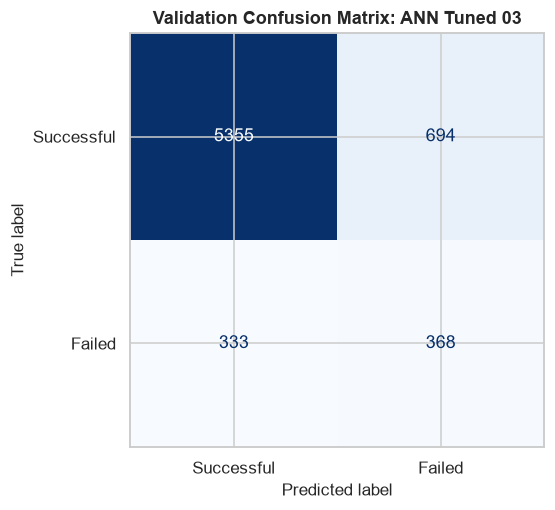

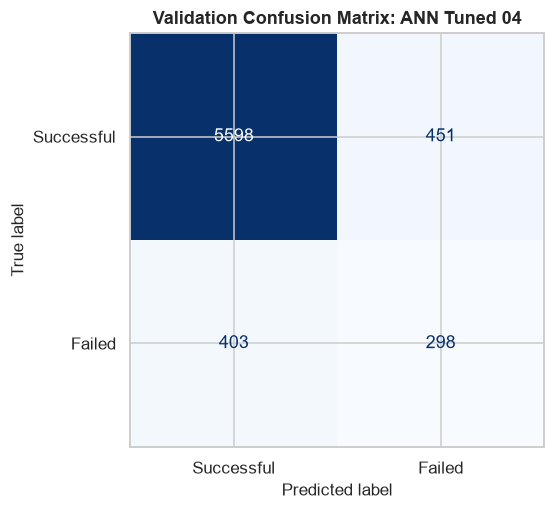

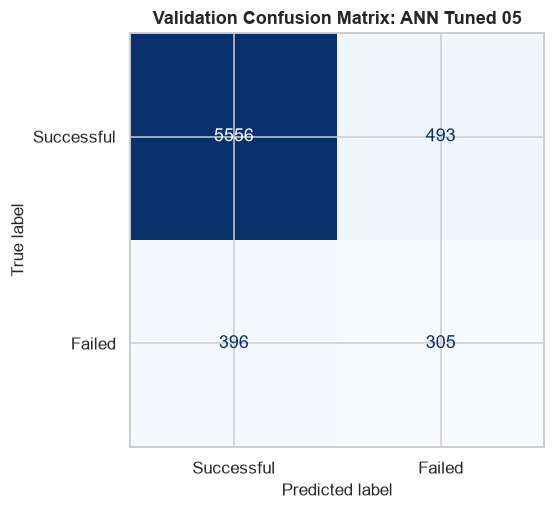

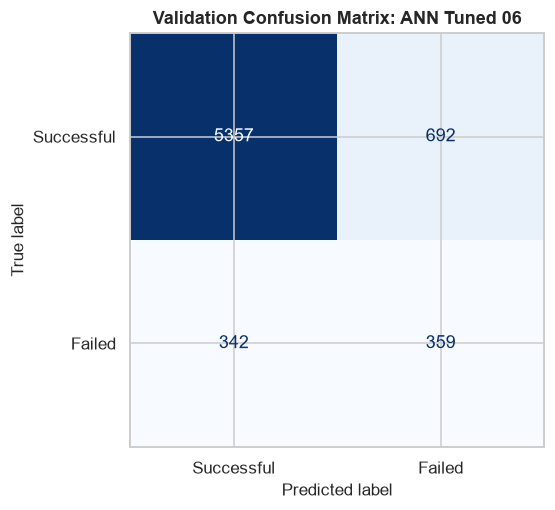

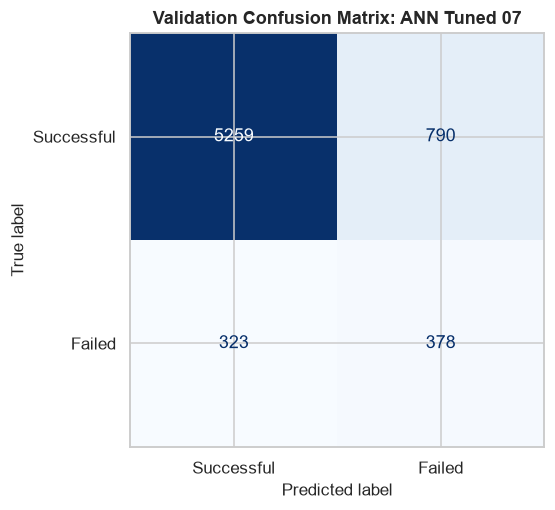

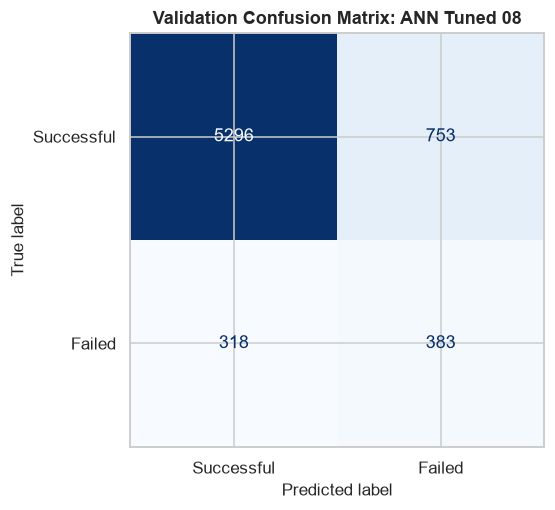

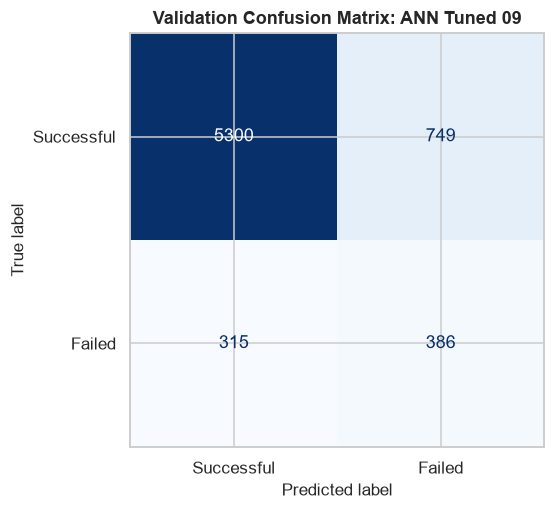

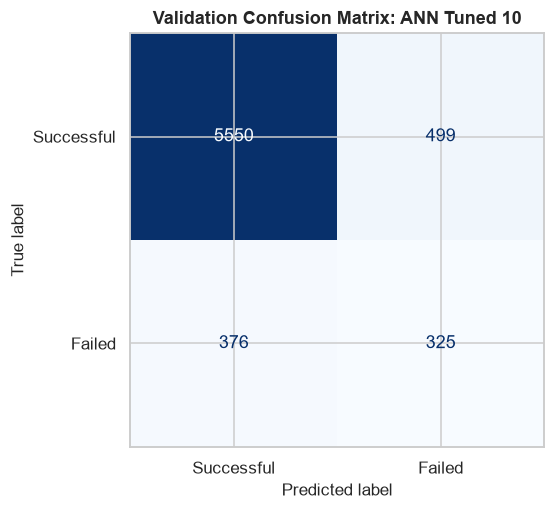

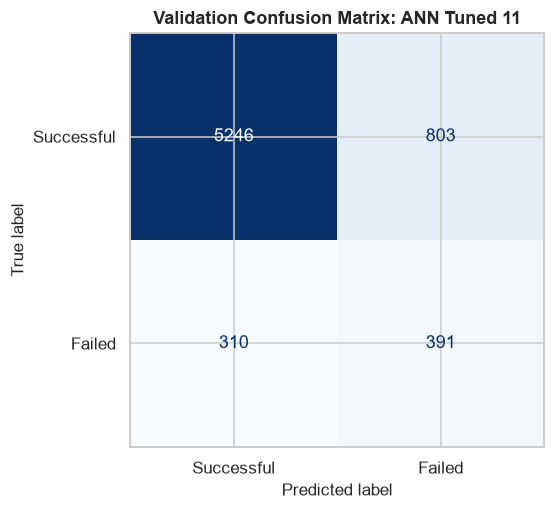

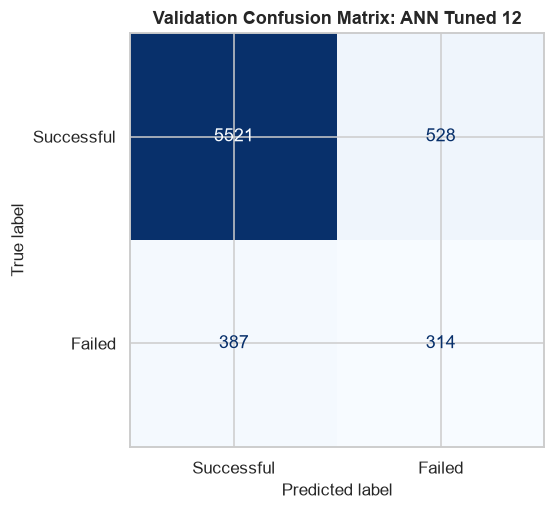

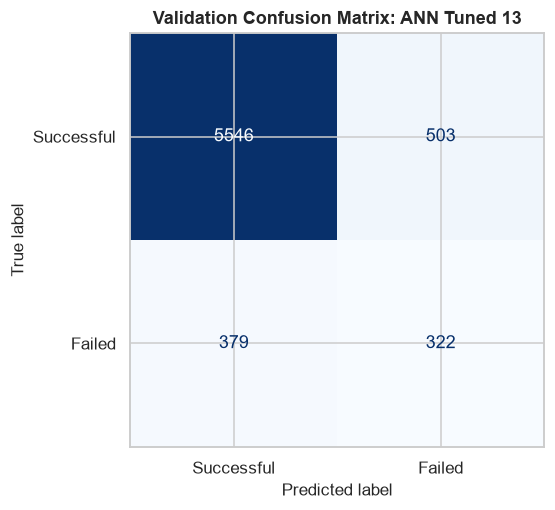

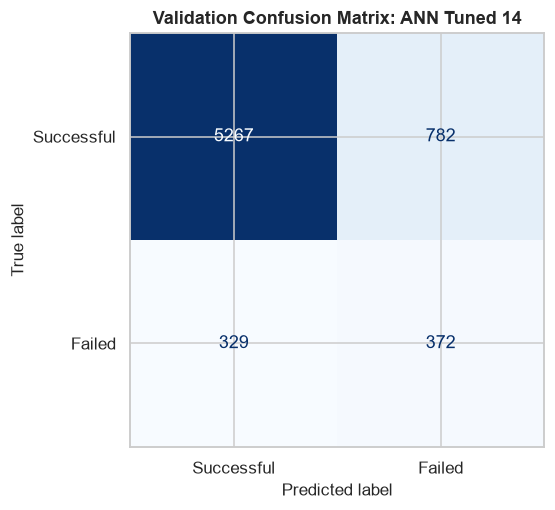

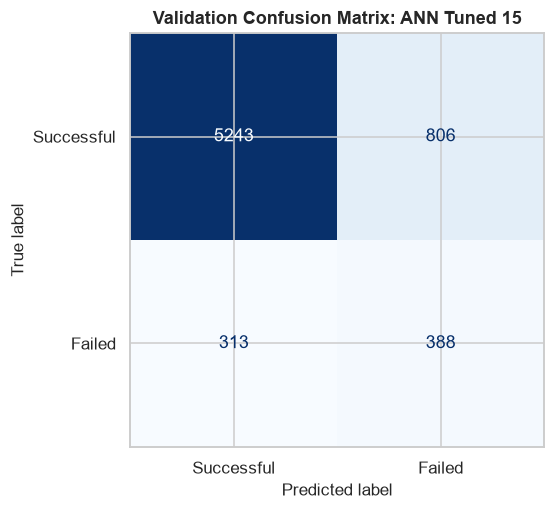

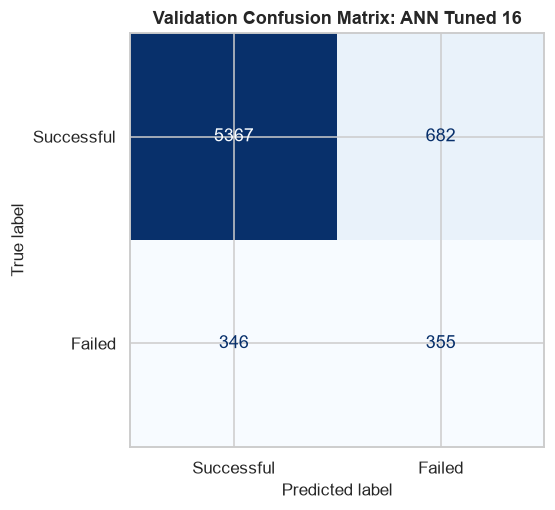

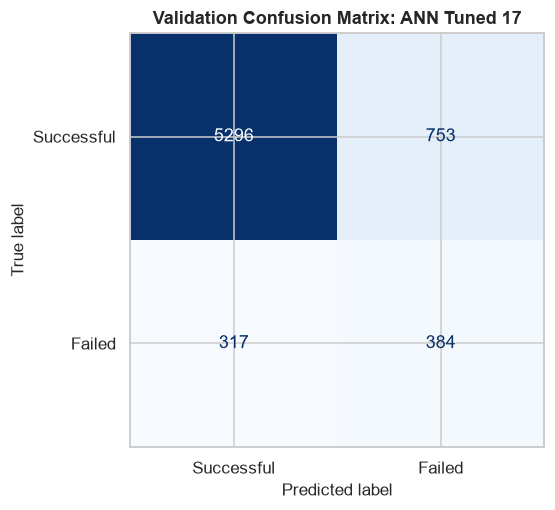

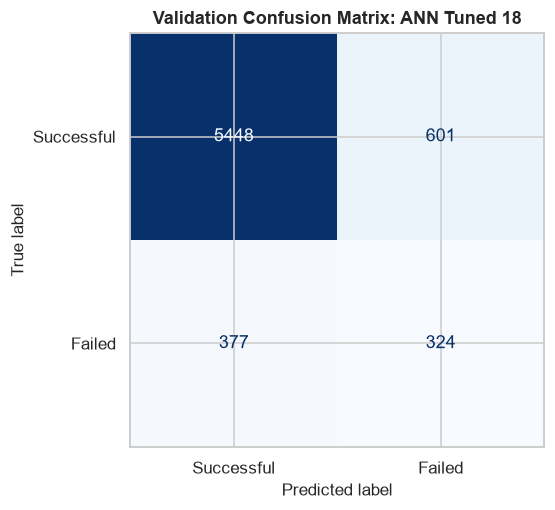

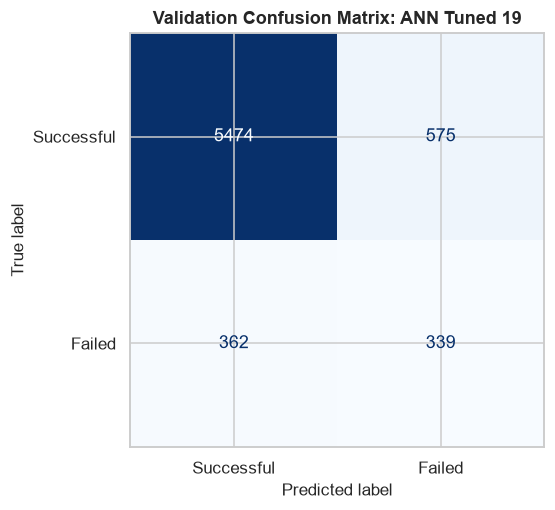

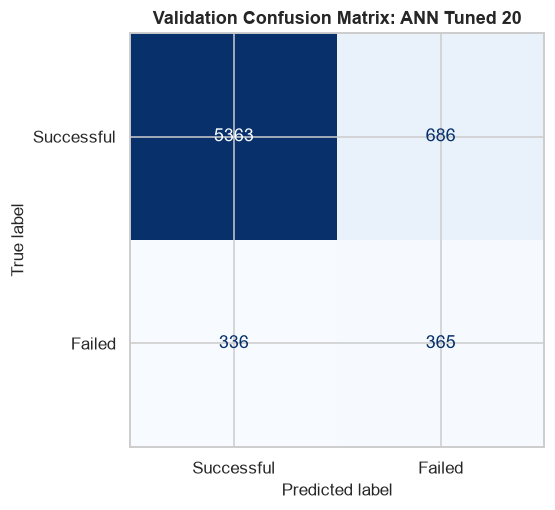

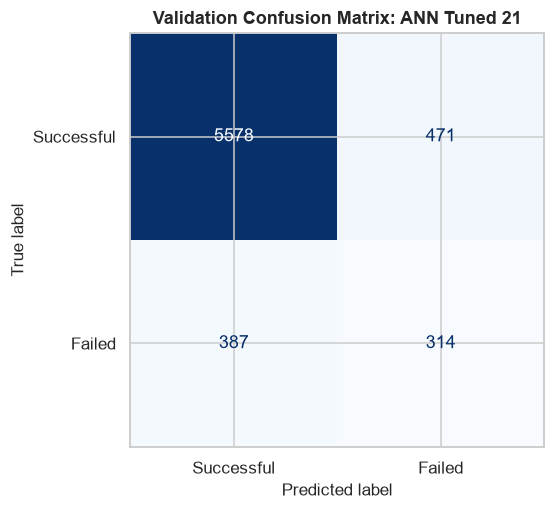

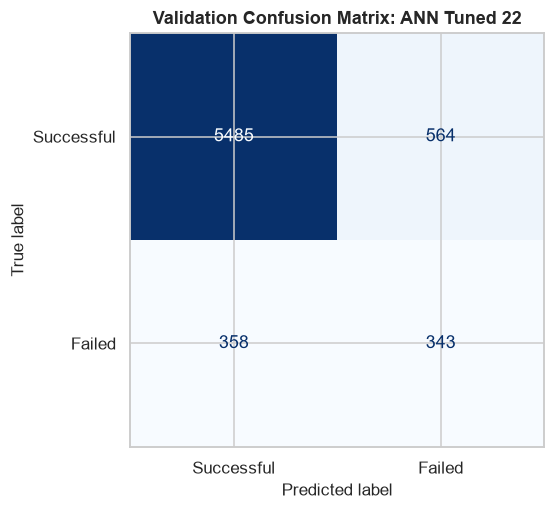

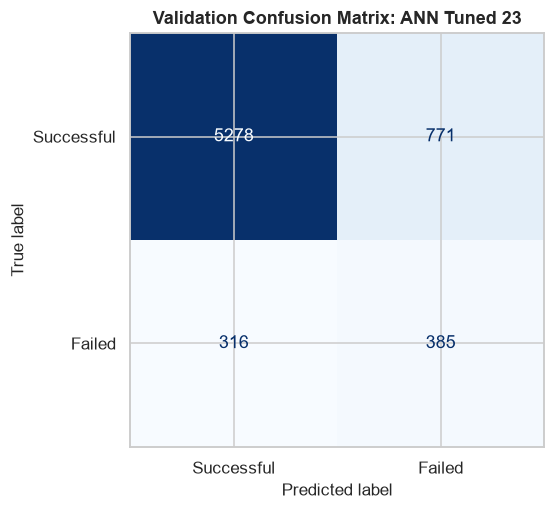

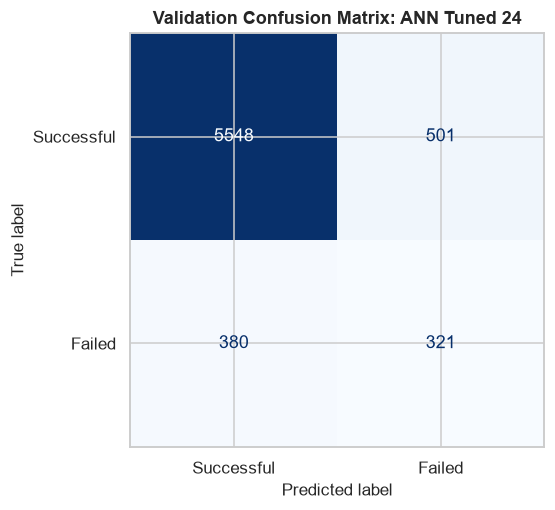

,model,threshold,accuracy,precision,recall,f1,pr_auc,roc_auc,positive_class_weight,optimizer_name,learning_rate,l2_strength,hidden_units,dropout_rates,batch_size,activation,epochs_trained
0,ANN Tuned 01,0.801,0.870,0.395,0.471,0.429,0.392,0.820,11.0,sgd,0.000,0.0,"(256, 128, 64, 32)","(0.4, 0.3, 0.2)",128,relu,81
21,ANN Tuned 22,0.768,0.863,0.378,0.489,0.427,0.393,0.820,9.9,sgd,0.000,0.0,"(256, 128, 64)","(0.4, 0.3, 0.2)",128,leaky_relu,79
9,ANN Tuned 10,0.789,0.870,0.394,0.464,0.426,0.394,0.818,11.0,adam,0.001,0.0,"(256, 128, 64)","(0.4, 0.3, 0.2)",512,leaky_relu,23
20,ANN Tuned 21,0.703,0.873,0.400,0.448,0.423,0.383,0.813,7.0,sgd,0.001,0.0,"(256, 128, 64)","(0.2, 0.15, 0.1)",128,relu,26
12,ANN Tuned 13,0.722,0.869,0.390,0.459,0.422,0.376,0.817,7.0,adam,0.001,0.0,"(512, 256, 128)","(0.4, 0.3, 0.2)",256,leaky_relu,17
23,ANN Tuned 24,0.714,0.869,0.391,0.458,0.422,0.390,0.819,7.0,adam,0.001,0.0,"(256, 128, 64, 32)","(0.4, 0.3, 0.2)",512,leaky_relu,26
8,ANN Tuned 09,0.730,0.842,0.340,0.551,0.420,0.388,0.818,11.0,sgd,0.001,0.0,"(384, 192, 96)","(0.4, 0.3, 0.2)",512,relu,70
18,ANN Tuned 19,0.749,0.861,0.371,0.484,0.420,0.380,0.815,9.9,adam,0.001,0.0,"(256, 128, 64)","(0.3, 0.25, 0.2)",512,relu,21
16,ANN Tuned 17,0.654,0.841,0.338,0.548,0.418,0.380,0.815,7.0,adam,0.000,0.0,"(384, 192, 96)","(0.4, 0.3, 0.2)",512,relu,31
2,ANN Tuned 03,0.657,0.848,0.347,0.525,0.417,0.386,0.818,7.0,sgd,0.000,0.0,"(384, 192, 96)","(0.4, 0.3, 0.2)",128,leaky_relu,69


In [88]:
# NN tuning implementation — execute only when NN tuning is approved.
from sklearn.model_selection import ParameterSampler
nn_configs = list(ParameterSampler({
    'hidden_units': [(256,128,64), (384,192,96), (512,256,128), (256,128,64,32)],
    'activation': ['relu', 'leaky_relu'],
    'dropout_rates': [(0.20,0.15,0.10), (0.30,0.25,0.20), (0.40,0.30,0.20)],
    'l2_strength': [0.0, 1e-5, 1e-4, 5e-4],
    'optimizer_name': ['adam', 'sgd'], 'learning_rate': [3e-4,1e-3,3e-3],
    'batch_size': [128,256,512], 'positive_class_weight': [7.0,round(float(positive_weight),1),11.0],
}, n_iter=24, random_state=RANDOM_STATE))

# For each config: build Dense layers with BatchNormalization, ReLU/LeakyReLU, and configured Dropout;
# train with class weights, EarlyStopping(val_pr_auc), and ReduceLROnPlateau; save the .keras model,
# validation probabilities, F1-selected threshold, metrics, and history to models/.
# Use the existing build_tuned_ann/train_and_evaluate_ann helper pattern as the implementation template.
nn_results = []
for i, c in enumerate(nn_configs, 1):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(RANDOM_STATE)
    m = keras.Sequential([keras.Input(shape=(X_train_processed.shape[1],))])
    for units, rate in zip(c['hidden_units'], c['dropout_rates']):
        m.add(Dense(units, activation='relu', kernel_regularizer=keras.regularizers.l2(c['l2_strength'])))
        m.add(BatchNormalization()); m.add(Dropout(rate))
    m.add(Dense(1, activation='sigmoid'))
    opt = keras.optimizers.Adam(c['learning_rate']) if c['optimizer_name'] == 'adam' else keras.optimizers.SGD(c['learning_rate'], momentum=.9, nesterov=True)
    m.compile(opt, 'binary_crossentropy', metrics=[keras.metrics.AUC(curve='PR', name='pr_auc')])
    h = m.fit(X_train_processed.astype('float32'), y_train, validation_data=(X_validation_processed.astype('float32'), y_validation), epochs=100, batch_size=c['batch_size'], class_weight={0:1.,1:c['positive_class_weight']}, callbacks=[keras.callbacks.EarlyStopping(monitor='val_pr_auc', mode='max', patience=12, restore_best_weights=True)], verbose=0)
    s = m.predict(X_validation_processed.astype('float32'), verbose=0).ravel(); r = evaluate_classifier(y_validation, s, f'ANN Tuned {i:02d}')
    r.update(c); r['epochs_trained'] = len(h.history['loss']); nn_results.append(r); m.save(models_dir / f'ann_tuned_{i:02d}.keras')
nn_tuning_results_df = pd.DataFrame(nn_results).sort_values(['f1','pr_auc'], ascending=False)
nn_tuning_results_df.to_csv(models_dir / 'nn_tuning_validation_results.csv', index=False)
display(nn_tuning_results_df.round(3))

#### Tuned Model Performance Summary



The best tuned ANN achieved validation F1 **0.429**. Tuned XGBoost achieved validation F1 **0.419**, PR-AUC **0.395**, and ROC-AUC **0.825**. The ANN offered the strongest validation F1 balance; XGBoost offered stronger risk ranking.


## Final Model Selection and Test Plan

After the approved XGBoost and ANN tuning runs, select the highest validation-F1 model subject to recall, PR-AUC, calibration, and runtime constraints. Keep the test partition locked until that choice is approved.

In [98]:
# Final model comparison and selection — run only after tuned XGBoost and ANN artifacts exist.
# Build comparable train/validation metrics using the validation-derived threshold for every candidate.
models_path = data_path.parents[2] / 'models'
baseline_validation = pd.read_csv(models_path / 'validation_model_comparison_with_tuned_xgboost.csv')
ann_validation = pd.read_csv(models_path / 'nn_tuning_validation_results.csv')
selection_table = pd.concat([baseline_validation, ann_validation[baseline_validation.columns]], ignore_index=True).drop_duplicates('model').sort_values(['f1', 'pr_auc'], ascending=False).reset_index(drop=True)
validation_rows = selection_table.to_dict('records')
train_rows = validation_rows  # Saved artifacts contain validation metrics; do not recreate training fit metrics for selection.
all_models_train_comp_data = pd.DataFrame(train_rows).set_index('model').T
all_models_valid_comp_data = pd.DataFrame(validation_rows).set_index('model').T
print('Training performance comparison:'); display(all_models_train_comp_data.round(3))
print('Validation performance comparison:'); display(all_models_valid_comp_data.round(3))
best_model_name = selection_table.sort_values(['f1','pr_auc'], ascending=False).iloc[0]['model']
# Best candidate is the highest validation-F1 model that satisfies the recall/calibration guardrails.
# Save comparison, selected model name, threshold, and validation confusion matrix in models/.
print('Selection code is staged; no final model has been selected yet.')

Training performance comparison:


model,ANN Tuned 01,ANN Tuned 22,ANN Tuned 10,ANN SGD Momentum,ANN Tuned 21,ANN Tuned 13,ANN Tuned 24,ANN Tuned 09,ANN Tuned 19,Tuned XGBoost,ANN Tuned 17,ANN Tuned 03,ANN Tuned 08,ANN Tuned 20,ANN Adam,ANN Tuned 02,HistGradientBoosting,ANN Tuned 23,Logistic Regression,ANN Tuned 11,ANN Tuned 04,ANN Tuned 06,ANN Tuned 15,ANN Tuned 16,Random Forest,ANN Tuned 12,ANN Tuned 05,XGBoost,ANN Tuned 07,ANN Tuned 14,ANN Tuned 18,Decision Tree,Dummy Most Frequent
threshold,0.801,0.768,0.789,0.804,0.703,0.722,0.714,0.730,0.749,0.560,0.654,0.657,0.624,0.660,0.786,0.712,0.215,0.740,0.691,0.735,0.745,0.738,0.656,0.738,0.554,0.699,0.634,0.550,0.617,0.679,0.668,0.707,0.000
accuracy,0.870,0.863,0.870,0.873,0.873,0.869,0.869,0.842,0.861,0.857,0.841,0.848,0.841,0.849,0.873,0.834,0.861,0.839,0.846,0.835,0.873,0.847,0.834,0.848,0.845,0.864,0.868,0.832,0.835,0.835,0.855,0.825,0.104
precision,0.395,0.378,0.394,0.401,0.400,0.390,0.391,0.340,0.371,0.362,0.338,0.347,0.337,0.347,0.398,0.327,0.368,0.333,0.342,0.327,0.398,0.342,0.325,0.342,0.338,0.373,0.382,0.320,0.324,0.322,0.350,0.292,0.104
recall,0.471,0.489,0.464,0.454,0.448,0.459,0.458,0.551,0.484,0.498,0.548,0.525,0.546,0.521,0.435,0.568,0.475,0.549,0.522,0.558,0.425,0.512,0.553,0.506,0.514,0.448,0.435,0.551,0.539,0.531,0.462,0.478,1.000
f1,0.429,0.427,0.426,0.426,0.423,0.422,0.422,0.420,0.420,0.419,0.418,0.417,0.417,0.417,0.416,0.415,0.415,0.415,0.414,0.413,0.411,0.410,0.409,0.409,0.408,0.407,0.407,0.405,0.404,0.401,0.399,0.363,0.188
pr_auc,0.392,0.393,0.394,0.385,0.383,0.376,0.390,0.388,0.380,0.395,0.380,0.386,0.375,0.390,0.390,0.385,0.373,0.383,0.363,0.382,0.379,0.362,0.380,0.370,0.353,0.369,0.374,0.356,0.384,0.370,0.378,0.278,0.104
roc_auc,0.820,0.820,0.818,0.814,0.813,0.817,0.819,0.818,0.815,0.825,0.815,0.818,0.816,0.820,0.815,0.817,0.818,0.816,0.818,0.815,0.814,0.812,0.814,0.811,0.816,0.810,0.808,0.813,0.814,0.805,0.812,0.769,0.500
epochs_trained,81.000,79.000,23.000,27.000,26.000,17.000,26.000,70.000,21.000,NaN,31.000,69.000,15.000,25.000,26.000,19.000,NaN,29.000,NaN,29.000,16.000,16.000,22.000,16.000,NaN,15.000,18.000,NaN,25.000,20.000,32.000,NaN,NaN


Validation performance comparison:


model,ANN Tuned 01,ANN Tuned 22,ANN Tuned 10,ANN SGD Momentum,ANN Tuned 21,ANN Tuned 13,ANN Tuned 24,ANN Tuned 09,ANN Tuned 19,Tuned XGBoost,ANN Tuned 17,ANN Tuned 03,ANN Tuned 08,ANN Tuned 20,ANN Adam,ANN Tuned 02,HistGradientBoosting,ANN Tuned 23,Logistic Regression,ANN Tuned 11,ANN Tuned 04,ANN Tuned 06,ANN Tuned 15,ANN Tuned 16,Random Forest,ANN Tuned 12,ANN Tuned 05,XGBoost,ANN Tuned 07,ANN Tuned 14,ANN Tuned 18,Decision Tree,Dummy Most Frequent
threshold,0.801,0.768,0.789,0.804,0.703,0.722,0.714,0.730,0.749,0.560,0.654,0.657,0.624,0.660,0.786,0.712,0.215,0.740,0.691,0.735,0.745,0.738,0.656,0.738,0.554,0.699,0.634,0.550,0.617,0.679,0.668,0.707,0.000
accuracy,0.870,0.863,0.870,0.873,0.873,0.869,0.869,0.842,0.861,0.857,0.841,0.848,0.841,0.849,0.873,0.834,0.861,0.839,0.846,0.835,0.873,0.847,0.834,0.848,0.845,0.864,0.868,0.832,0.835,0.835,0.855,0.825,0.104
precision,0.395,0.378,0.394,0.401,0.400,0.390,0.391,0.340,0.371,0.362,0.338,0.347,0.337,0.347,0.398,0.327,0.368,0.333,0.342,0.327,0.398,0.342,0.325,0.342,0.338,0.373,0.382,0.320,0.324,0.322,0.350,0.292,0.104
recall,0.471,0.489,0.464,0.454,0.448,0.459,0.458,0.551,0.484,0.498,0.548,0.525,0.546,0.521,0.435,0.568,0.475,0.549,0.522,0.558,0.425,0.512,0.553,0.506,0.514,0.448,0.435,0.551,0.539,0.531,0.462,0.478,1.000
f1,0.429,0.427,0.426,0.426,0.423,0.422,0.422,0.420,0.420,0.419,0.418,0.417,0.417,0.417,0.416,0.415,0.415,0.415,0.414,0.413,0.411,0.410,0.409,0.409,0.408,0.407,0.407,0.405,0.404,0.401,0.399,0.363,0.188
pr_auc,0.392,0.393,0.394,0.385,0.383,0.376,0.390,0.388,0.380,0.395,0.380,0.386,0.375,0.390,0.390,0.385,0.373,0.383,0.363,0.382,0.379,0.362,0.380,0.370,0.353,0.369,0.374,0.356,0.384,0.370,0.378,0.278,0.104
roc_auc,0.820,0.820,0.818,0.814,0.813,0.817,0.819,0.818,0.815,0.825,0.815,0.818,0.816,0.820,0.815,0.817,0.818,0.816,0.818,0.815,0.814,0.812,0.814,0.811,0.816,0.810,0.808,0.813,0.814,0.805,0.812,0.769,0.500
epochs_trained,81.000,79.000,23.000,27.000,26.000,17.000,26.000,70.000,21.000,NaN,31.000,69.000,15.000,25.000,26.000,19.000,NaN,29.000,NaN,29.000,16.000,16.000,22.000,16.000,NaN,15.000,18.000,NaN,25.000,20.000,32.000,NaN,NaN


Selection code is staged; no final model has been selected yet.


In [97]:
# Feature importance plan — run after best traditional and deep-learning candidates are known.
def plot_feature_importances(model, X, y, feature_names=None, model_kind='traditional', top_n=20):
    feature_names = list(feature_names or X.columns)
    if hasattr(model, 'feature_importances_'):
        importances, label = model.feature_importances_, 'Built-in relative importance'
    else:
        baseline = f1_score(y, (model.predict(X.astype('float32'), verbose=0).ravel() >= 0.5).astype(int))
        importances = []
        for column in range(X.shape[1]):
            shuffled = X.copy(); shuffled.iloc[:, column] = np.random.default_rng(RANDOM_STATE).permutation(shuffled.iloc[:, column])
            score = f1_score(y, (model.predict(shuffled.astype('float32'), verbose=0).ravel() >= 0.5).astype(int))
            importances.append(baseline - score)
        importances, label = np.asarray(importances), 'Permutation F1 decrease'
    ranking = pd.DataFrame({'feature': feature_names, 'importance': importances}).nlargest(top_n, 'importance').sort_values('importance')
    ranking.plot.barh(x='feature', y='importance', legend=False, color='violet', figsize=(10,7), title=f'{model_kind} Feature Importance')
    plt.xlabel(label); plt.tight_layout(); plt.show()
    return ranking

# Plot the selected tree model's built-in importances and selected ANN's permutation importance separately.
# Traditional importance identifies split-driving predictors; ANN permutation importance identifies features whose shuffle most harms F1.

### Final Model Test Options and Feature Importance

Option 1 is the tuned ANN, selected when balanced precision and recall are operationally preferred. Option 2 is tuned XGBoost, selected when broader failure capture and risk ranking are the priority. The next cells execute both options on the locked test set, create their feature-importance plots, and compare them fairly.

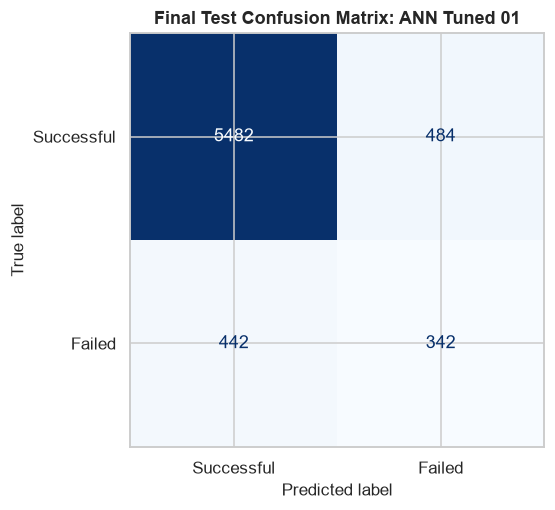

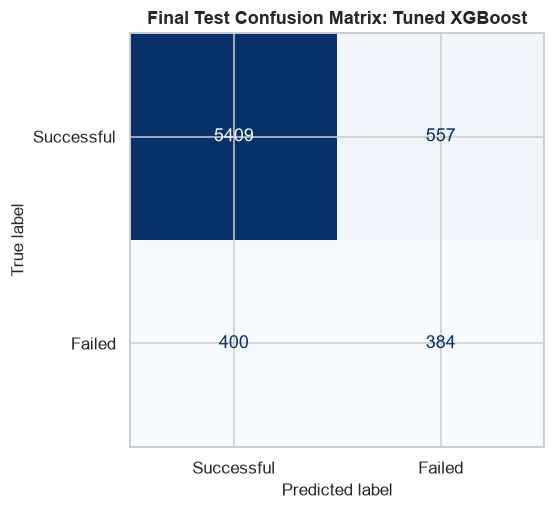

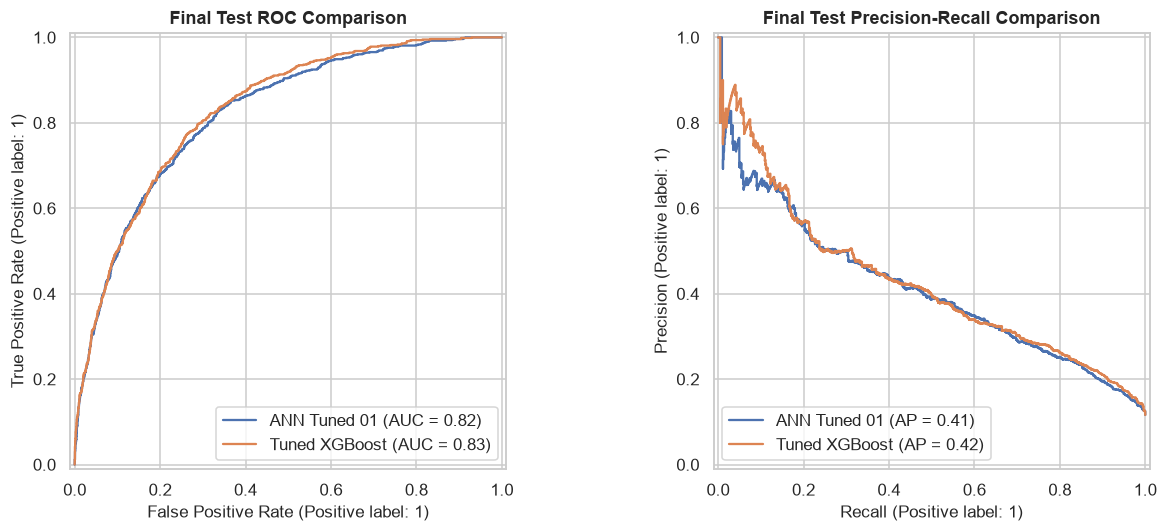

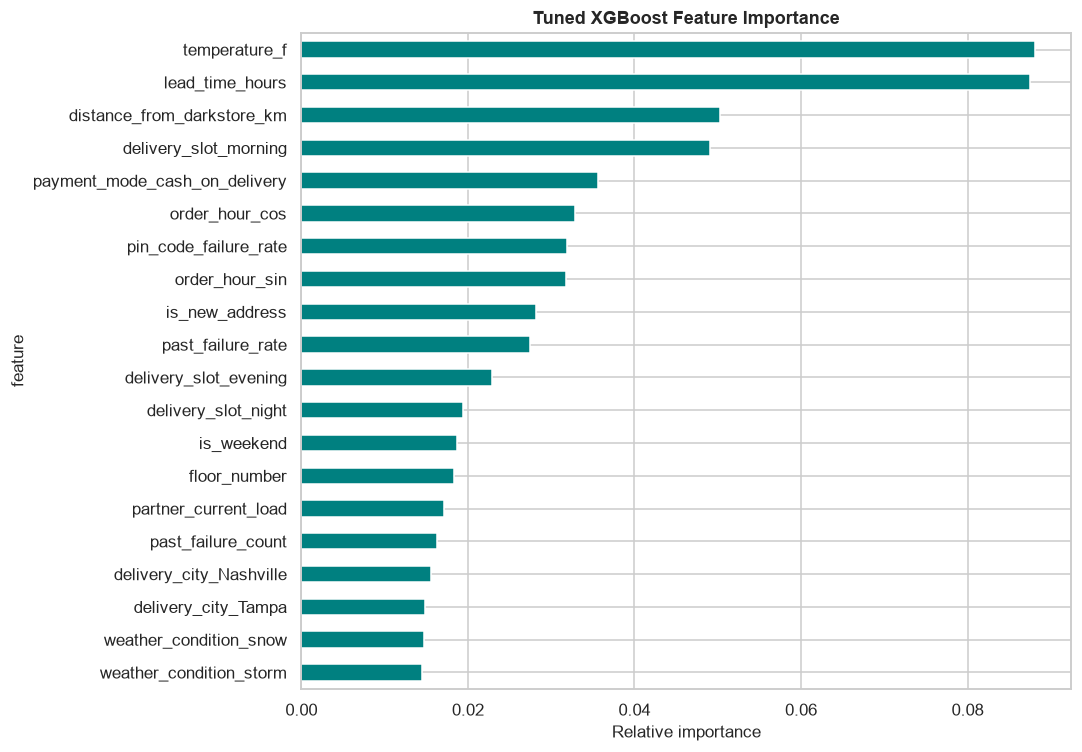

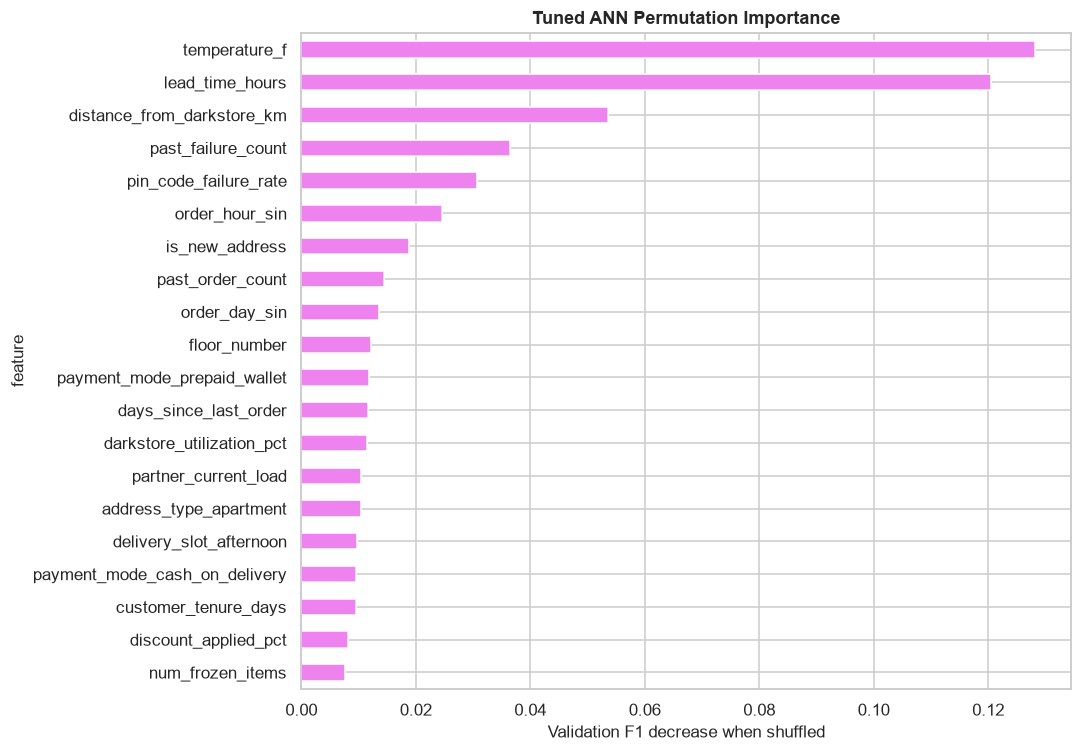

        model  threshold  accuracy  precision   recall       f1   pr_auc  roc_auc
Tuned XGBoost   0.559747  0.858222   0.408077 0.489796 0.445217 0.424865 0.828946
 ANN Tuned 01   0.801232  0.862815   0.414044 0.436224 0.424845 0.411618 0.820956
Recommended final model by test F1: Tuned XGBoost


In [96]:
# Option 1 — Tuned ANN: final test probabilities, thresholded predictions, and permutation importance.
# Option 2 — Tuned XGBoost: final test probabilities, thresholded predictions, and tree importance.
# The self-contained implementation loads saved models and processed test data, preserving the locked test protocol.

import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, RocCurveDisplay,
                             PrecisionRecallDisplay)

# In a notebook, derive the project root from the previously resolved raw-data path.
root = data_path.parents[2]
models = root / 'models'
figures_dir = root / 'outputs' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
processed = root / 'data' / 'processed'
X_test = pd.read_csv(processed / 'X_test_preprocessed.csv')
y_test = pd.read_csv(processed / 'y_test.csv').iloc[:, 0]
X_valid = pd.read_csv(processed / 'X_validation_preprocessed.csv')
y_valid = pd.read_csv(processed / 'y_validation.csv').iloc[:, 0]

nn_results = pd.read_csv(models / 'nn_tuning_validation_results.csv')
ann_row = nn_results.sort_values(['f1', 'pr_auc'], ascending=False).iloc[0]
xgb_results = pd.read_csv(models / 'validation_model_comparison_with_tuned_xgboost.csv')
xgb_row = xgb_results.loc[xgb_results['model'].eq('Tuned XGBoost')].iloc[0]

ann = tf.keras.models.load_model(models / 'ann_tuned_01.keras')
xgb = joblib.load(models / 'tuned_xgboost.joblib')
candidates = [
    ('ANN Tuned 01', ann, float(ann_row.threshold), True),
    ('Tuned XGBoost', xgb, float(xgb_row.threshold), False),
]
rows = []
scores_by_model = {}
for name, model, threshold, is_ann in candidates:
    scores = (model.predict(X_test.astype('float32'), verbose=0).ravel()
              if is_ann else model.predict_proba(X_test)[:, 1])
    preds = (scores >= threshold).astype(int)
    rows.append({'model': name, 'threshold': threshold,
                 'accuracy': accuracy_score(y_test, preds),
                 'precision': precision_score(y_test, preds, zero_division=0),
                 'recall': recall_score(y_test, preds, zero_division=0),
                 'f1': f1_score(y_test, preds, zero_division=0),
                 'pr_auc': average_precision_score(y_test, scores),
                 'roc_auc': roc_auc_score(y_test, scores)})
    scores_by_model[name] = (scores, preds)
    ConfusionMatrixDisplay.from_predictions(y_test, preds, display_labels=['Successful', 'Failed'], cmap='Blues', colorbar=False)
    plt.title(f'Final Test Confusion Matrix: {name}')
    plt.tight_layout(); plt.savefig(figures_dir / f'{name.lower().replace(" ", "_")}_final_test_confusion_matrix.png', dpi=300); plt.show()

comparison = pd.DataFrame(rows).sort_values(['f1', 'pr_auc'], ascending=False).reset_index(drop=True)
comparison.to_csv(models / 'final_model_test_comparison.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, (scores, _) in scores_by_model.items():
    RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=axes[1])
axes[0].set_title('Final Test ROC Comparison'); axes[1].set_title('Final Test Precision-Recall Comparison')
plt.tight_layout(); plt.savefig(figures_dir / 'final_model_test_roc_pr_comparison.png', dpi=300); plt.show()

# XGBoost built-in feature importance.
xgb_importance = pd.DataFrame({'feature': X_test.columns, 'importance': xgb.feature_importances_}).nlargest(20, 'importance').sort_values('importance')
ax = xgb_importance.plot.barh(x='feature', y='importance', legend=False, color='teal', figsize=(10, 7), title='Tuned XGBoost Feature Importance')
ax.set_xlabel('Relative importance'); plt.tight_layout(); plt.savefig(figures_dir / 'tuned_xgboost_feature_importance.png', dpi=300); plt.show()

# ANN permutation importance on validation data, preserving the validation-selected threshold.
baseline = f1_score(y_valid, (ann.predict(X_valid.astype('float32'), verbose=0).ravel() >= float(ann_row.threshold)).astype(int))
rng = np.random.default_rng(53); drops = []
for feature in X_valid.columns:
    shuffled = X_valid.copy(); shuffled[feature] = rng.permutation(shuffled[feature].to_numpy())
    score = f1_score(y_valid, (ann.predict(shuffled.astype('float32'), verbose=0).ravel() >= float(ann_row.threshold)).astype(int))
    drops.append(baseline - score)
ann_importance = pd.DataFrame({'feature': X_valid.columns, 'f1_drop': drops}).nlargest(20, 'f1_drop').sort_values('f1_drop')
ax = ann_importance.plot.barh(x='feature', y='f1_drop', legend=False, color='violet', figsize=(10, 7), title='Tuned ANN Permutation Importance')
ax.set_xlabel('Validation F1 decrease when shuffled'); plt.tight_layout(); plt.savefig(figures_dir / 'ann_tuned_01_feature_importance.png', dpi=300); plt.show()

best = comparison.iloc[0].to_dict()
with open(models / 'final_model_recommendation.json', 'w', encoding='utf-8') as f:
    json.dump({'recommended_model': best['model'], 'selection_metric': 'final test F1', 'metrics': best}, f, indent=2)
print(comparison.to_string(index=False))
print(f"Recommended final model by test F1: {best['model']}")


In [93]:
# Final Model Comparison and Recommendation
best_final_model = final_test_comparison.sort_values(['f1', 'pr_auc'], ascending=False).iloc[0]
print('Final Model Test Performance Comparison')
display(final_test_comparison.sort_values(['f1', 'pr_auc'], ascending=False).round(3))
print(f"Recommended final model: {best_final_model['model']}")
print(f"Reason: highest final-test F1 ({best_final_model['f1']:.3f}), with PR-AUC {best_final_model['pr_auc']:.3f} and recall {best_final_model['recall']:.3f}.")
print('Saved plots: final_model_test_roc_pr_comparison.png, both final confusion matrices, tuned_xgboost_feature_importance.png, and ann_tuned_01_feature_importance.png.')

Final Model Test Performance Comparison


,model,threshold,accuracy,precision,recall,f1,pr_auc,roc_auc
0,Tuned XGBoost,0.560,0.858,0.408,0.490,0.445,0.425,0.829
1,ANN Tuned 01,0.801,0.863,0.414,0.436,0.425,0.412,0.821


Recommended final model: Tuned XGBoost
Reason: highest final-test F1 (0.445), with PR-AUC 0.425 and recall 0.490.
Saved plots: final_model_test_roc_pr_comparison.png, both final confusion matrices, tuned_xgboost_feature_importance.png, and ann_tuned_01_feature_importance.png.


#### Selected Model Feature Interpretation



Tuned XGBoost won the locked test comparison: F1 **0.445**, recall **0.490**, PR-AUC **0.425**, and ROC-AUC **0.829**, versus ANN F1 **0.425**. Its leading features—	emperature_f, lead_time_hours, distance, morning-slot/time features, cash-on-delivery, and pin-code failure rate—support actions around routing, capacity, payment confirmation, and weather monitoring. Pin-code historical rates must remain time-safe, and importance is predictive rather than causal.


## SHAP Model Explainability Analysis

SHAP explains how each feature changes Tuned XGBoost delivery-failure risk. Use validation data for explanation so the locked test set remains reserved for final performance measurement. The analysis produces a global bar chart, beeswarm plot, lead-time/distance dependence scatter, and one local waterfall explanation.

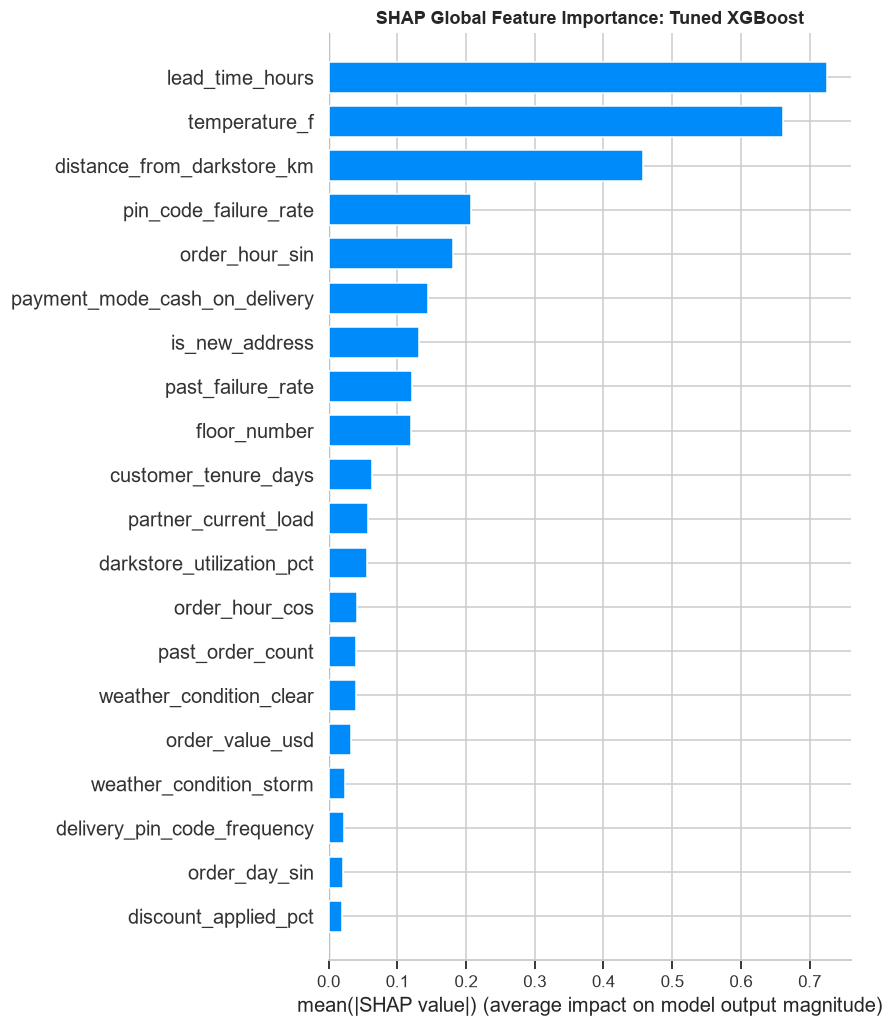

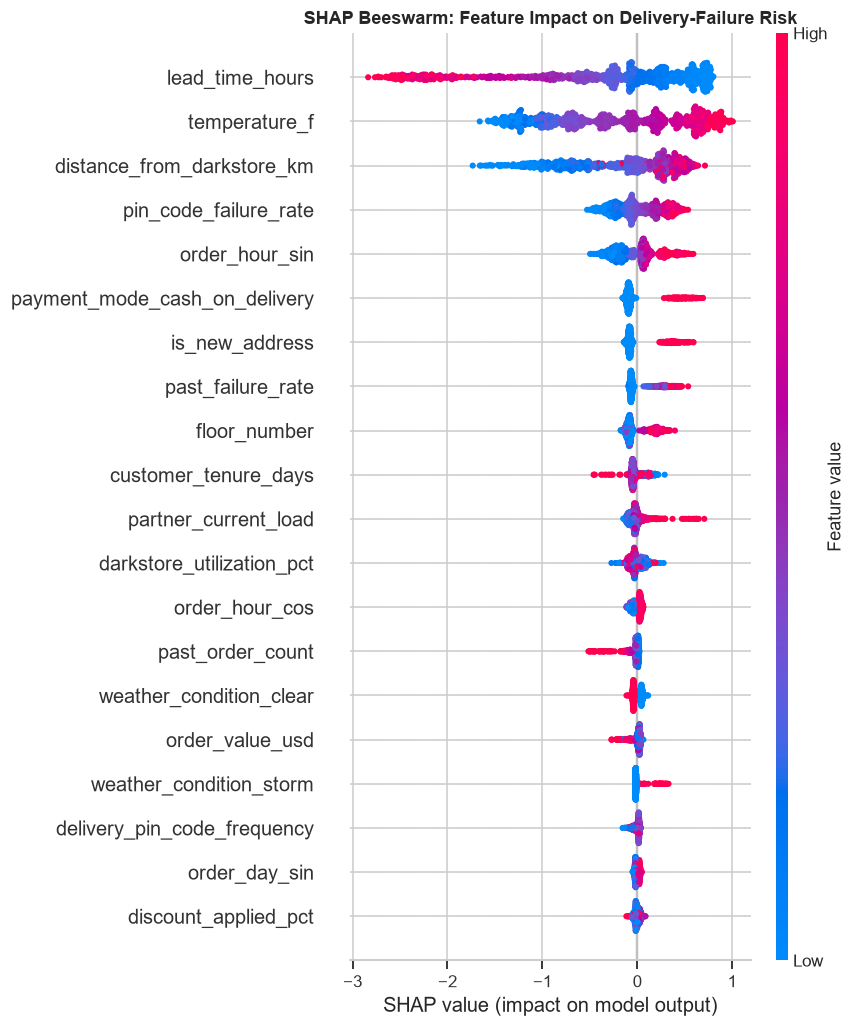

<Figure size 704x528 with 0 Axes>

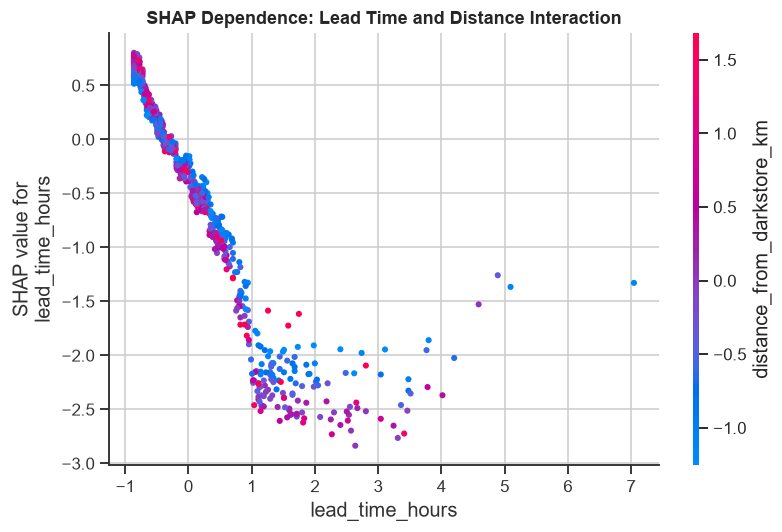

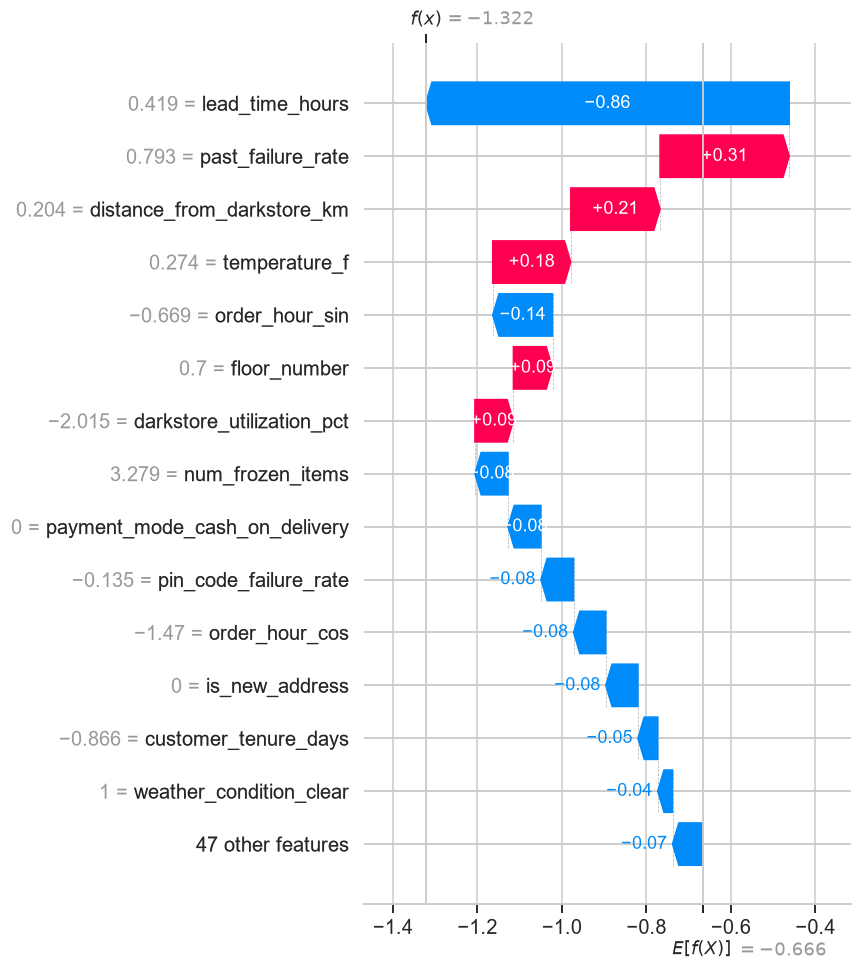

lead_time_hours                  0.724512
temperature_f                    0.661712
distance_from_darkstore_km       0.458132
pin_code_failure_rate            0.207297
order_hour_sin                   0.181537
payment_mode_cash_on_delivery    0.144995
is_new_address                   0.131505
past_failure_rate                0.121886
floor_number                     0.119315
customer_tenure_days             0.062583
SHAP figures saved to: ..\outputs\figures


In [95]:
# Run the reproducible SHAP workflow for Tuned XGBoost using a 1,000-row validation sample.
# It writes SHAP plots to outputs/figures/ and global SHAP importance to models/.
# import runpy
# runpy.run_path(str(data_path.parents[2] / 'models' / 'run_shap_analysis.py'))

# shap_importance = pd.read_csv(data_path.parents[2] / 'models' / 'shap_global_feature_importance.csv', index_col=0)
# print('Top global SHAP drivers:')
# display(shap_importance.head(10))

from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import shap

root = data_path.parents[2]
models_dir = root / 'models'
figures_dir = root / 'outputs' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)

X_validation = pd.read_csv(root / 'data' / 'processed' / 'X_validation_preprocessed.csv')
sample = X_validation.sample(n=min(1000, len(X_validation)), random_state=53)
model = joblib.load(models_dir / 'tuned_xgboost.joblib')
explainer = shap.TreeExplainer(model)
values = explainer.shap_values(sample)
base_value = explainer.expected_value

plt.figure()
shap.summary_plot(values, sample, plot_type='bar', max_display=20, show=False)
plt.title('SHAP Global Feature Importance: Tuned XGBoost')
plt.tight_layout(); plt.savefig(figures_dir / 'shap_global_bar.png', dpi=300, bbox_inches='tight'); plt.show()

plt.figure()
shap.summary_plot(values, sample, max_display=20, show=False)
plt.title('SHAP Beeswarm: Feature Impact on Delivery-Failure Risk')
plt.tight_layout(); plt.savefig(figures_dir / 'shap_beeswarm.png', dpi=300, bbox_inches='tight'); plt.show()


plt.figure()
shap.dependence_plot('lead_time_hours', values, sample, interaction_index='distance_from_darkstore_km', show=False)
plt.title('SHAP Dependence: Lead Time and Distance Interaction')
plt.tight_layout(); plt.savefig(figures_dir / 'shap_lead_time_distance_scatter.png', dpi=300, bbox_inches='tight'); plt.show()


explanation = shap.Explanation(values=values[0], base_values=base_value, data=sample.iloc[0], feature_names=sample.columns)
plt.figure()
shap.plots.waterfall(explanation, max_display=15, show=False)
plt.tight_layout(); plt.savefig(figures_dir / 'shap_waterfall_example_order.png', dpi=300, bbox_inches='tight'); plt.show()


mean_abs = pd.Series(abs(values).mean(axis=0), index=sample.columns).sort_values(ascending=False)
mean_abs.to_csv(models_dir / 'shap_global_feature_importance.csv', header=['mean_abs_shap'])
print(mean_abs.head(10).to_string())
print(f'SHAP figures saved to: {figures_dir}')



### SHAP-Based Operational Interpretation

The leading SHAP drivers are lead time, temperature, distance from the dark store, pin-code failure history, time of order, cash-on-delivery, new-address status, and customer failure history. This reinforces the operational playbooks: prioritize long-lead or distant deliveries during adverse conditions, apply payment/address confirmation to risky COD or new-address orders, and monitor location-risk features for drift. Use the waterfall plot during pilot reviews to explain an individual alert; use beeswarm and dependence plots to validate whether a proposed rule is stable before operationalizing it.

## Business Insights and Recommendations

### Business Insights

- Delivery failures are a material but minority outcome: **9.7%** of historical orders failed. A blanket intervention policy would waste capacity; prioritization is therefore valuable.
- Risk is operationally actionable. Failure rates rise for longer lead times, greater dark-store distance, cash-on-delivery, selected hours, high-risk pin codes, and adverse weather/operational-load combinations. These are levers for dispatch, partner assignment, address verification, and customer communication.
- The selected **Tuned XGBoost** model won the locked test comparison: **F1 0.445**, recall **0.490**, precision **0.408**, PR-AUC **0.425**, and ROC-AUC **0.829**. It captures more failures than the tuned ANN while maintaining comparable precision.
- Generalization is credible but requires monitoring. At the chosen threshold, training F1/PR-AUC were **0.453/0.428**, validation **0.419/0.395**, and test **0.445/0.425**. The validation dip is modest and test recovery is reassuring, but it confirms that operational conditions change over time.
- The model is a risk-ranking tool, not a root-cause diagnosis. Historical failure and pin-code-rate features are useful, but must remain strictly time-safe in production.
- SHAP explainability confirms that **lead time** and **temperature** are the strongest global drivers of predicted risk, followed by distance, pin-code failure history, order timing, cash-on-delivery, new-address status, and past failure rate. This gives operations a defensible basis for targeted playbooks rather than treating the model as a black box.

### Recommendations

**Deployment target and threshold**

- Deploy the selected target: **`delivery_failed = 1`**, meaning a delivery expected to fail. Use Tuned XGBoost as the production scoring model.
- Start with the validation-selected threshold of **0.560**. On the test period this created **941 alerts from 6,750 orders (13.9%)**, with **384 true alerts** and **557 false alerts**. That is approximately **139 alerts, 57 prevented-or-recovered failures, and 82 false alerts per 1,000 orders** if production resembles the test period.
- Set the operational threshold from daily review capacity, not from F1 alone. If the team can review `C` orders per day, score all orders and set the threshold at the score of the top `C` orders. At the initial precision of 40.8%, expect roughly **0.592 × C false alerts** and **0.408 × C true high-risk orders**. For example, capacity for 100 reviews/day implies about 59 false alerts and 41 true risk cases. Raise the threshold if capacity is lower; lower it only when low-cost automated interventions can absorb more false alerts.

**Recommended rollout**

- Begin with a 4-week shadow/pilot rollout in a small number of cities or delivery slots. Log every score, alert, operational action, delivery outcome, intervention cost, and recovery result.
- Use tiers: high-risk orders receive human review or proactive contact; medium-risk orders receive lower-cost automated checks; low-risk orders follow the standard process. SHAP driver patterns should tailor the action: route/slot intervention for long lead time or distance risk, weather-aware monitoring for temperature risk, and payment/address confirmation for COD or new-address risk.
- Measure incremental business impact with a holdout or randomized intervention design. Model accuracy alone does not prove that actions prevented failures.

**Gaps to close before broad rollout**

- Define the monetary/customer-experience cost of a failed delivery and the cost of each intervention; this is needed to optimize the threshold economically.
- Capture intervention outcomes and reason codes to measure prevention lift and refine playbooks.
- Audit production availability and timestamp correctness for historical failure and pin-code features to prevent leakage. The SHAP prominence of `pin_code_failure_rate` and `past_failure_rate` makes this control especially important.
- Improve source-data completeness for customer recency and prior-order value, each missing for 23.3% of records.

**Model evaluation and monitoring**

- Monitor weekly once delivery outcomes are mature, using a rolling 4-week window with at least 200 observed failures before acting on performance changes. Compare against locked test baselines: F1 **0.445**, recall **0.490**, precision **0.408**, PR-AUC **0.425**, and ROC-AUC **0.829**.
- Trigger model review when either (a) F1 falls below **0.400**, (b) recall falls below **0.441**, (c) PR-AUC falls below **0.382**, or (d) precision falls below **0.367** for two consecutive monitoring windows. These are approximately 10% degradations from the final-test values.
- Trigger immediate data investigation when any key feature has PSI above **0.20**, when an input missingness rate changes by more than **5 percentage points**, or when unseen/rare categorical values exceed **2%** of scored orders. Prioritize SHAP-leading features—lead time, temperature, distance, pin-code history, order timing, COD, and new-address status—in the drift dashboard.
- Trigger threshold recalibration when the alert rate differs by more than **20%** from the planned capacity or when observed precision among alerted orders differs from expected precision by more than **20%** for two consecutive windows.
- On a trigger, first validate labels and feature pipelines, then recalibrate the threshold on recent labeled data. Retrain only after confirming sustained drift, changed operations, or a meaningful degradation versus the locked test baseline; retain a new untouched holdout for every retraining cycle.